# Import libraries and seurat object  

In [65]:
library(Seurat)
library(ggplot2)
library(dplyr)
library(tibble)
library(purrr)
library(patchwork)
library(rlang)
library(ggrepel)
library(tidyr)
library(tibble)

## Set the working directory

In [66]:
setwd("/workspaces/microsplit_DOL")

# Load seurat object

In [67]:
seurat_obj <- readRDS("data/big_data/RDS_files/SeuratObject_All_Metadata.rds")

# Fonction 

## Summarise Seurat object

In [68]:
summarize_seurat <- function(seurat_obj,
                             group_by = NULL,
                             output = c("both", "global", "grouped"),
                             assay = "RNA",
                             slot = "counts",
                             export = c("none", "csv", "xlsx"),
                             file_path = NULL,
                             auto_filename = TRUE) {

  output <- match.arg(output)
  export <- match.arg(export)

  # Récupérer le nom de l'objet Seurat sous forme de texte
  seurat_name <- deparse(substitute(seurat_obj))

  meta_data <- seurat_obj@meta.data
  counts_matrix <- GetAssayData(seurat_obj, assay = assay, layer = slot)

  ngene_total <- sum(rowSums(counts_matrix > 0) > 0)

  # --- GLOBAL STATS ---
  global_stats <- tibble(
    Sample_ID = "Global",
    n_cells = ncol(counts_matrix),
    n_genes_detected = ngene_total,
    gene_detection_ratio = round(1, 3),
    sum_nCount_RNA = sum(meta_data$nCount_RNA, na.rm = TRUE),
    sum_nFeature_RNA = sum(meta_data$nFeature_RNA, na.rm = TRUE),
    min_nCount_RNA = min(meta_data$nCount_RNA, na.rm = TRUE),
    q1_nCount_RNA = quantile(meta_data$nCount_RNA, 0.25, na.rm = TRUE),
    median_nCount_RNA = median(meta_data$nCount_RNA, na.rm = TRUE),
    q3_nCount_RNA = quantile(meta_data$nCount_RNA, 0.75, na.rm = TRUE),
    max_nCount_RNA = max(meta_data$nCount_RNA, na.rm = TRUE),
    sd_nCount_RNA = sd(meta_data$nCount_RNA, na.rm = TRUE),
    min_nFeature_RNA = min(meta_data$nFeature_RNA, na.rm = TRUE),
    q1_nFeature_RNA = quantile(meta_data$nFeature_RNA, 0.25, na.rm = TRUE),
    mean_nFeature_RNA = mean(meta_data$nFeature_RNA, na.rm = TRUE),
    median_nFeature_RNA = median(meta_data$nFeature_RNA, na.rm = TRUE),
    q3_nFeature_RNA = quantile(meta_data$nFeature_RNA, 0.75, na.rm = TRUE),
    max_nFeature_RNA = max(meta_data$nFeature_RNA, na.rm = TRUE),
    sd_nFeature_RNA = sd(meta_data$nFeature_RNA, na.rm = TRUE)
  )

  grouped_stats <- NULL

  if (!is.null(group_by)) {
    meta_data$cell_id <- rownames(meta_data)

    grouped_list <- meta_data %>%
      group_by(.data[[group_by]]) %>%
      group_split()

    grouped_stats <- purrr::map_dfr(grouped_list, function(group_df) {
      group_id <- unique(group_df[[group_by]])
      cells <- group_df$cell_id
      sub_counts <- counts_matrix[, cells, drop = FALSE]
      n_genes_detected <- sum(rowSums(sub_counts > 0) > 0)

      tibble(
        !!group_by := group_id,
        n_cells = nrow(group_df),
        n_genes_detected = n_genes_detected,
        gene_detection_ratio = round(n_genes_detected / ngene_total, 3),
        sum_nCount_RNA = sum(group_df$nCount_RNA, na.rm = TRUE),
        sum_nFeature_RNA = sum(group_df$nFeature_RNA, na.rm = TRUE),
        min_nCount_RNA = min(group_df$nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(group_df$nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(group_df$nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(group_df$nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(group_df$nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(group_df$nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(group_df$nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(group_df$nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(group_df$nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(group_df$nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(group_df$nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(group_df$nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(group_df$nFeature_RNA, na.rm = TRUE)
      )
    })

    colnames(grouped_stats)[1] <- "Sample_ID"
  }

  summary_result <- switch(output,
    global = global_stats,
    grouped = grouped_stats,
    both = dplyr::bind_rows(global_stats, grouped_stats %||% tibble())
  )

  summary_result <- summary_result %>%
    dplyr::mutate(dplyr::across(where(is.numeric), ~ round(.x, 3)))

  # --- EXPORT ---
  if (export != "none") {
    if (is.null(file_path) && auto_filename) {
      datetime <- format(Sys.time(), "%Y%m%d_%H%M%S")
      group_part <- ifelse(is.null(group_by), "nogroup", group_by)
      ext <- ifelse(export == "csv", ".csv", ".xlsx")
      file_path <- paste0("summary_", seurat_name, "_", group_part, "_", datetime, ext)
    }

    if (is.null(file_path)) {
      stop("Please provide a valid 'file_path' when exporting the summary or enable 'auto_filename'.")
    }

    if (export == "csv") {
      readr::write_csv(summary_result, file_path)
    } else if (export == "xlsx") {
      writexl::write_xlsx(summary_result, file_path)
    }
  }

  return(summary_result)
}

## Plot fonction 

In [69]:
generate_qc_plots <- function(
    seurat_obj,
    subtitle,
    group.by = "Condition_OD_timepoint",
    split.by = NULL,
    show.points = FALSE,
    color.by = NULL,
    color.mapping = NULL
) {
    if (missing(subtitle) || is.null(subtitle) || subtitle == "") {
        stop("Le paramètre 'subtitle' est obligatoire.")
    }

    pt.size.val <- ifelse(show.points, 1, 0)

    # Génération du mapping de couleurs si color.by est défini
    if (!is.null(color.by)) {
        meta_df <- seurat_obj@meta.data %>%
            dplyr::select(all_of(group.by), all_of(color.by)) %>%
            dplyr::distinct()

        # Si aucun mapping fourni, on crée une palette auto
        if (is.null(color.mapping)) {
            unique_groups <- unique(meta_df[[color.by]])
            palette_fun <- scales::hue_pal()(length(unique_groups))
            color.mapping <- setNames(palette_fun, unique_groups)
        }

        meta_df$color <- color.mapping[meta_df[[color.by]]]
        named_colors <- setNames(meta_df$color, meta_df[[group.by]])
    } else if (!is.null(color.mapping)) {
        # Si pas de color.by, on suppose que color.mapping est pour group.by
        named_colors <- color.mapping
    } else {
        named_colors <- NULL
    }

    # p1
    p1 <- VlnPlot(seurat_obj,
        features = "nFeature_RNA",
        ncol = 1,
        pt.size = pt.size.val,
        group.by = group.by,
        raster = TRUE,
        layer = "counts"
    ) +
        labs(
            title = "Number of genes per cell",
            subtitle = subtitle,
            x = group.by,
            y = "Number of genes (nFeature_RNA)"
        ) +
        scale_y_continuous(limits = c(0, NA))

    if (!is.null(named_colors)) {
        p1 <- p1 + scale_fill_manual(values = named_colors)
    }

    # p2
    p2 <- VlnPlot(seurat_obj,
        features = "nCount_RNA",
        ncol = 1,
        pt.size = pt.size.val,
        group.by = group.by,
        raster = TRUE,
        layer = "counts"
    ) +
        labs(
            title = "Number of counts per cell",
            subtitle = subtitle,
            x = group.by,
            y = "Number of counts (nCount_RNA)"
        ) +
        scale_y_continuous(limits = c(0, NA))

    if (!is.null(named_colors)) {
        p2 <- p2 + scale_fill_manual(values = named_colors)
    }

    # p3 : scatter
    p3 <- FeatureScatter(seurat_obj,
        feature1 = "nCount_RNA",
        feature2 = "nFeature_RNA",
        group.by = group.by,
        raster = TRUE,
        split.by = split.by
    )

    if (!is.null(named_colors)) {
        p3 <- p3 + scale_color_manual(values = named_colors)
    }

    # p4 : ridgeplot
    cell_counts_df <- seurat_obj@meta.data %>%
        group_by(across(all_of(group.by))) %>%
        summarise(n = n(), .groups = "drop")

    cell_counts_label <- paste0(cell_counts_df[[group.by]], " (n=", cell_counts_df$n, ")", collapse = "\n")

    p4 <- RidgePlot(seurat_obj,
        features = "nCount_RNA",
        group.by = group.by,
        log = TRUE
    ) +
        theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
        labs(
            title = paste("Distribution of UMIs per cell across conditions\n", cell_counts_label),
            subtitle = subtitle,
            x = "Number of UMIs per cell (log scale)",
            y = "Density"
        )

    if (!is.null(named_colors)) {
        p4 <- p4 + scale_fill_manual(values = named_colors)
    }

    combined_p1_p2 <- p1 / p2

    return(list(
        p1 = p1,
        p2 = p2,
        combined_p1_p2 = combined_p1_p2,
        scatter_p3 = p3,
        ridge_p4 = p4
    ))
}

## Fonction to filter

## Filter by TOP Ncount or TOP NFeature

here : add a section to explain the functio

In [70]:
select_cells_by_group <- function(seurat_obj, 
                                  target_total_cells,
                                  group_by = "Condition",
                                  sort_by = "nCount_RNA",
                                  random = FALSE,
                                  seed = NULL,
                                  descending = TRUE) {
  library(dplyr)
  library(tibble)
  library(purrr)
  
  # Vérification des colonnes
  meta <- seurat_obj@meta.data %>% rownames_to_column("cell_barcode")
  if (!(group_by %in% colnames(meta))) stop(paste("Group column", group_by, "not found."))
  if (!(sort_by %in% colnames(meta))) stop(paste("Sort column", sort_by, "not found."))

  # Nombre de groupes et cible par groupe
  n_groups <- length(unique(meta[[group_by]]))
  target_per_group <- floor(target_total_cells / n_groups)

  cat("Target total cells:", target_total_cells, "\n")
  cat("Group column:", group_by, "-", n_groups, "groups\n")
  cat("Sort by:", sort_by, " | Descending:", descending, "\n")
  cat("Cells per group:", target_per_group, "\n")
  if (random && !is.null(seed)) cat("Random selection with seed:", seed, "\n")

  # Sélection cellule par groupe
  get_cells <- function(df_group, n_target) {
    n_available <- nrow(df_group)
    
    if (n_available <= n_target) {
      message("Group ", unique(df_group[[group_by]]), ": only ", n_available, " cells available — keeping all.")
      return(df_group$cell_barcode)
    } else {
      if (random) {
        if (!is.null(seed)) set.seed(seed)
        return(sample(df_group$cell_barcode, size = n_target))
      } else {
        sorted_df <- if (descending) {
          df_group %>% arrange(desc(.data[[sort_by]]))
        } else {
          df_group %>% arrange(.data[[sort_by]])
        }
        return(sorted_df %>%
                 slice_head(n = n_target) %>%
                 pull(cell_barcode))
      }
    }
  }

  # Application par groupe
  selected_cells <- meta %>%
    group_by(.data[[group_by]]) %>%
    group_split() %>%
    map(~ get_cells(.x, target_per_group)) %>%
    unlist()

  # Sous-échantillonnage
  seurat_filtered <- subset(seurat_obj, cells = selected_cells)

  # Résumé
  summary_stats <- seurat_filtered@meta.data %>%
    group_by(.data[[group_by]]) %>%
    summarise(n_cells = n(), .groups = "drop")

  return(list(seurat = seurat_filtered, summary = summary_stats))
}

## Filter by Types of Genes (mRNA (CDS), rRNA, tRNA, tmRNA etc.)

In [71]:
filter_seurat_by_gene_type <- function(seurat_obj, gene_types_to_keep = c("CDS"), assay = "RNA") {
  cat("=== Loading Seurat object ===\n")

  # Extract feature metadata
  cat("Extracting gene metadata...\n")
  feature_metadata <- seurat_obj[[assay]][[]] %>%
    as.data.frame() %>%
    tibble::rownames_to_column("gene_name")

  # Show gene type distribution BEFORE filtering
  cat("\n--- Gene type distribution BEFORE filtering ---\n")
  feature_metadata %>%
    count(feature) %>%
    mutate(percentage = round(n / sum(n) * 100, 2)) %>%
    arrange(desc(n)) %>%
    print()

  # Filter genes
  cat("\nFiltering genes by types:", paste(gene_types_to_keep, collapse = ", "), "\n")
  genes_to_keep <- feature_metadata %>%
    filter(feature %in% gene_types_to_keep) %>%
    pull(gene_name)

  cat("Number of genes to keep:", length(genes_to_keep), "\n")

  # Show gene type distribution AFTER filtering
  cat("\n--- Gene type distribution AFTER filtering ---\n")
  feature_metadata %>%
    filter(feature %in% gene_types_to_keep) %>%
    count(feature) %>%
    print()

  # Create filtered Seurat object
  cat("\nCreating filtered Seurat object...\n")
  seurat_filtered <- subset(seurat_obj, features = genes_to_keep)

  # Display filtering stats
  cat("\n--- Filtered Seurat object statistics ---\n")
  cat("Number of cells:", ncol(seurat_filtered), "\n")
  cat("Number of genes:", nrow(seurat_filtered), "\n")

  # Show metadata info
  cat("\n--- Metadata overview ---\n")
  cat("Dimensions:", dim(seurat_filtered@meta.data), "\n")
  cat("Columns:", paste(colnames(seurat_filtered@meta.data), collapse = ", "), "\n")
  cat("First 6 rows:\n")
  print(head(seurat_filtered@meta.data))

  # Summary of filtering
  cat("\n--- Filtering summary ---\n")
  cat("Original object - Genes:", nrow(seurat_obj), " | Cells:", ncol(seurat_obj), "\n")
  cat("Filtered object - Genes:", nrow(seurat_filtered), " | Cells:", ncol(seurat_filtered), "\n")
  cat("Genes removed:", nrow(seurat_obj) - nrow(seurat_filtered), "\n")
  cat("Reduction in gene count:", round((1 - nrow(seurat_filtered) / nrow(seurat_obj)) * 100, 2), "%\n")

  # Gene type distribution in final object
  cat("\n--- Gene type distribution in the filtered object ---\n")
  feature_metadata %>%
    filter(gene_name %in% rownames(seurat_filtered)) %>%
    count(feature) %>%
    mutate(percentage = round(n / sum(n) * 100, 2)) %>%
    print()

  cat("\nFiltering completed successfully.\n")
  return(seurat_filtered)
}


## Fonction min Cell plot

In [72]:
library(Seurat)
library(ggplot2)
library(reshape2)

plot_gene_filtering_stats <- function(seurat_obj,
                                      min_cells_vec,
                                      save_plot = FALSE,
                                      filename = "gene_filtering_plot",
                                      format = "pdf",  # "pdf" or "png"
                                      width = 8,
                                      height = 6,
                                      dpi = 300) {
  # Extract counts and compute number of expressed genes (non-zero in at least one cell)
  counts <- GetAssayData(seurat_obj, layer = "counts")
  expressed_genes <- rowSums(counts > 0) > 0
  counts_expressed <- counts[expressed_genes, ]
  total_expressed_genes <- nrow(counts_expressed)
  
  # Initialize stats data frame
  stats_df <- data.frame(
    min_cells = min_cells_vec,
    genes_kept = NA,
    genes_removed = NA
  )
  
  # Compute gene filtering statistics
  for (i in seq_along(min_cells_vec)) {
    min_cells <- min_cells_vec[i]
    genes_to_keep <- rowSums(counts_expressed > 0) >= min_cells
    stats_df$genes_kept[i] <- sum(genes_to_keep)
    stats_df$genes_removed[i] <- total_expressed_genes - stats_df$genes_kept[i]
  }
  
  # Reshape for plotting
  df_melt <- melt(stats_df, id.vars = "min_cells", variable.name = "Type", value.name = "GeneCount")
  df_melt$Type <- factor(df_melt$Type, levels = c("genes_removed", "genes_kept"),
                         labels = c("Removed genes", "Retained genes"))
  
  # Plot
  p <- ggplot(df_melt, aes(x = min_cells, y = GeneCount, color = Type)) +
    geom_line(size = 1) +
    geom_point(size = 2) +
    labs(
      title = paste0("Effect of min_cells filtering (", total_expressed_genes, " expressed genes)"),
      x = "Minimum number of cells (min_cells)",
      y = "Number of genes",
      color = "Gene category"
    ) +
    scale_color_manual(values = c("Removed genes" = "darkred", "Retained genes" = "steelblue")) +
    theme_minimal(base_size = 14)
  
  print(p)
  
  # Save plot if requested
  if (save_plot) {
    out_file <- paste0(filename, ".", format)
    ggsave(out_file, plot = p, width = width, height = height, dpi = dpi)
  }
}

# General aspect of the Seurat Object

In [7]:
cat("Available assays:\n")
print(Assays(seurat_obj))

cat("\nAvailable layers:\n")
print(Layers(seurat_obj))

#choose the assay to work with
GetAssay(seurat_obj, assay = "RNA")


Available assays:
[1] "RNA"

Available layers:
[1] "counts"


Assay (v5) data with 6248 features for 820800 cells
First 10 features:
 QLH64-00005, QLH64-00010, QLH64-00015, QLH64-00020, QLH64-00025,
QLH64-00030, QLH64-00035, QLH64-00040, QLH64-00045, QLH64-00050 
Layers:
 counts 

In [8]:
cat("\nGene annotation information:\n")
cat("Number of features in Seurat object:", nrow(seurat_obj), "\n")
cat("Number of cells in Seurat object:", ncol(seurat_obj), "\n")


Gene annotation information:
Number of features in Seurat object: 6248 


Number of cells in Seurat object: 820800 


In [9]:
# Display available columns
cat("\nAvailable columns in metadata of cells (or barcodes because there are not filtered for the moment)):\n")
colnames(seurat_obj@meta.data)
head(seurat_obj)


Available columns in metadata of cells (or barcodes because there are not filtered for the moment)):


[1] "nCount_RNA"                     "nFeature_RNA"                  
 [3] "barcode.rd1"                    "barcode.rd2"                   
 [5] "barcode.rd3"                    "Well_loc_rd1"                  
 [7] "Well_loc_rd2"                   "Well_loc_rd3"                  
 [9] "Sample_ID"                      "Culture_medium"                
[11] "Rep_bio"                        "Rep_tech"                      
[13] "OD_timepoint"                   "OD_theoric"                    
[15] "OD_measured"                    "Condition"                     
[17] "Condition_OD_timepoint"         "Rep"                           
[19] "Condition_OD_timepoint_Rep_bio"

,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
AAACATCG_AAACATCG_AAACGATA,49,44,AAACGATA,AAACATCG,AAACATCG,A2,A2,A2,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACAACCA_AAACATCG_AAACGATA,8,14,AAACGATA,AAACATCG,AACAACCA,A2,A2,B1,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACCGAGA_AAACATCG_AAACGATA,33,34,AAACGATA,AAACATCG,AACCGAGA,A2,A2,B2,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACGCTTA_AAACATCG_AAACGATA,119,89,AAACGATA,AAACATCG,AACGCTTA,A2,A2,B3,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACGTGAT_AAACATCG_AAACGATA,2,10,AAACGATA,AAACATCG,AACGTGAT,A2,A2,A1,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACTCACC_AAACATCG_AAACGATA,1,5,AAACGATA,AAACATCG,AACTCACC,A2,A2,F9,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AAGACGGA_AAACATCG_AAACGATA,2,5,AAACGATA,AAACATCG,AAGACGGA,A2,A2,B4,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AAGAGATC_AAACATCG_AAACGATA,0,0,AAACGATA,AAACATCG,AAGAGATC,A2,A2,F10,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AAGGACAC_AAACATCG_AAACGATA,29,29,AAACGATA,AAACATCG,AAGGACAC,A2,A2,F11,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B


In [10]:
seurat_obj@meta.data %>%
    summarise(
        Condition = n_distinct (Condition),
        Condition_OD_timepoint = n_distinct(Condition_OD_timepoint),
        Condition_OD_timepoint_Rep_bio = n_distinct(Condition_OD_timepoint_Rep_bio),
        Sample_ID = n_distinct(Sample_ID)
    ) %>%
    pivot_longer(everything(), names_to = "Column", values_to = "Unique_Values")

Column,Unique_Values
<chr>,<int>
Condition,2
Condition_OD_timepoint,6
Condition_OD_timepoint_Rep_bio,18
Sample_ID,90


In [11]:
seurat_obj@meta.data %>%
    group_by(Condition) %>%
    summarise(n_cells = n()) |> 
    arrange(desc(n_cells))

seurat_obj@meta.data %>%
    group_by(Condition_OD_timepoint) %>%
    summarise(n_cells = n())|> 
    arrange(desc(n_cells))

seurat_obj@meta.data %>%
    group_by(Condition_OD_timepoint_Rep_bio) %>%
    summarise(n_cells = n())|> 
    arrange(desc(n_cells))

seurat_obj@meta.data %>%
    group_by(Sample_ID) %>%
    summarise(n_cells = n())|> 
    arrange(desc(n_cells))

Condition,n_cells
<chr>,<int>
control,410400
stress,410400


Condition_OD_timepoint,n_cells
<chr>,<int>
control_OD1,136800
control_OD2,136800
control_OD3,136800
stress_OD1,136800
stress_OD2,136800
stress_OD3,136800


Condition_OD_timepoint_Rep_bio,n_cells
<chr>,<int>
control_OD1_A,45600
control_OD1_B,45600
control_OD1_C,45600
control_OD2_A,45600
control_OD2_B,45600
control_OD2_C,45600
control_OD3_A,45600
control_OD3_B,45600
control_OD3_C,45600


Sample_ID,n_cells
<chr>,<int>
M9F_A_1_OD1,9120
M9F_A_1_OD2,9120
M9F_A_1_OD3,9120
M9F_A_2_OD1,9120
M9F_A_2_OD2,9120
M9F_A_2_OD3,9120
M9F_A_3_OD1,9120
M9F_A_3_OD2,9120
M9F_A_3_OD3,9120


In [12]:
# nombre de valeur dans la colonne "Condititon"
cat("\nNumber of unique values in 'Condition' column:\n")
unique_conditions <- unique(seurat_obj$Condition)
cat(length(unique_conditions), "\n")
cat("Unique conditions:\n")
print(unique_conditions)

#nombre de valeur dans la colonne "Condition_OD_timepoint"
cat("\nNumber of unique values in 'Condition_OD_timepoint' column:\n")
unique_conditions_od <- unique(seurat_obj$Condition_OD_timepoint)
cat(length(unique_conditions_od), "\n")
cat("Unique conditions OD timepoint:\n")
print(unique_conditions_od)

#nombre de valeur dans la colonne "Condition_OD_timepoint_Rep_bio"
cat("\nNumber of unique values in 'Condition_OD_timepoint_Rep_bio' column:\n")
unique_conditions_od_rep <- unique(seurat_obj$Condition_OD_timepoint_Rep_bio)
cat(length(unique_conditions_od_rep), "\n")
cat("Unique conditions OD timepoint Rep bio:\n")
print(unique_conditions_od_rep)

# nombre de valeur dans la colonne "Sample_ID"
cat("\nNumber of unique values in 'Sample_ID' column:\n")
unique_sample_ids <- unique(seurat_obj$Sample_ID)
cat(length(unique_sample_ids), "\n")
cat("Unique sample IDs:\n")
print(unique_sample_ids)




Number of unique values in 'Condition' column:


2 
Unique conditions:
[1] "stress"  "control"

Number of unique values in 'Condition_OD_timepoint' column:
6 
Unique conditions OD timepoint:
[1] "stress_OD1"  "control_OD1" "control_OD2" "stress_OD2"  "control_OD3"
[6] "stress_OD3" 

Number of unique values in 'Condition_OD_timepoint_Rep_bio' column:
18 
Unique conditions OD timepoint Rep bio:
 [1] "stress_OD1_B"  "control_OD1_B" "control_OD2_B" "stress_OD2_A" 
 [5] "control_OD3_B" "stress_OD3_C"  "control_OD3_C" "control_OD1_C"
 [9] "stress_OD1_A"  "control_OD2_C" "stress_OD1_C"  "control_OD2_A"
[13] "stress_OD3_B"  "stress_OD2_C"  "stress_OD2_B"  "control_OD3_A"
[17] "control_OD1_A" "stress_OD3_A" 

Number of unique values in 'Sample_ID' column:
90 
Unique sample IDs:
 [1] "M9_B_1_OD1"  "M9F_B_5_OD1" "M9F_B_3_OD2" "M9_A_2_OD2"  "M9F_B_1_OD3"
 [6] "M9_C_2_OD3"  "M9F_B_1_OD2" "M9F_C_2_OD3" "M9F_C_5_OD1" "M9_A_1_OD1" 
[11] "M9F_C_2_OD2" "M9F_C_1_OD2" "M9_C_5_OD1"  "M9F_A_3_OD2" "M9_B_2_OD3" 
[16] "M9F_C_4_OD2" "M9_B_1_OD3"  "M9F_B_2_OD

In [13]:

# Display available columns
cat("\nAvailable columns in metadata genes (features):\n")
# see the genes info layer metadata
colnames(seurat_obj[["RNA"]]@meta.data)
# colnames(GetAssay(seurat_obj, assay = "RNA")@meta.data) # fait pareil

head(seurat_obj@assays$RNA@meta.data)


Available columns in metadata genes (features):


[1] "seq_type"          "feature"           "class"            
[4] "product_accession" "name"              "symbol"           
[7] "symbol_old"        "locus_tag_old"     "symbol_renamed"

,seq_type,feature,class,product_accession,name,symbol,symbol_old,locus_tag_old,symbol_renamed
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>
1,chromosome,rRNA,,,16S ribosomal RNA,,,QLH64_00005,FALSE
2,chromosome,tRNA,,,tRNA-Ile,,,QLH64_00010,FALSE
3,chromosome,tRNA,,,tRNA-Ala,,,QLH64_00015,FALSE
4,chromosome,rRNA,,,23S ribosomal RNA,,,QLH64_00020,FALSE
5,chromosome,rRNA,,,5S ribosomal RNA,rrf_1,rrf,QLH64_00025,TRUE
6,chromosome,CDS,with_protein,WHS54405.1,exodeoxyribonuclease V subunit gamma,recC,recC,QLH64_00030,FALSE


In [ ]:
cat("\nGene annotation information:\n")
cat("Number of features in Seurat object:", nrow(seurat_obj), "\n")


# use dplyr to summarize the feature metadata if available
if ("RNA" %in% names(seurat_obj@assays)) {
  feature_metadata <- seurat_obj[["RNA"]][[]]
  # Summarize each column using dplyr
  metadata_summary <- feature_metadata %>%
    summarise(across(everything(), ~ n_distinct(.)))
  cat("\nNumber of unique values in each feature annotation column:\n")
  print(metadata_summary)
  # Optionally, show unique values for specific columns if they exist
  if ("feature" %in% colnames(feature_metadata)) {
    cat("\nUnique values in feature column:\n")
    print(unique(feature_metadata$feature))
  }
  if ("seq_type" %in% colnames(feature_metadata)) {
    cat("\nUnique values in seq_type column:\n")
    print(unique(feature_metadata$seq_type))
  }
  if ("class" %in% colnames(feature_metadata)) {
    cat("\nUnique values in class column:\n")
    print(unique(feature_metadata$class))
  }
  if ("symbol" %in% colnames(feature_metadata)) {
    cat("\nUnique values in symbol column:\n")
    print(unique(feature_metadata$symbol))
  }
}

#

In [76]:
cat("Number and caracteristics of cells in the original Seurat object:", ncol(seurat_obj), "\n")

summary_stats_sample <- seurat_obj@meta.data %>%
    summarise(
        n_cells = n(),
        sum_nCount_RNA = sum(nCount_RNA, na.rm = TRUE),
        min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE))

head(summary_stats_sample, 90)
# Save the summary statistics to a CSV file
# write.csv(summary_stats_sample, file = "summary_stats.csv", row.names = FALSE)

Number and caracteristics of cells in the original Seurat object: 820800 


,n_cells,sum_nCount_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
1,820800,51910396,0,7,19,56,9452.001,137.9162,0,11,41.28554,17,41,1971,65.12817


In [119]:
cat("Number and caracteristics of cells in the original Seurat object:", ncol(seurat_obj), "\n")


summarize_seurat(seurat_obj,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)

summarize_seurat(seurat_obj,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)

Number and caracteristics of cells in the original Seurat object: 820800 


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,820800,6095,1,51910396,33887168,0,7,19,56,9452.001,137.916,0,11,41.286,17,41,1971,65.128


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,820800,6095,1.000,51910396,33887168,0,7,19,56,9452.001,137.916,0,11,41.286,17,41.00,1971,65.128
M9F_A_1_OD1,9120,5943,0.975,1920899,992745,4,52,80,285,3567.000,272.605,6,29,108.854,44,162.00,1095,121.478
M9F_A_1_OD2,9120,5530,0.907,453149,342171,0,9,18,69,828.000,67.156,0,12,37.519,17,53.00,420,39.530
M9F_A_1_OD3,9120,5729,0.940,776513,507260,0,26,60,116,1474.000,86.093,0,20,55.621,43,75.00,577,46.765
M9F_A_2_OD1,9120,5725,0.939,764559,486514,0,16,26,115,1413.000,119.519,0,14,53.346,20,77.00,596,63.343
M9F_A_2_OD2,9120,5820,0.955,1104717,642769,0,27,41,144,2149.000,188.301,0,19,70.479,27,93.00,794,89.996
M9F_A_2_OD3,9120,5300,0.870,307178,253770,0,10,23,46,441.000,33.888,0,13,27.826,22,36.00,217,20.525
M9F_A_3_OD1,9120,5791,0.950,845352,521980,0,17,28,124,1710.000,139.083,0,14,57.235,20,83.00,673,71.278
M9F_A_3_OD2,9120,5127,0.841,235987,213931,0,4,8,31,801.000,44.146,0,10,23.457,12,29.00,424,27.278


In [122]:
summarize_seurat(seurat_obj,
                 #export = "csv", 
                 group_by ="Condition",
                 auto_filename = TRUE, 
                 output = "grouped")

Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
control,410400,6090,0.999,38678453,23324810,0,15,35,100,9452.001,170.761,0,14,56.834,24,67,1971,78.328
stress,410400,6067,0.995,13231943,10562358,0,3,9,26,3854.999,83.427,0,8,25.737,13,23,1157,43.180


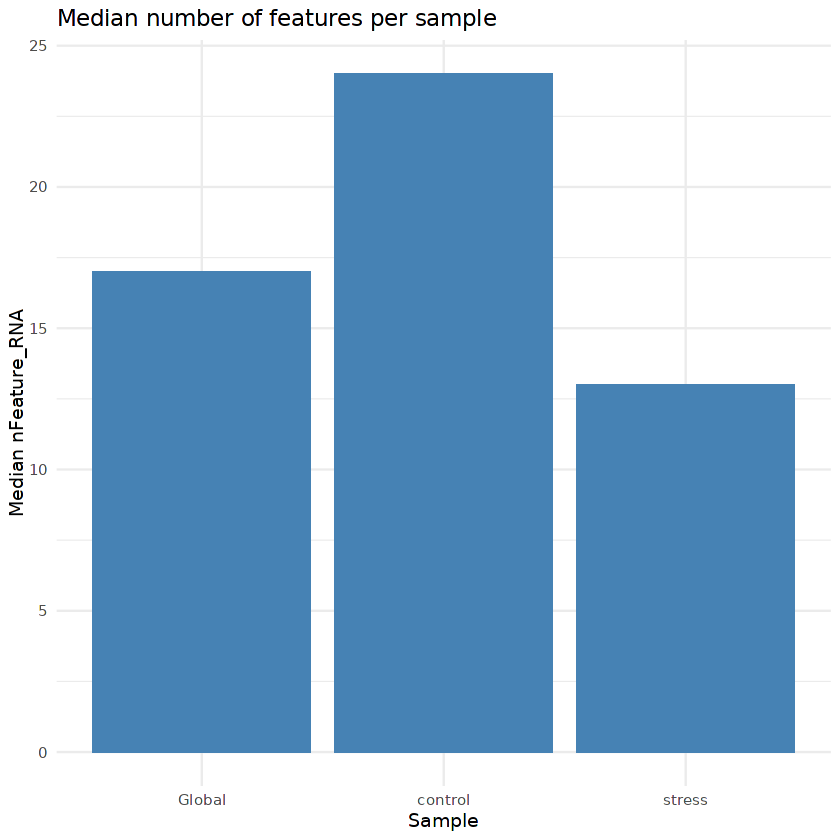

In [121]:
library(ggplot2)

summary_grouped <- summarize_seurat(seurat_obj,
                 #export = "csv", 
                 group_by ="Condition",
                 auto_filename = TRUE)

ggplot(summary_grouped, aes(x = Sample_ID, y = median_nFeature_RNA)) +
  geom_col(fill = "steelblue") +
  theme_minimal() +
  labs(title = "Median number of features per sample", x = "Sample", y = "Median nFeature_RNA")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Warning message:
"Removed 11600 rows containing non-finite outside the scale range
(`stat_ydensity()`)."
Warning message:
"Removed 11600 rows containing non-finite outside the scale range
(`stat_ydensity()`)."


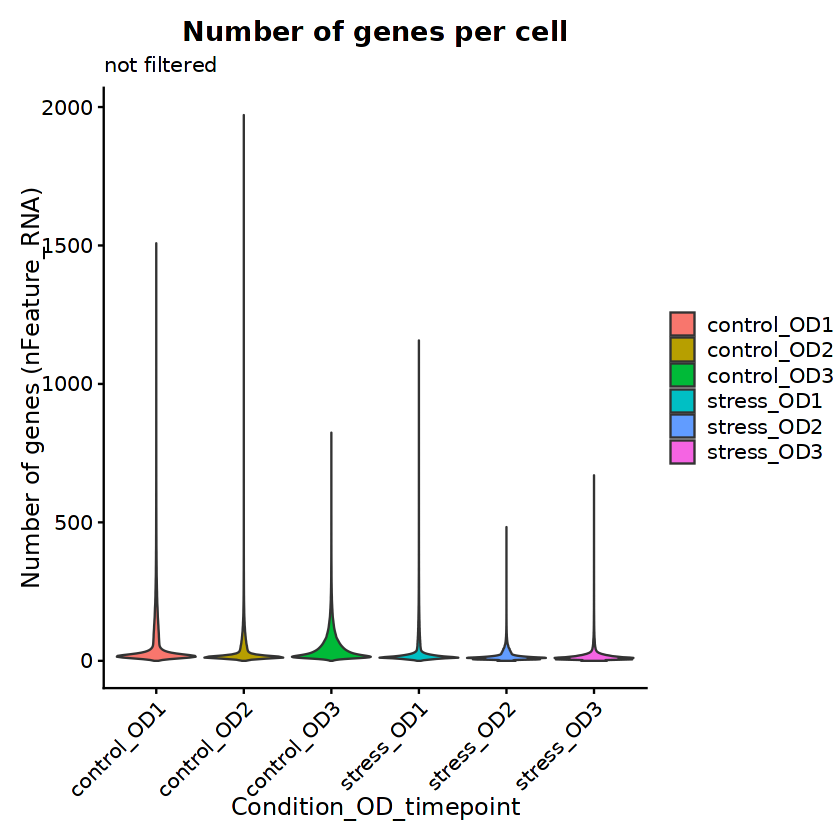

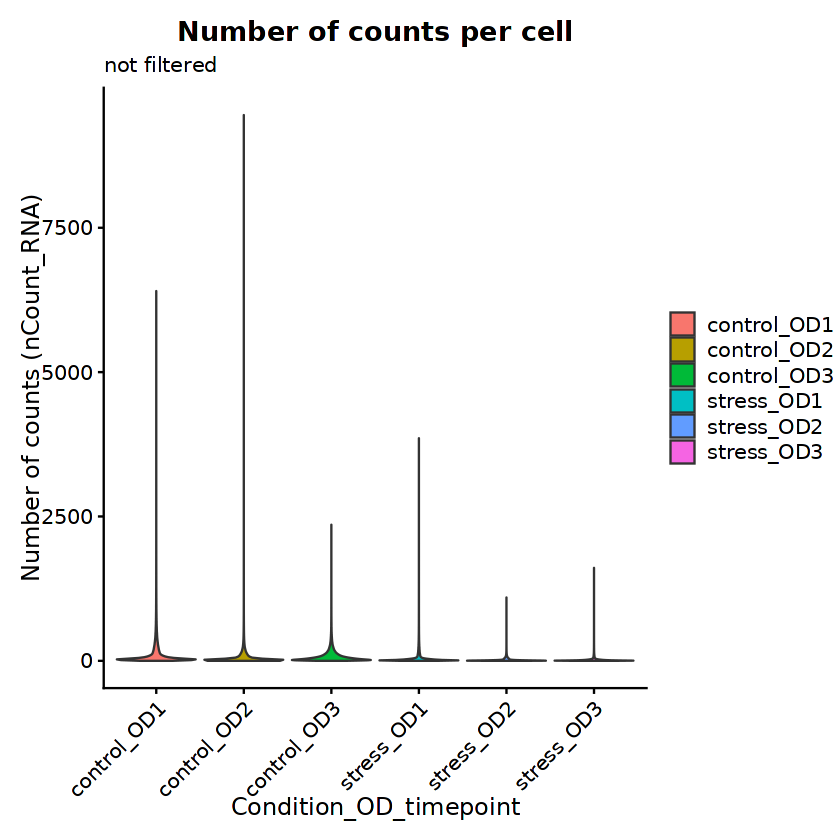

Picking joint bandwidth of 0.0463



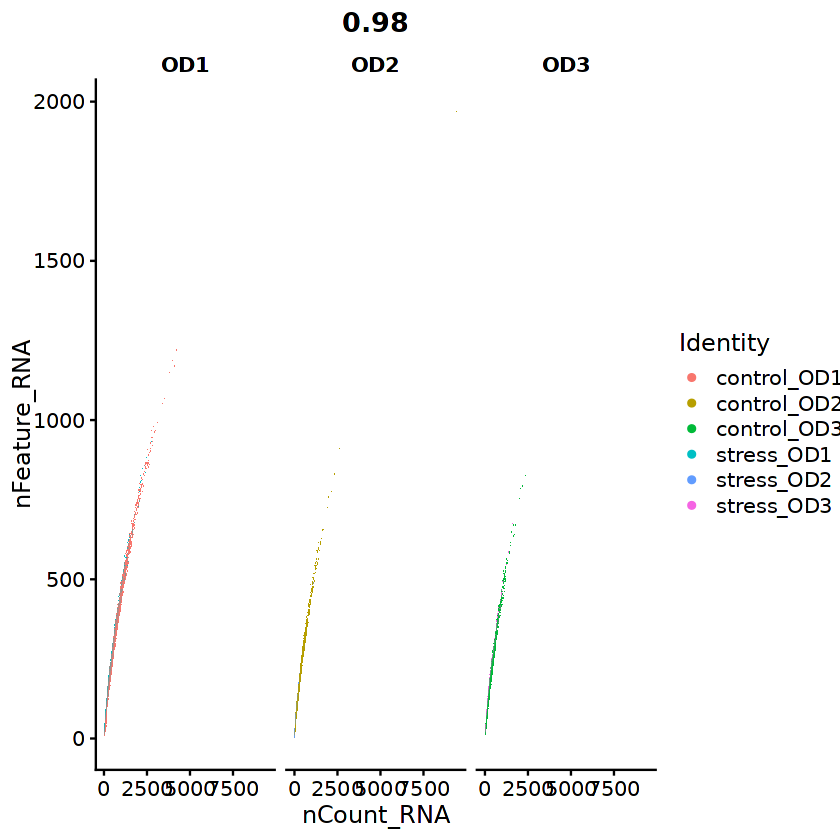

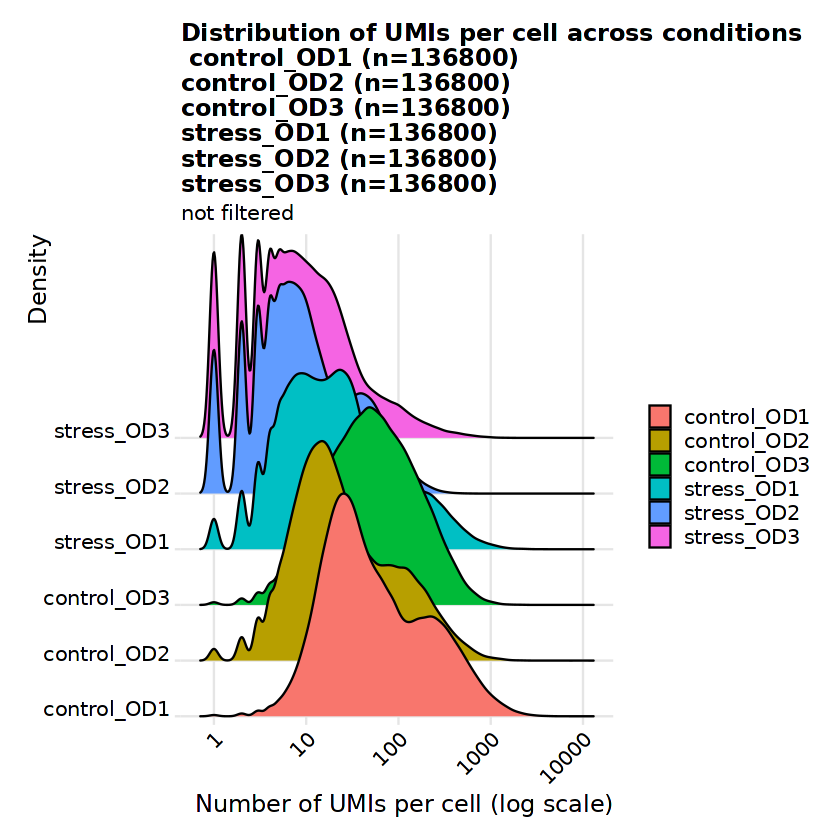

In [16]:
plots_without_point <- generate_qc_plots(
    seurat_obj = seurat_obj,
    subtitle = "not filtered",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = FALSE
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Warning message:
"Removed 11600 rows containing non-finite outside the scale range
(`stat_ydensity()`)."
Warning message:
"Removed 11600 rows containing missing values or values outside the scale range
(`geom_point()`)."
Warning message:
"Removed 11600 rows containing non-finite outside the scale range
(`stat_ydensity()`)."
Warning message:
"Removed 11600 rows containing missing values or values outside the scale range
(`geom_point()`)."


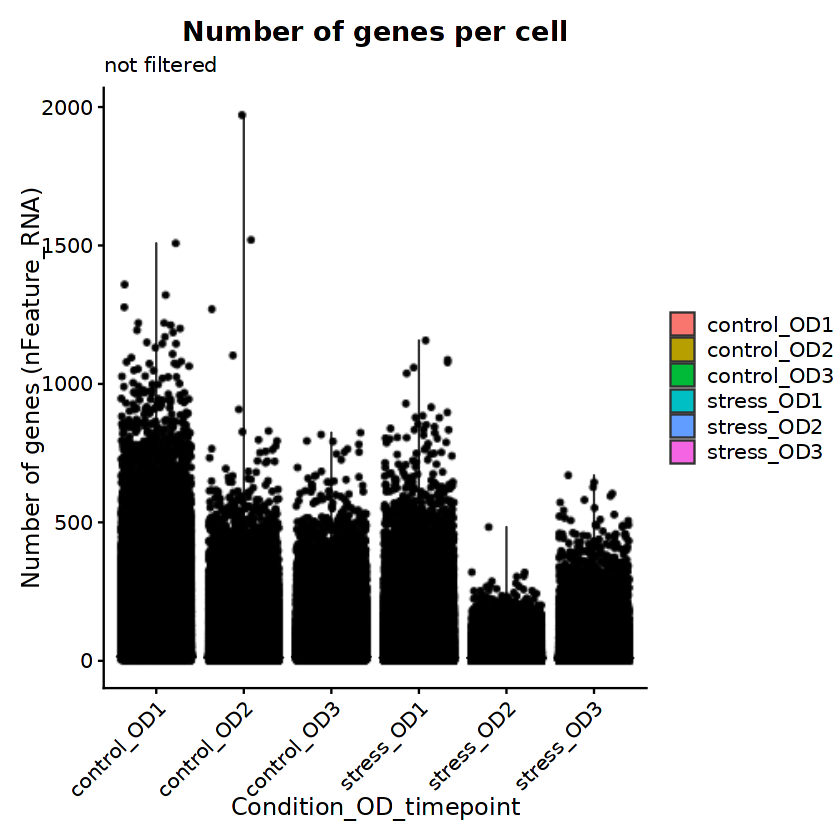

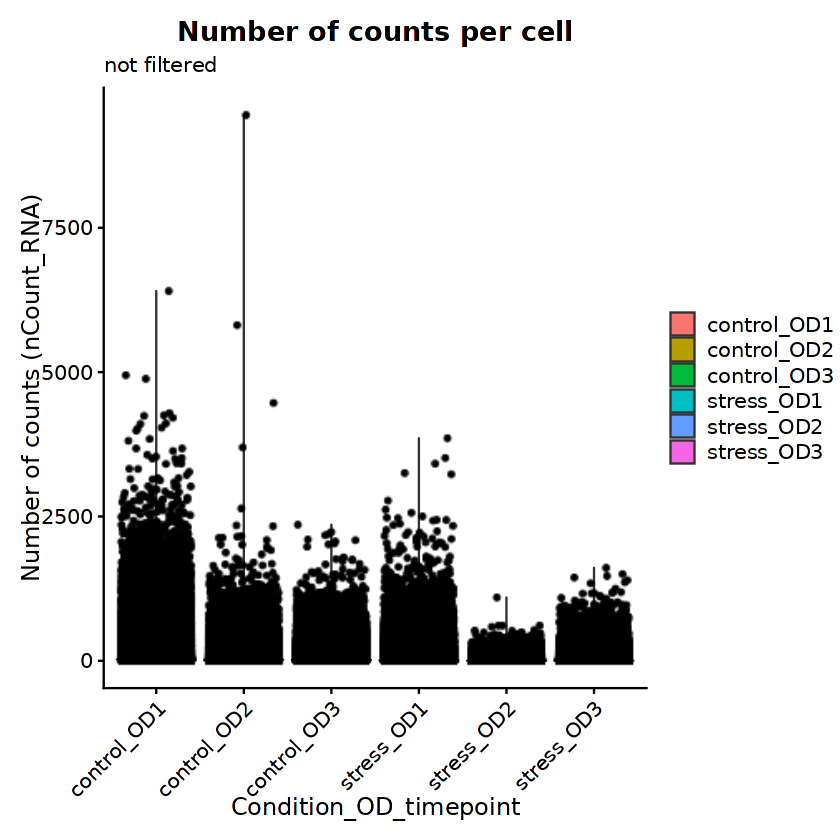

Picking joint bandwidth of 0.0463



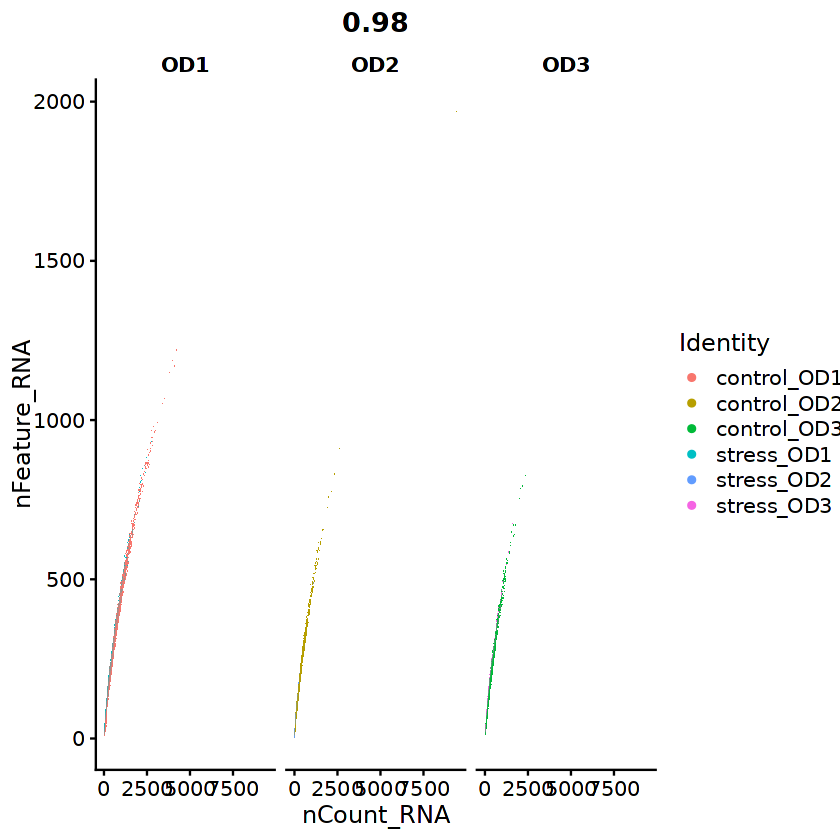

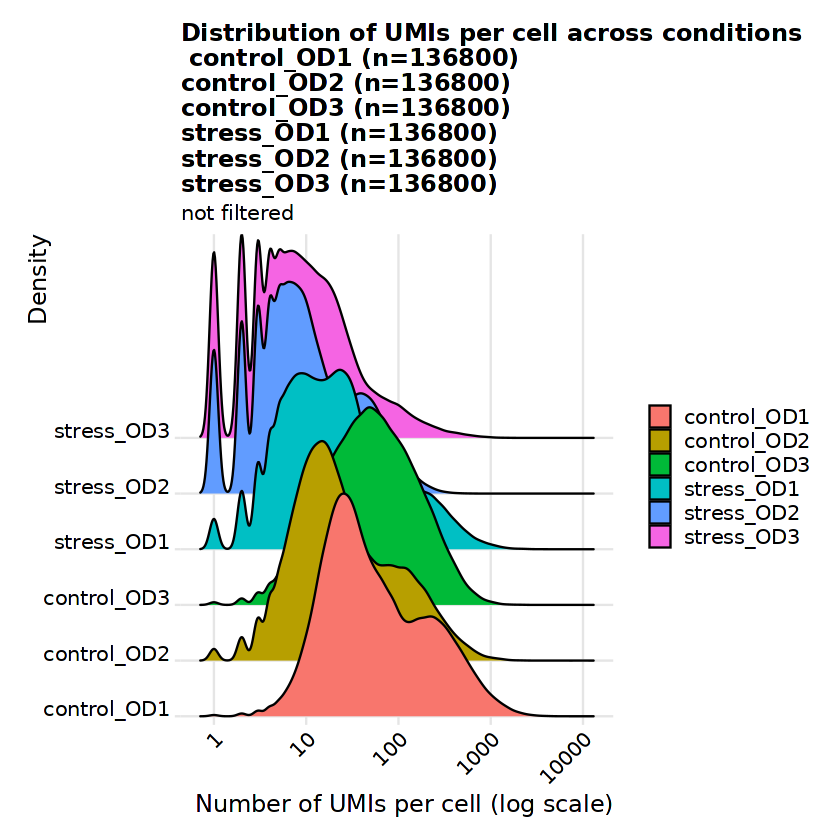

In [ ]:
plots_with_point <- generate_qc_plots(
    seurat_obj = seurat_obj,
    subtitle = "not filtered",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = TRUE
)

# Afficher les plots
plots_with_point$p1
plots_with_point$p2
plots_with_point$scatter_p3
plots_with_point$ridge_p4

# Do the filtering 

## filter gene with a threshold 

In [73]:
# test 


# library(dplyr)
# library(tibble)

# # Extraire les cellules au-dessus du 25e percentile par Condition
# selected_cells <- seurat_obj@meta.data %>%
#   rownames_to_column("cell_barcode") %>%
#   group_by(Condition) %>%
#   filter(nFeature_RNA >= quantile(nFeature_RNA, 0.25)) %>%
#   pull(cell_barcode)

# # Sous-échantillonnage de l'objet Seurat
# seurat_obj_filtered <- subset(seurat_obj, cells = selected_cells)

### Filter the cells to keep only 10% of cells (82.080 cells of 820.800) , we conserve the with highest number of genes expressed in each Sample_ID

In [74]:
cat (" number of cells in the original Seurat object:", ncol(seurat_obj), "\n")

 number of cells in the original Seurat object: 820800 


In [75]:
res1 <- select_cells_by_group(
  seurat_obj = seurat_obj,
  target_total_cells = 82080,
  group_by = "Sample_ID",
  sort_by = "nFeature_RNA",
  descending = TRUE,
)

Target total cells: 82080 
Group column: Sample_ID - 90 groups
Sort by: nFeature_RNA  | Descending: TRUE 
Cells per group: 912 


In [76]:
cat("Number and caracteristics of cells in the first filtered Seurat object:", ncol(res1$seurat), "\n")
filtrer <- res1$seurat
summary_stats_sample <- filtrer@meta.data %>%
    summarise(
        n_cells = n(),
        min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE))

head(summary_stats_sample, 90)
# Save the summary statistics to a CSV file
# write.csv(summary_stats_sample, file = "summary_stats.csv", row.names = FALSE)

Number and caracteristics of cells in the first filtered Seurat object: 82080 


,n_cells,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
1,82080,7,94,184,377,9452.001,309.7901,16,70,157.4525,119,212,1971,124.911


In [77]:
cat("Number and caracteristics of cells in the first filtered Seurat object:", ncol(res1$seurat), "\n")
filtrer <- res1$seurat

summarize_seurat(filtrer,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)

summarize_seurat(filtrer,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 output = "grouped",
                 auto_filename = TRUE)

summarize_seurat(filtrer,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)

Number and caracteristics of cells in the first filtered Seurat object: 82080 


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,82080,6084,1,23448261,12923704,7,94,184,377,9452.001,309.79,16,70,157.453,119,212,1971,124.911


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
M9F_A_1_OD1,912,5787,0.951,781972,358696,486,620.00,742.5,972.25,3567.000,345.376,278,310.75,393.307,359.0,443.00,1095,111.823
M9F_A_1_OD2,912,5111,0.840,187798,118125,111,150.00,179.0,226.00,828.000,88.686,90,102.00,129.523,116.0,143.00,420,42.863
M9F_A_1_OD3,912,5272,0.867,252918,146152,157,211.00,244.5,303.00,1474.000,113.402,116,129.00,160.254,144.0,174.00,577,50.067
M9F_A_2_OD1,912,5468,0.899,336824,186400,200,273.00,327.0,420.25,1413.000,149.717,142,162.00,204.386,186.0,229.25,596,62.172
M9F_A_2_OD2,912,5649,0.929,521558,263995,284,385.00,481.0,644.25,2149.000,282.068,187,216.00,289.468,258.0,323.00,794,102.928
M9F_A_2_OD3,912,4487,0.738,100623,67800,58,86.00,99.0,122.25,441.000,38.829,55,60.00,74.342,68.0,81.00,217,20.411
M9F_A_3_OD1,912,5523,0.908,384548,206810,220,296.75,357.0,482.00,1710.000,195.513,149,173.00,226.765,202.0,255.00,673,78.266
M9F_A_3_OD2,912,4666,0.767,116583,80168,55,84.00,106.0,139.00,801.000,73.399,55,63.00,87.904,75.0,96.00,424,38.596
M9F_A_3_OD3,912,5700,0.937,617397,299557,388,498.00,587.5,767.75,2230.000,261.430,233,260.00,328.462,299.0,368.25,794,93.774


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,82080,6084,1.000,23448261,12923704,7,94.00,184.0,377.00,9452.001,309.790,16,70.00,157.453,119.0,212.00,1971,124.911
M9F_A_1_OD1,912,5787,0.951,781972,358696,486,620.00,742.5,972.25,3567.000,345.376,278,310.75,393.307,359.0,443.00,1095,111.823
M9F_A_1_OD2,912,5111,0.840,187798,118125,111,150.00,179.0,226.00,828.000,88.686,90,102.00,129.523,116.0,143.00,420,42.863
M9F_A_1_OD3,912,5272,0.867,252918,146152,157,211.00,244.5,303.00,1474.000,113.402,116,129.00,160.254,144.0,174.00,577,50.067
M9F_A_2_OD1,912,5468,0.899,336824,186400,200,273.00,327.0,420.25,1413.000,149.717,142,162.00,204.386,186.0,229.25,596,62.172
M9F_A_2_OD2,912,5649,0.929,521558,263995,284,385.00,481.0,644.25,2149.000,282.068,187,216.00,289.468,258.0,323.00,794,102.928
M9F_A_2_OD3,912,4487,0.738,100623,67800,58,86.00,99.0,122.25,441.000,38.829,55,60.00,74.342,68.0,81.00,217,20.411
M9F_A_3_OD1,912,5523,0.908,384548,206810,220,296.75,357.0,482.00,1710.000,195.513,149,173.00,226.765,202.0,255.00,673,78.266
M9F_A_3_OD2,912,4666,0.767,116583,80168,55,84.00,106.0,139.00,801.000,73.399,55,63.00,87.904,75.0,96.00,424,38.596


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


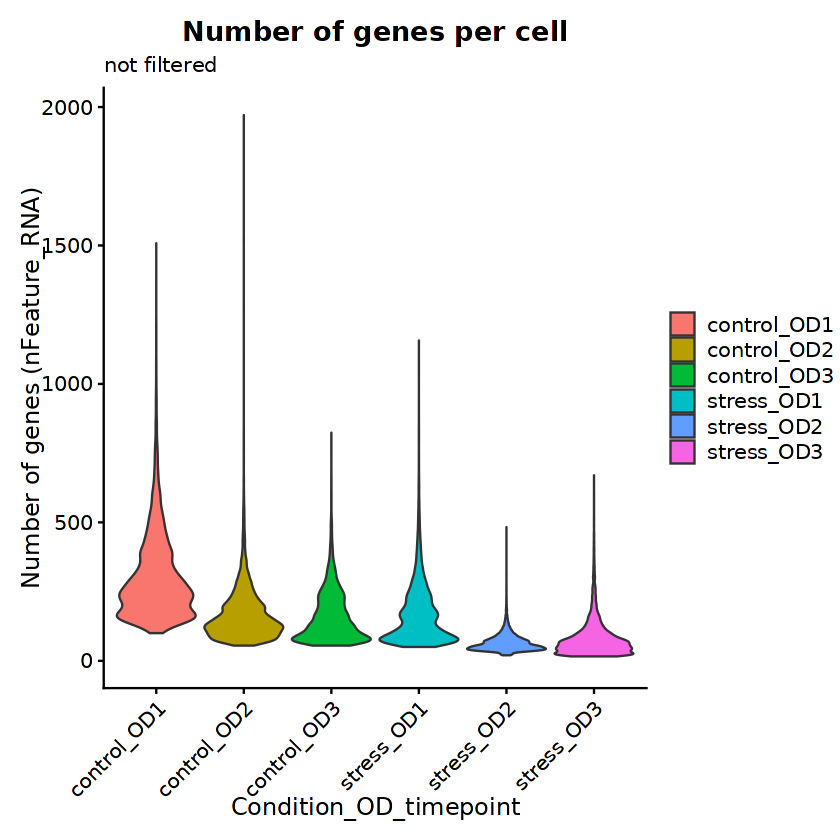

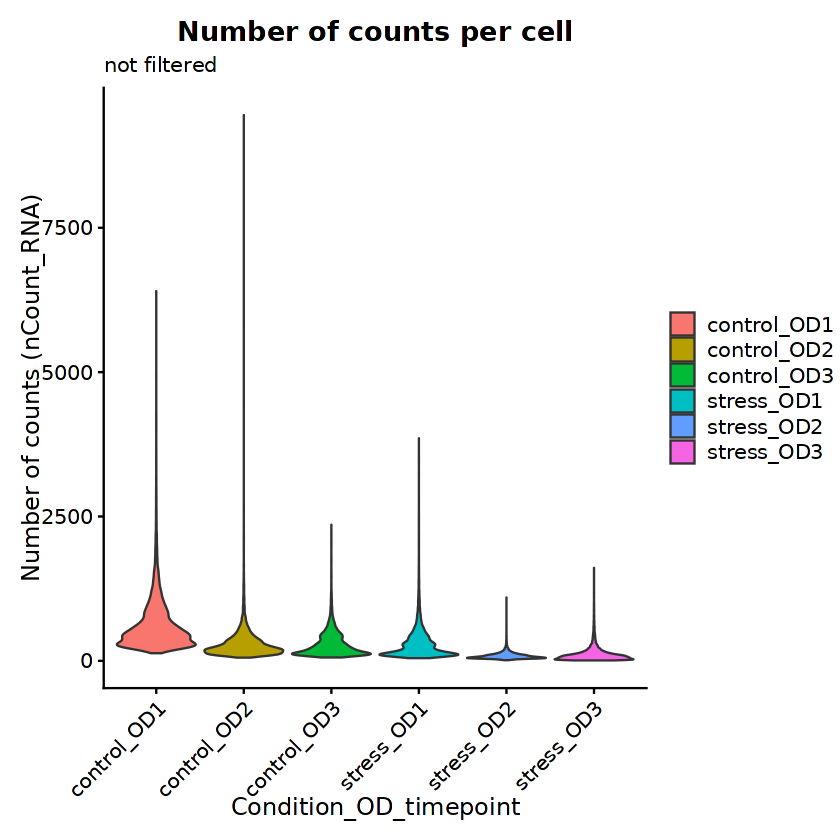

Picking joint bandwidth of 0.0391



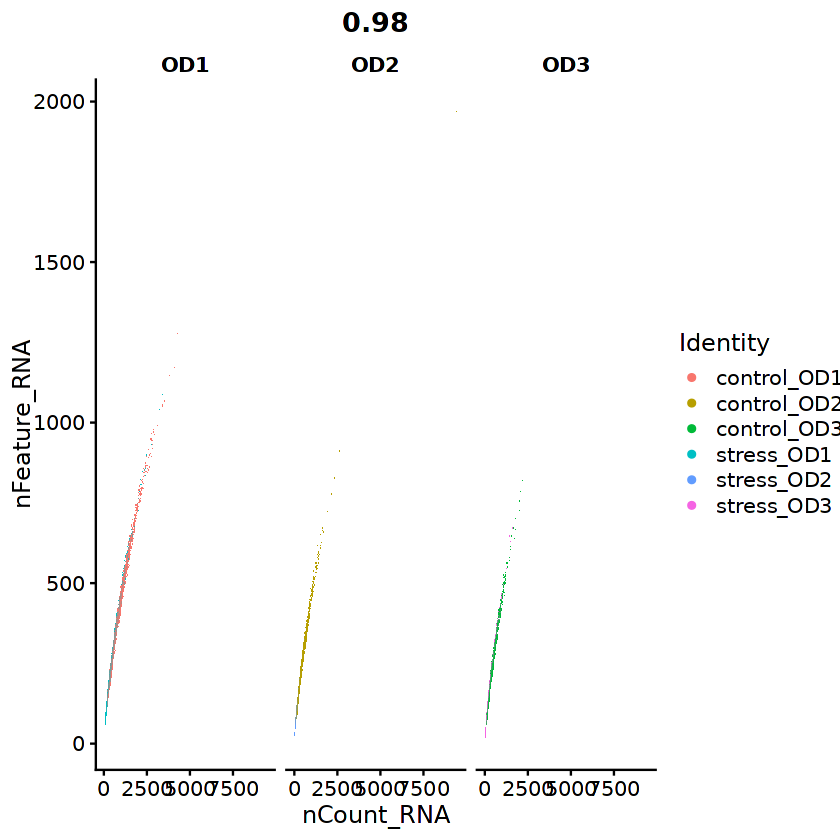

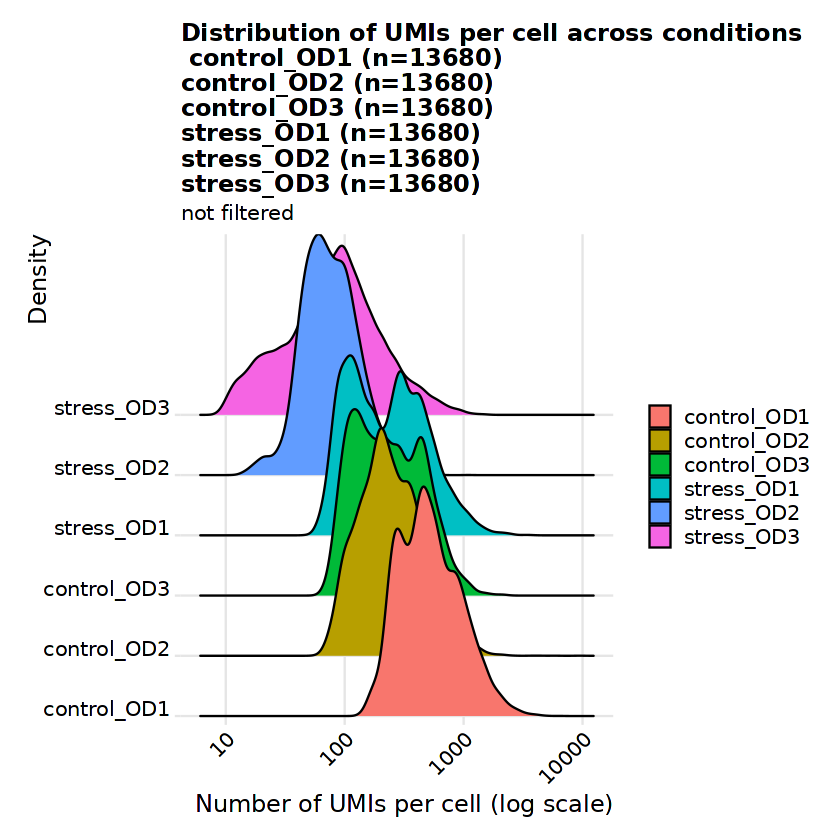

In [78]:
plots_without_point <- generate_qc_plots(
    seurat_obj = filtrer,
    subtitle = "not filtered",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = FALSE
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4

### Filter on the number of UMI per cell (nCounts), we conserve only best cells in each Sample_ID to go to 3000 cells in total

In [79]:
res2 <- select_cells_by_group(
  seurat_obj = res1$seurat,
  target_total_cells = 3000,
  group_by = "Sample_ID",
  sort_by = "nCount_RNA",
  descending = TRUE,
)

Target total cells: 3000 
Group column: Sample_ID - 90 groups
Sort by: nCount_RNA  | Descending: TRUE 
Cells per group: 33 


In [80]:
cat("Number and caracteristics of cells in the second filtered Seurat object:", ncol(res2$seurat), "\n")
filtrer2 <- res2$seurat
summary_stats_sample <- filtrer2@meta.data %>%
    summarise(
        n_cells = n(),
        min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE))

View(summary_stats_sample)
# Save the summary statistics to a CSV file
# write.csv(summary_stats_sample, file = "summary_stats_by_Sample_ID.csv", row.names = FALSE)

Number and caracteristics of cells in the second filtered Seurat object: 2970 


n_cells,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
2970,24,315,532,1034,9452.001,701.7356,23,185,346.2552,280,464,1971,221.302


In [81]:
# same by Sample 
cat("Number and caracteristics of cells in the first filtered Seurat object:", ncol(res2$seurat), "\n")
filtrer2 <- res2$seurat

summarize_seurat(filtrer2,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)

summarize_seurat(filtrer2,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 output = "grouped",
                 auto_filename = TRUE)

summarize_seurat(filtrer2,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)

Number and caracteristics of cells in the first filtered Seurat object: 2970 


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2970,5975,1,2300110,1028378,24,315,532,1034,9452.001,701.736,23,185,346.255,280,464,1971,221.302


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
M9F_A_1_OD1,33,4168,0.698,67632,24725,1649,1796,1929,2164,3567.000,391.893,642,673,749.242,732,769,1095,94.156
M9F_A_1_OD2,33,2570,0.430,17426,9234,435,457,479,554,828.000,108.448,230,253,279.818,260,300,420,47.586
M9F_A_1_OD3,33,2893,0.484,23282,11320,539,577,634,771,1474.000,189.220,266,293,343.030,326,375,577,67.219
M9F_A_2_OD1,33,3235,0.541,29970,13772,701,740,817,1001,1413.000,215.936,322,360,417.333,391,446,596,76.815
M9F_A_2_OD2,33,3885,0.650,52028,20735,1245,1346,1524,1702,2149.000,277.290,521,557,628.333,614,684,794,81.132
M9F_A_2_OD3,33,1664,0.278,8110,4760,203,215,225,258,441.000,49.440,116,131,144.242,136,154,217,23.049
M9F_A_3_OD1,33,3462,0.579,36867,16180,859,947,1039,1248,1710.000,237.819,408,440,490.303,463,523,673,75.073
M9F_A_3_OD2,33,2270,0.380,13160,7466,308,336,371,434,801.000,107.860,174,199,226.242,217,239,424,50.695
M9F_A_3_OD3,33,3863,0.647,52088,20844,1233,1395,1490,1741,2230.000,278.375,506,577,631.636,611,669,794,76.594


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2970,5975,1.000,2300110,1028378,24,315,532,1034,9452.001,701.736,23,185,346.255,280,464,1971,221.302
M9F_A_1_OD1,33,4168,0.698,67632,24725,1649,1796,1929,2164,3567.000,391.893,642,673,749.242,732,769,1095,94.156
M9F_A_1_OD2,33,2570,0.430,17426,9234,435,457,479,554,828.000,108.448,230,253,279.818,260,300,420,47.586
M9F_A_1_OD3,33,2893,0.484,23282,11320,539,577,634,771,1474.000,189.220,266,293,343.030,326,375,577,67.219
M9F_A_2_OD1,33,3235,0.541,29970,13772,701,740,817,1001,1413.000,215.936,322,360,417.333,391,446,596,76.815
M9F_A_2_OD2,33,3885,0.650,52028,20735,1245,1346,1524,1702,2149.000,277.290,521,557,628.333,614,684,794,81.132
M9F_A_2_OD3,33,1664,0.278,8110,4760,203,215,225,258,441.000,49.440,116,131,144.242,136,154,217,23.049
M9F_A_3_OD1,33,3462,0.579,36867,16180,859,947,1039,1248,1710.000,237.819,408,440,490.303,463,523,673,75.073
M9F_A_3_OD2,33,2270,0.380,13160,7466,308,336,371,434,801.000,107.860,174,199,226.242,217,239,424,50.695


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


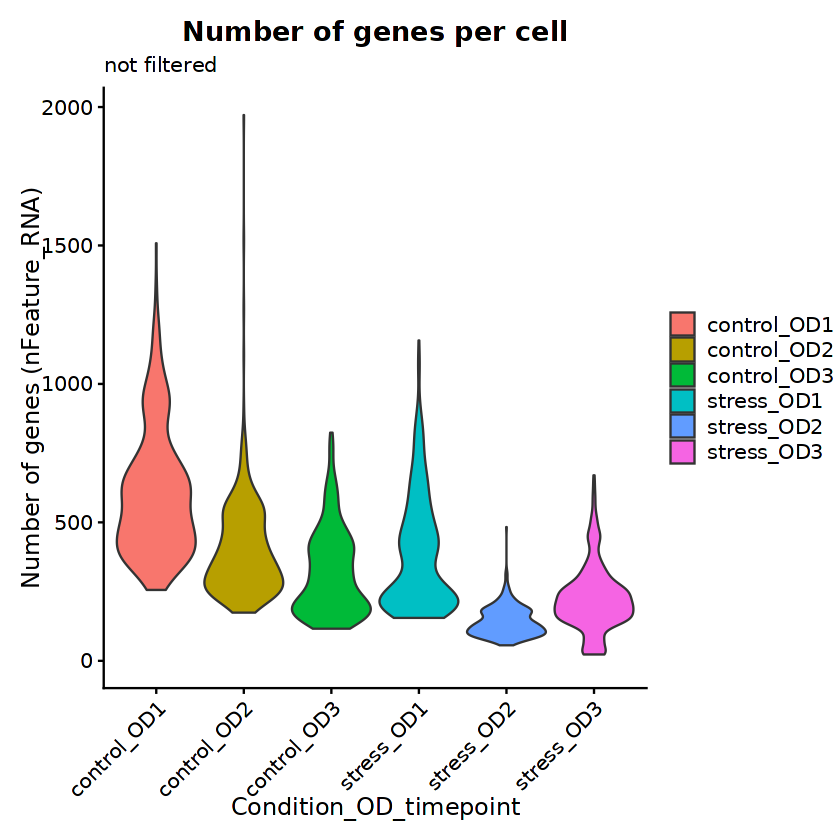

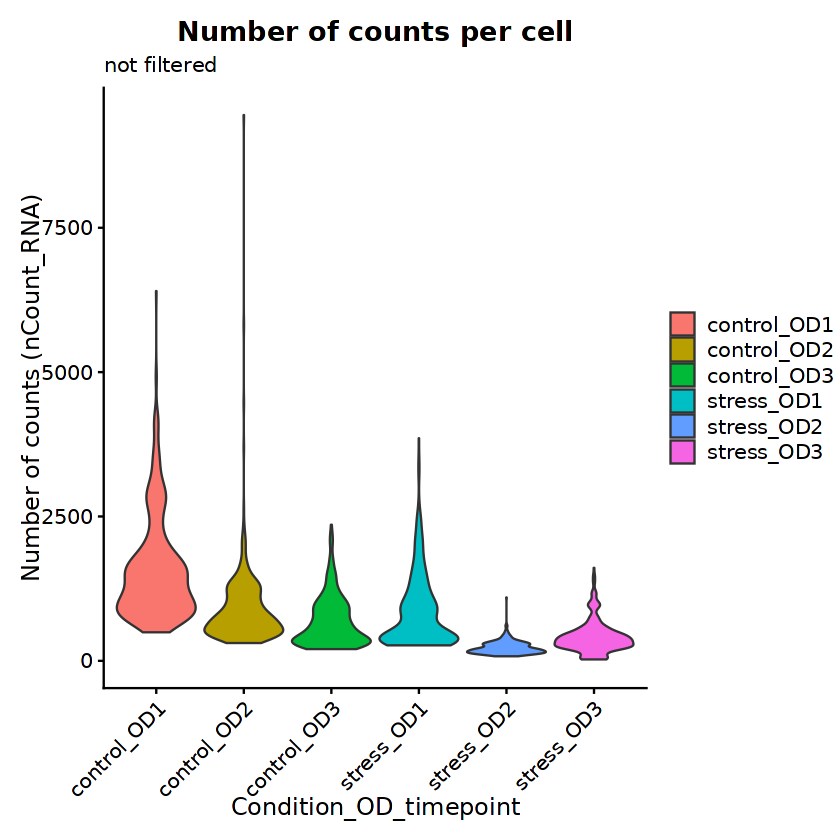

Picking joint bandwidth of 0.0608



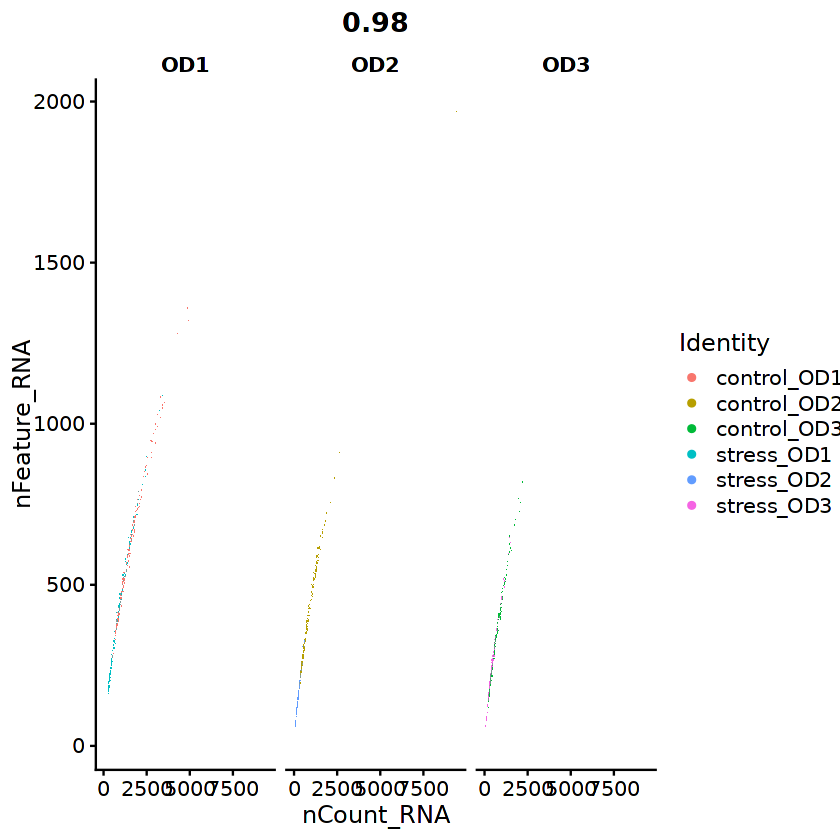

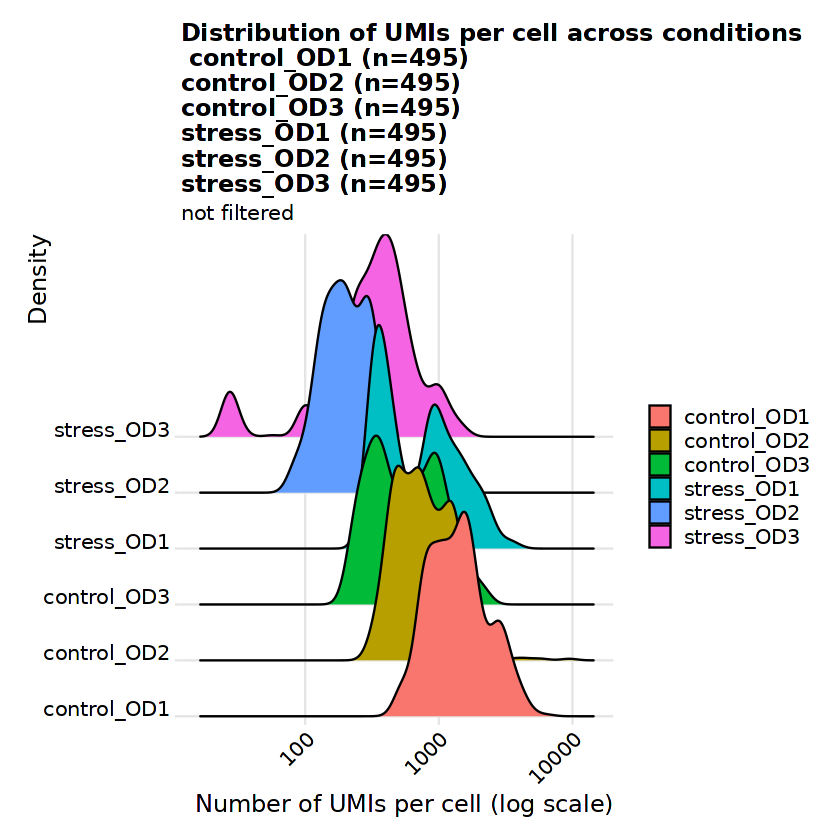

In [82]:
plots_without_point <- generate_qc_plots(
    seurat_obj = filtrer2,
    subtitle = "not filtered",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = FALSE
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4

## Remove potential doublets

0.34 is the doublet rate from Kuchina et al. 2021

0.34*3000/100 = 10.2 doublets potentiels sur 3000 cellules


In [83]:
# Afficher les cellules ayant le plus de nCount_RNA avant le filtrage (dans filtrer2)
cat ("\nTop 20 cells by nCount_RNA:\n")
top_cells_nCount <- filtrer2@meta.data %>%
    arrange(desc(nCount_RNA)) %>%
    head(20)

View(top_cells_nCount)

# Afficher les cellules ayant le plus de nFeature_RNA avant le filtrage (dans filtrer2)
cat ("\nTop 20 cells by nFeature_RNA:\n")
top_cells_nFeature <- filtrer2@meta.data %>%
    arrange(desc(nFeature_RNA)) %>%
    head(20)

View(top_cells_nFeature)


# check if there are common cells in both top cells
common_cells <- intersect(rownames(top_cells_nCount), rownames(top_cells_nFeature))
cat("\nCommon cells in both top nCount and top nFeature:\n")
print(common_cells)


Top 20 cells by nCount_RNA:


,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
GCTAACGA_ATCCTGTA_GCAAATTC,9452.001,1971,GCAAATTC,ATCCTGTA,GCTAACGA,G11,C4,E4,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
CAACCACA_GTCTGTCA_TTCATCGC,6404.000,1508,TTCATCGC,GTCTGTCA,CAACCACA,G2,E10,C6,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B
ATAGCGAC_CCAGTTCA_GCAAATTC,5812.999,1520,GCAAATTC,CCAGTTCA,ATAGCGAC,G11,C12,G8,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
GGTGCGAA_AACGTGAT_TTCATCGC,4945.999,1321,TTCATCGC,AACGTGAT,GGTGCGAA,G2,A1,E7,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B
CACCTTAC_TGAAGAGA_GTGGGTTC,4884.000,1359,GTGGGTTC,TGAAGAGA,CACCTTAC,H2,F4,G12,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
TCCGTCTA_CAGCGTTA_TCTTAATC,4466.000,1270,TCTTAATC,CAGCGTTA,TCCGTCTA,G6,C10,F2,M9F_C_3_OD2,M9F,C,3,OD2,0.5,0.603,control,control_OD2,C_3,control_OD2_C
ACATTGGC_TCTTCACA_GTGGGTTC,4289.000,1277,GTGGGTTC,TCTTCACA,ACATTGGC,H2,F3,A6,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
CACTTCGA_AGTACAAG_GTGGGTTC,4250.000,1212,GTGGGTTC,AGTACAAG,CACTTCGA,H2,A12,C9,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
TTCACGCA_AACCGAGA_TTCATCGC,4242.000,1194,TTCATCGC,AACCGAGA,TTCACGCA,G2,B2,F8,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B



Top 20 cells by nFeature_RNA:


,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
GCTAACGA_ATCCTGTA_GCAAATTC,9452.001,1971,GCAAATTC,ATCCTGTA,GCTAACGA,G11,C4,E4,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
ATAGCGAC_CCAGTTCA_GCAAATTC,5812.999,1520,GCAAATTC,CCAGTTCA,ATAGCGAC,G11,C12,G8,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
CAACCACA_GTCTGTCA_TTCATCGC,6404.000,1508,TTCATCGC,GTCTGTCA,CAACCACA,G2,E10,C6,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B
CACCTTAC_TGAAGAGA_GTGGGTTC,4884.000,1359,GTGGGTTC,TGAAGAGA,CACCTTAC,H2,F4,G12,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
GGTGCGAA_AACGTGAT_TTCATCGC,4945.999,1321,TTCATCGC,AACGTGAT,GGTGCGAA,G2,A1,E7,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B
ACATTGGC_TCTTCACA_GTGGGTTC,4289.000,1277,GTGGGTTC,TCTTCACA,ACATTGGC,H2,F3,A6,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
TCCGTCTA_CAGCGTTA_TCTTAATC,4466.000,1270,TCTTAATC,CAGCGTTA,TCCGTCTA,G6,C10,F2,M9F_C_3_OD2,M9F,C,3,OD2,0.5,0.603,control,control_OD2,C_3,control_OD2_C
GCTAACGA_ACACAGAA_GTGGGTTC,4209.000,1220,GTGGGTTC,ACACAGAA,GCTAACGA,H2,B6,E4,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B
TGAAGAGA_CCTCTATC_GTGGGTTC,4038.000,1220,GTGGGTTC,CCTCTATC,TGAAGAGA,H2,H4,F4,M9F_B_4_OD1,M9F,B,4,OD1,0.1,0.208,control,control_OD1,B_4,control_OD1_B



Common cells in both top nCount and top nFeature:
 [1] "GCTAACGA_ATCCTGTA_GCAAATTC" "CAACCACA_GTCTGTCA_TTCATCGC"
 [3] "ATAGCGAC_CCAGTTCA_GCAAATTC" "GGTGCGAA_AACGTGAT_TTCATCGC"
 [5] "CACCTTAC_TGAAGAGA_GTGGGTTC" "TCCGTCTA_CAGCGTTA_TCTTAATC"
 [7] "ACATTGGC_TCTTCACA_GTGGGTTC" "CACTTCGA_AGTACAAG_GTGGGTTC"
 [9] "TTCACGCA_AACCGAGA_TTCATCGC" "GCTAACGA_ACACAGAA_GTGGGTTC"
[11] "TCCGTCTA_CCTAATCC_GTGGGTTC" "GATGAATC_TGGTGGTA_TTCATCGC"
[13] "TGAAGAGA_CCTCTATC_GTGGGTTC" "GACAGTGC_CCATCCTC_TTCATCGC"
[15] "TATCAGCA_GACTAGTA_GTGGGTTC" "ACCTCCAA_AATCCGTC_CTGTCCCG"
[17] "CGACTGGA_ATTGAGGA_TTCATCGC" "ACGTATCA_GAGCTGAA_GTGGGTTC"
[19] "CCTCCTGA_CCTCTATC_TTCATCGC"


In [84]:
cat ("\nTop 3 cells by nFeature_RNA for each Sample_ID:\n")
top_cells_nFeature <- filtrer2@meta.data %>%
    group_by(Sample_ID) %>%
    arrange(desc(nFeature_RNA)) %>%
    slice_head(n = 3) %>%
    ungroup()

View(top_cells_nFeature)

cat ("\nTop 3 cells by nCount_RNA for each Sample_ID:\n")
top_cells_nCount <- filtrer2@meta.data %>%
    group_by(Sample_ID) %>%
    arrange(desc(nCount_RNA)) %>%
    slice_head(n = 3) %>%
    ungroup()

View(top_cells_nCount)


Top 3 cells by nFeature_RNA for each Sample_ID:


nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
3567.0000,1095,CTGCTTTG,AACTCACC,GAGCTGAA,E1,F9,D12,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
2785.9999,894,CTGCTTTG,AATGTTGC,GATGAATC,E1,G1,H11,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
2545.9999,891,CTGCTTTG,GAGCTGAA,ACTATGCA,E1,D12,B11,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
828.0000,420,CCGAGAAA,CCAGTTCA,CCTAATCC,E4,C12,H3,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
789.0001,402,CCGAGAAA,CCATCCTC,ACCTCCAA,E4,H1,B8,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
812.9999,394,CCGAGAAA,CCATCCTC,CGCATACA,E4,H1,D6,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
1473.9999,577,TATTTAAG,CTAAGGTC,CAACCACA,E7,H7,C6,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
1087.0000,497,TATTTAAG,TCCGTCTA,TCCGTCTA,E7,F2,F2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
942.9999,423,TATTTAAG,CCTAATCC,GCCACATA,E7,H3,E2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A



Top 3 cells by nCount_RNA for each Sample_ID:


nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
3567.0000,1095,CTGCTTTG,AACTCACC,GAGCTGAA,E1,F9,D12,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
2785.9999,894,CTGCTTTG,AATGTTGC,GATGAATC,E1,G1,H11,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
2545.9999,891,CTGCTTTG,GAGCTGAA,ACTATGCA,E1,D12,B11,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
828.0000,420,CCGAGAAA,CCAGTTCA,CCTAATCC,E4,C12,H3,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
812.9999,394,CCGAGAAA,CCATCCTC,CGCATACA,E4,H1,D6,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
789.0001,402,CCGAGAAA,CCATCCTC,ACCTCCAA,E4,H1,B8,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
1473.9999,577,TATTTAAG,CTAAGGTC,CAACCACA,E7,H7,C6,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
1087.0000,497,TATTTAAG,TCCGTCTA,TCCGTCTA,E7,F2,F2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
942.9999,423,TATTTAAG,CCTAATCC,GCCACATA,E7,H3,E2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A


In [85]:
# remove potential doublets
seurat_obj_Rm_doublets <- subset(filtrer2, subset = nCount_RNA < 5000 & nFeature_RNA < 1500)

In [86]:
#number of cells before and after doublet removal
cat("\nNumber of cells before doublet removal:", ncol(filtrer2), "\n")
cat("Number of cells after doublet removal:", ncol(seurat_obj_Rm_doublets), "\n")  

# see the cells which are removed
removed_cells <- setdiff(colnames(filtrer2), colnames(seurat_obj_Rm_doublets))
cat("\nCells removed during doublet removal:\n")
print(removed_cells)

# ncount and nfeature of these cells avec dplyr
removed_cells_data <- filtrer2@meta.data %>%
    filter(rownames(filtrer2@meta.data) %in% removed_cells) %>%
    select(nCount_RNA, nFeature_RNA, everything())

View(removed_cells_data) 


Number of cells before doublet removal: 2970 
Number of cells after doublet removal: 2967 



Cells removed during doublet removal:
[1] "GCTAACGA_ATCCTGTA_GCAAATTC" "ATAGCGAC_CCAGTTCA_GCAAATTC"
[3] "CAACCACA_GTCTGTCA_TTCATCGC"


,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
GCTAACGA_ATCCTGTA_GCAAATTC,9452.001,1971,GCAAATTC,ATCCTGTA,GCTAACGA,G11,C4,E4,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
ATAGCGAC_CCAGTTCA_GCAAATTC,5812.999,1520,GCAAATTC,CCAGTTCA,ATAGCGAC,G11,C12,G8,M9F_C_5_OD2,M9F,C,5,OD2,0.5,0.603,control,control_OD2,C_5,control_OD2_C
CAACCACA_GTCTGTCA_TTCATCGC,6404.000,1508,TTCATCGC,GTCTGTCA,CAACCACA,G2,E10,C6,M9F_B_3_OD1,M9F,B,3,OD1,0.1,0.208,control,control_OD1,B_3,control_OD1_B


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


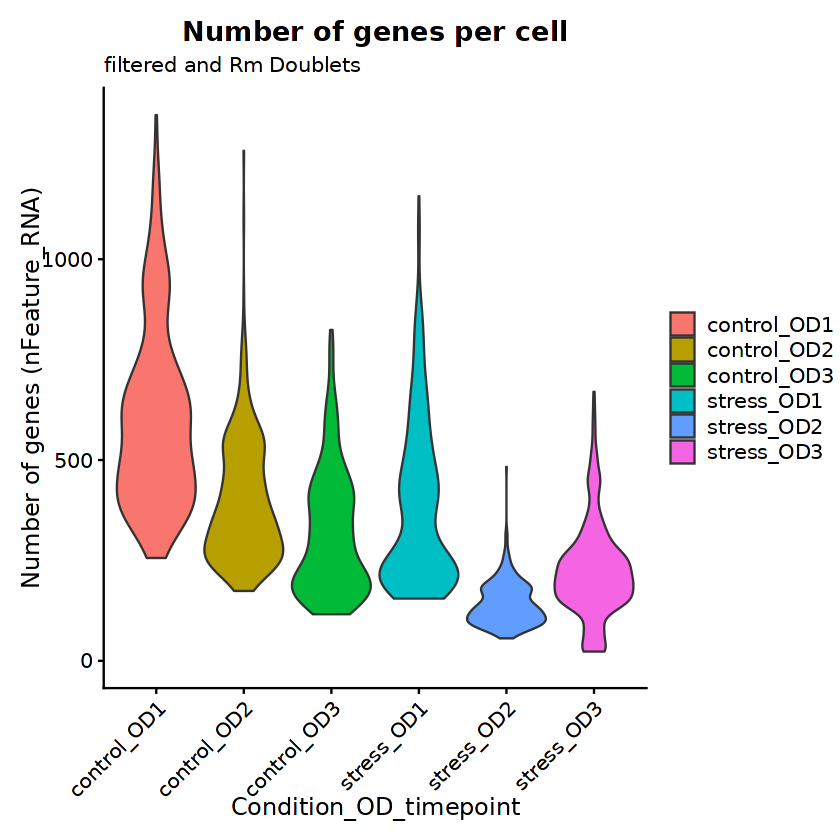

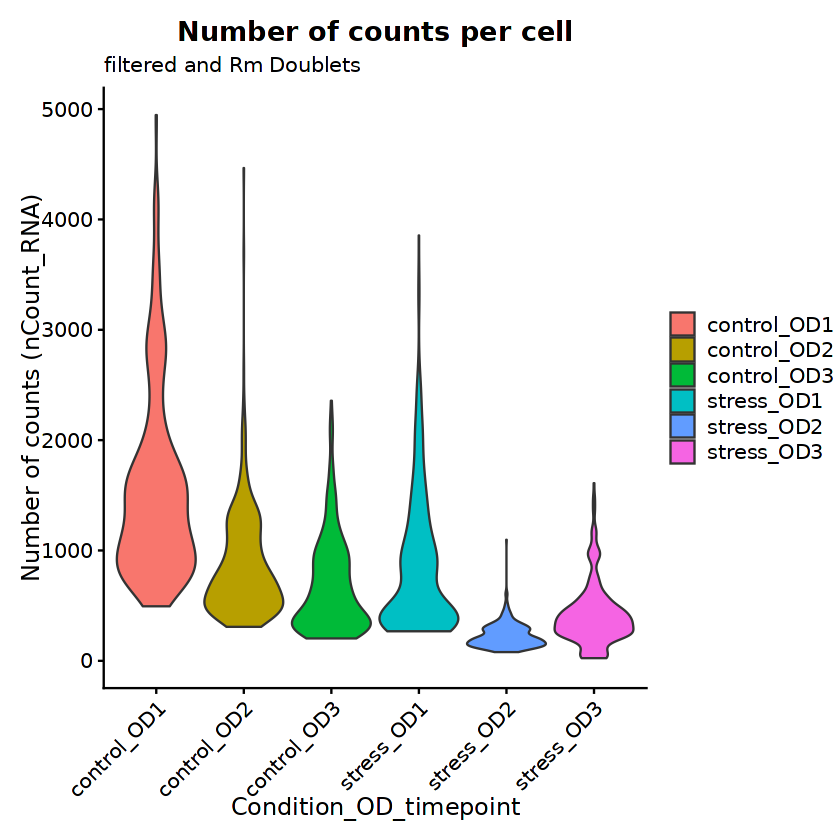

Picking joint bandwidth of 0.0603



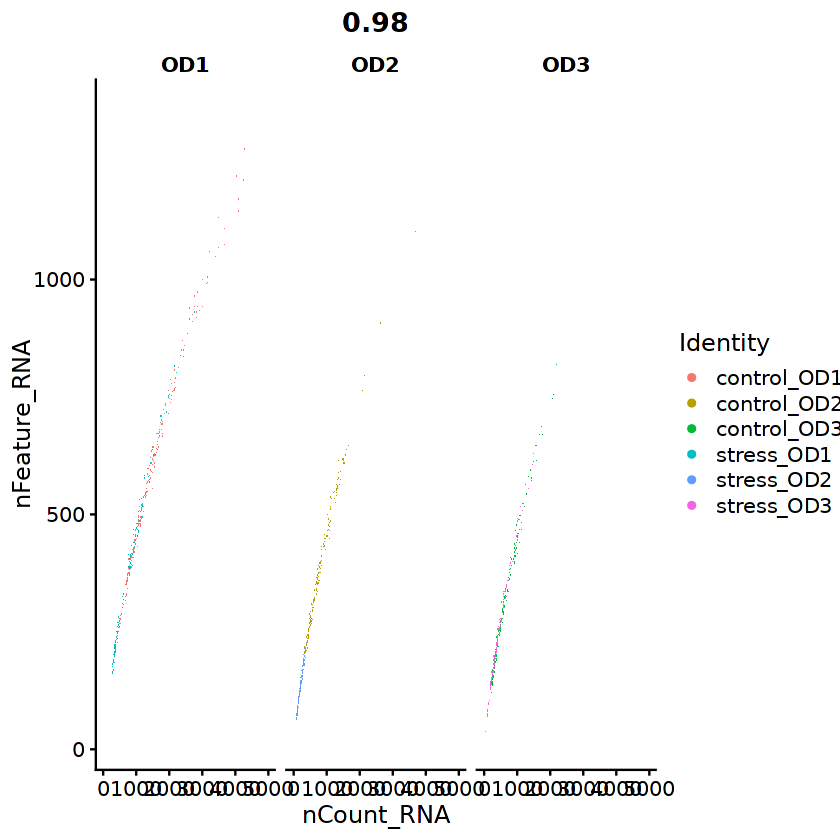

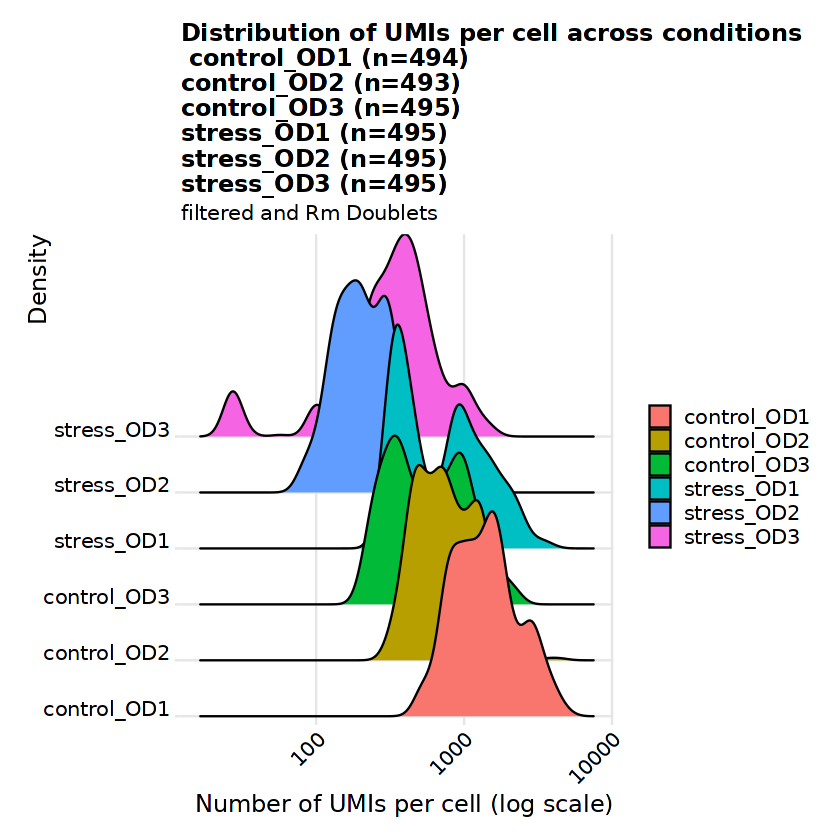

In [87]:
plots_without_point <- generate_qc_plots(
    seurat_obj = seurat_obj_Rm_doublets,
    subtitle = "filtered and Rm Doublets",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = FALSE
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4

Data Quality Check
After filtering, we observe a peak in the stress condition with cells showing low expression levels. This could indicate a technical replicate that didn't work properly and should be investigated further.

In [88]:
#regrouped by Sample_ID

cat("Number and caracteristics of cells after removed potential doublets :", ncol(seurat_obj_Rm_doublets), "\n")


summarize_seurat(seurat_obj_Rm_doublets,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)

summarize_seurat(seurat_obj_Rm_doublets,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 output = "grouped",
                 auto_filename = TRUE)

summarize_seurat(seurat_obj_Rm_doublets,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)

Number and caracteristics of cells after removed potential doublets : 2967 


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2967,5975,1,2278441,1023379,24,314,532,1031.5,4945.999,669.519,23,185,344.92,280,464,1359,217.285


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
M9F_A_1_OD1,33,4168,0.698,67632,24725,1649,1796.0,1929.0,2164.00,3567.000,391.893,642,673.0,749.242,732,769.00,1095,94.156
M9F_A_1_OD2,33,2570,0.430,17426,9234,435,457.0,479.0,554.00,828.000,108.448,230,253.0,279.818,260,300.00,420,47.586
M9F_A_1_OD3,33,2893,0.484,23282,11320,539,577.0,634.0,771.00,1474.000,189.220,266,293.0,343.030,326,375.00,577,67.219
M9F_A_2_OD1,33,3235,0.541,29970,13772,701,740.0,817.0,1001.00,1413.000,215.936,322,360.0,417.333,391,446.00,596,76.815
M9F_A_2_OD2,33,3885,0.650,52028,20735,1245,1346.0,1524.0,1702.00,2149.000,277.290,521,557.0,628.333,614,684.00,794,81.132
M9F_A_2_OD3,33,1664,0.278,8110,4760,203,215.0,225.0,258.00,441.000,49.440,116,131.0,144.242,136,154.00,217,23.049
M9F_A_3_OD1,33,3462,0.579,36867,16180,859,947.0,1039.0,1248.00,1710.000,237.819,408,440.0,490.303,463,523.00,673,75.073
M9F_A_3_OD2,33,2270,0.380,13160,7466,308,336.0,371.0,434.00,801.000,107.860,174,199.0,226.242,217,239.00,424,50.695
M9F_A_3_OD3,33,3863,0.647,52088,20844,1233,1395.0,1490.0,1741.00,2230.000,278.375,506,577.0,631.636,611,669.00,794,76.594


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2967,5975,1.000,2278441,1023379,24,314.0,532.0,1031.50,4945.999,669.519,23,185.0,344.920,280,464.00,1359,217.285
M9F_A_1_OD1,33,4168,0.698,67632,24725,1649,1796.0,1929.0,2164.00,3567.000,391.893,642,673.0,749.242,732,769.00,1095,94.156
M9F_A_1_OD2,33,2570,0.430,17426,9234,435,457.0,479.0,554.00,828.000,108.448,230,253.0,279.818,260,300.00,420,47.586
M9F_A_1_OD3,33,2893,0.484,23282,11320,539,577.0,634.0,771.00,1474.000,189.220,266,293.0,343.030,326,375.00,577,67.219
M9F_A_2_OD1,33,3235,0.541,29970,13772,701,740.0,817.0,1001.00,1413.000,215.936,322,360.0,417.333,391,446.00,596,76.815
M9F_A_2_OD2,33,3885,0.650,52028,20735,1245,1346.0,1524.0,1702.00,2149.000,277.290,521,557.0,628.333,614,684.00,794,81.132
M9F_A_2_OD3,33,1664,0.278,8110,4760,203,215.0,225.0,258.00,441.000,49.440,116,131.0,144.242,136,154.00,217,23.049
M9F_A_3_OD1,33,3462,0.579,36867,16180,859,947.0,1039.0,1248.00,1710.000,237.819,408,440.0,490.303,463,523.00,673,75.073
M9F_A_3_OD2,33,2270,0.380,13160,7466,308,336.0,371.0,434.00,801.000,107.860,174,199.0,226.242,217,239.00,424,50.695


In [89]:
# check the low ncount and low feature cells
cat ("\nTop low 3 cells by nFeature_RNA for each Sample_ID:\n")
top_cells_nFeature <- filtrer2@meta.data %>%
    group_by(Sample_ID) %>%
    arrange(desc(nFeature_RNA)) %>%
    slice_tail(n = 3) %>%
    ungroup()

View(top_cells_nFeature)

cat ("\nTop low 3 cells by nCount_RNA for each Sample_ID:\n")
top_cells_nCount <- filtrer2@meta.data %>%
    group_by(Sample_ID) %>%
    arrange(desc(nCount_RNA)) %>%
    slice_tail(n = 3) %>%
    ungroup()

View(top_cells_nCount)



Top low 3 cells by nFeature_RNA for each Sample_ID:


nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1787.9999,662,CTGCTTTG,GTCTGTCA,TCCGTCTA,E1,E10,F2,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
1728.9999,649,CTGCTTTG,GTGTTCTA,AGCCATGC,E1,E11,G6,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
1684.0000,642,CTGCTTTG,CCAGTTCA,CGCTGATC,E1,C12,A9,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
450.0000,238,CCGAGAAA,CAAGGAGC,GCTCGGTA,E4,G11,E5,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
470.0000,238,CCGAGAAA,GAGTTAGC,AGGCTAAC,E4,H10,G7,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
438.9999,230,CCGAGAAA,ACCACTGT,CTCAATGA,E4,A5,D7,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
542.0000,279,TATTTAAG,TATCAGCA,CGAACTTA,E7,F1,D4,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
539.0000,273,TATTTAAG,ATTGAGGA,TCCGTCTA,E7,C5,F2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
568.0000,266,TATTTAAG,TCTTCACA,CAACCACA,E7,F3,C6,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A



Top low 3 cells by nCount_RNA for each Sample_ID:


nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1697.0000,666,CTGCTTTG,GATGAATC,CGGATTGC,E1,H11,H6,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
1684.0000,642,CTGCTTTG,CCAGTTCA,CGCTGATC,E1,C12,A9,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
1649.0000,670,CTGCTTTG,CCTAATCC,GCTAACGA,E1,H3,E4,M9F_A_1_OD1,M9F,A,1,OD1,0.1,0.173,control,control_OD1,A_1,control_OD1_A
439.0000,256,CCGAGAAA,CCTAATCC,GCCACATA,E4,H3,E2,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
438.9999,230,CCGAGAAA,ACCACTGT,CTCAATGA,E4,A5,D7,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
435.0000,253,CCGAGAAA,ACACAGAA,ACAGATTC,E4,B6,G3,M9F_A_1_OD2,M9F,A,1,OD2,0.5,0.588,control,control_OD2,A_1,control_OD2_A
556.0000,290,TATTTAAG,TGGAACAA,CCAGTTCA,E7,F5,C12,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
542.0000,279,TATTTAAG,TATCAGCA,CGAACTTA,E7,F1,D4,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A
539.0000,273,TATTTAAG,ATTGAGGA,TCCGTCTA,E7,C5,F2,M9F_A_1_OD3,M9F,A,1,OD3,0.8,0.773,control,control_OD3,A_1,control_OD3_A


In [90]:
library(dplyr)

cat("\nTop low 3 cells by nCount_RNA for each Sample_ID (groups sorted by total nCount_RNA):\n")

# Étape 1 : calculer le total par groupe
sample_order <- filtrer2@meta.data %>%
    group_by(Sample_ID) %>%
    summarise(total_nCount = sum(nCount_RNA, na.rm = TRUE)) %>%
    arrange(total_nCount) %>%
    pull(Sample_ID)  # vecteur des Sample_ID triés

# Étape 2 : filtrer et trier les 3 dernières cellules par groupe
top_cells_nCount <- filtrer2@meta.data %>%
    group_by(Sample_ID) %>%
    slice_min(order_by = nCount_RNA, n = 3, with_ties = FALSE) %>%
    ungroup() %>%
    mutate(Sample_ID = factor(Sample_ID, levels = sample_order)) %>%  # for ordered display
    arrange(Sample_ID)

View(top_cells_nCount)


Top low 3 cells by nCount_RNA for each Sample_ID (groups sorted by total nCount_RNA):


nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
24.00000,29,TTCGCTAC,AACGTGAT,AACGCTTA,C9,A1,B3,M9_C_3_OD3,M9,C,3,OD3,0.8,0.260,stress,stress_OD3,C_3,stress_OD3_C
24.00000,26,TTCGCTAC,AACGTGAT,CAAGACTA,C9,A1,D11,M9_C_3_OD3,M9,C,3,OD3,0.8,0.260,stress,stress_OD3,C_3,stress_OD3_C
24.00000,26,TTCGCTAC,AGTGGTCA,CAAGACTA,C9,A4,D11,M9_C_3_OD3,M9,C,3,OD3,0.8,0.260,stress,stress_OD3,C_3,stress_OD3_C
79.00000,58,GCCTGCAA,ACAGCAGA,CGACACAC,A4,B7,H5,M9_A_1_OD2,M9,A,1,OD2,0.5,0.280,stress,stress_OD2,A_1,stress_OD2_A
79.00000,63,GCCTGCAA,ACGTATCA,CAAGGAGC,A4,B10,G11,M9_A_1_OD2,M9,A,1,OD2,0.5,0.280,stress,stress_OD2,A_1,stress_OD2_A
79.99999,68,GCCTGCAA,CCGAAGTA,AAGAGATC,A4,D1,F10,M9_A_1_OD2,M9,A,1,OD2,0.5,0.280,stress,stress_OD2,A_1,stress_OD2_A
92.00000,66,ATCTATAA,GTACGCAA,TATCAGCA,H10,E8,F1,M9_B_5_OD3,M9,B,5,OD3,0.8,0.260,stress,stress_OD3,B_5,stress_OD3_B
93.00000,67,ATCTATAA,CACTTCGA,ACTATGCA,H10,C9,B11,M9_B_5_OD3,M9,B,5,OD3,0.8,0.260,stress,stress_OD3,B_5,stress_OD3_B
94.00000,69,ATCTATAA,AGATGTAC,GCGAGTAA,H10,G4,E3,M9_B_5_OD3,M9,B,5,OD3,0.8,0.260,stress,stress_OD3,B_5,stress_OD3_B


M9_C_3_OD3 on des valeurs très faibles , donc confirme que lors du round 1 probleme de pipetage pour ce puit et que donc il s'agit d'un artéfact technique


potentiellement d'autres puits pourrait ne pas avoir fonctionnés au round 2 et 3  (sachant que l'on a pullé les cellules de chaques conditions). Ces artefacts s'ils existent, ont probablement été éliminés par le filtrage des cellules. 
mais il serait interresant de faire test stats pour chaque puits a chaque round (ouverture) Voir ma shiny app. 


### I remove the bad sample 

voir autre script ou je lance cluster sans remove ce cluster , le mettre ici apres si j'ai le temps 

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


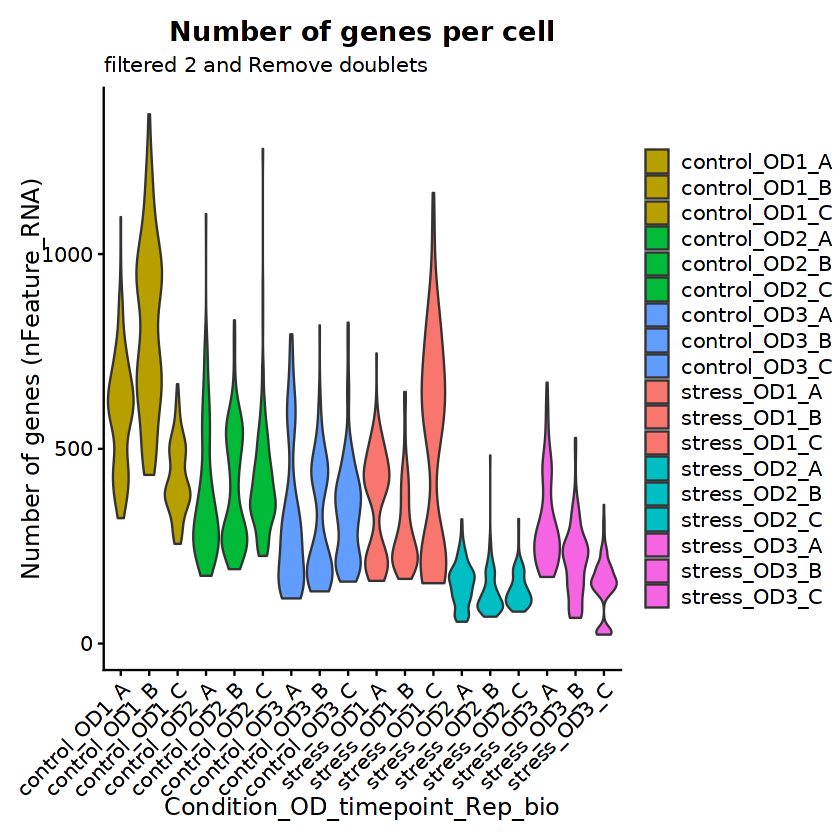

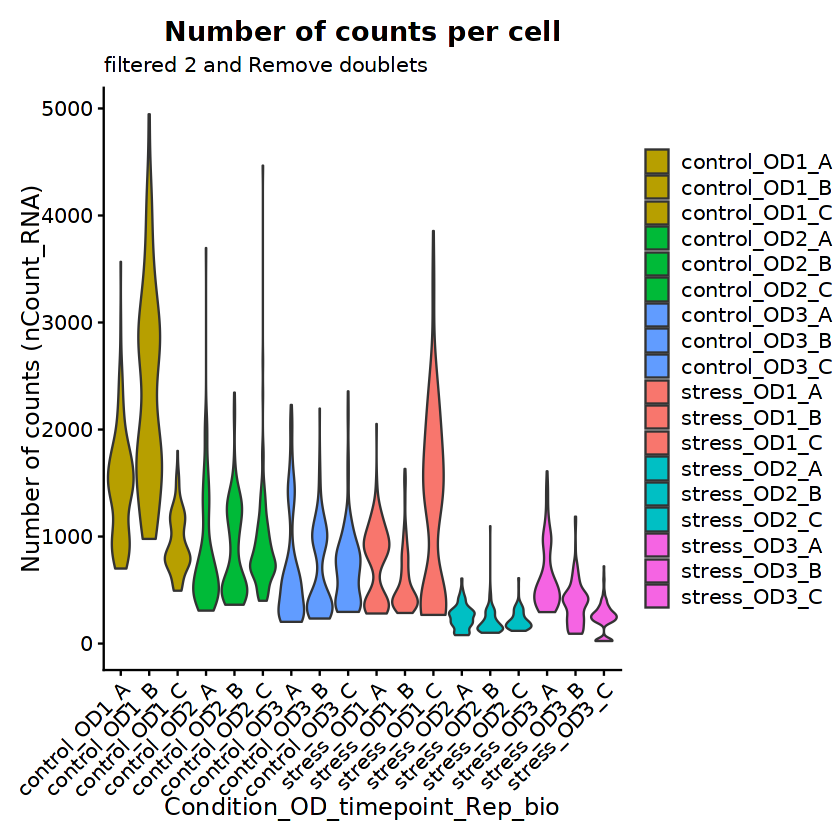

Picking joint bandwidth of 0.066



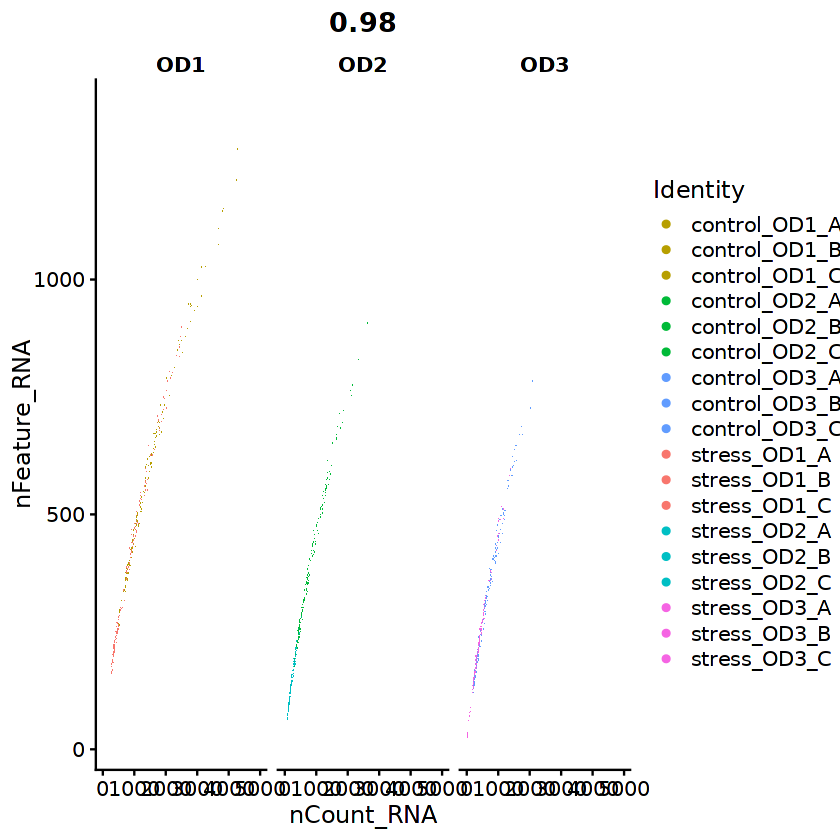

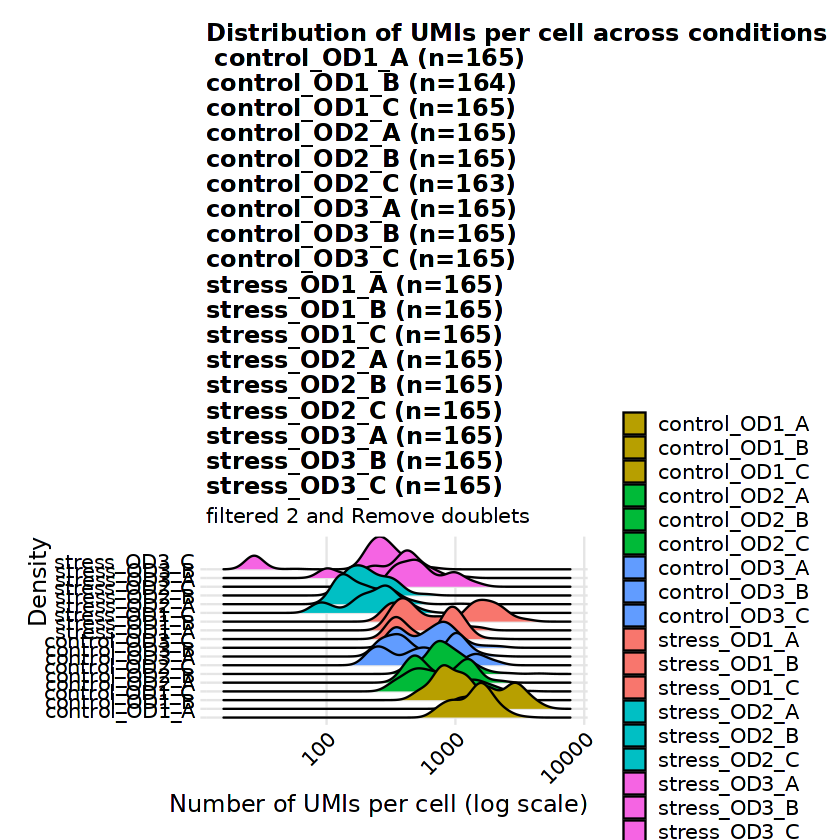

In [91]:
plots_without_point <- generate_qc_plots(
    seurat_obj = seurat_obj_Rm_doublets,
    subtitle = "filtered 2 and Remove doublets ",
    group.by = "Condition_OD_timepoint_Rep_bio",
    split.by = "OD_timepoint",
    color.by = "Condition_OD_timepoint"  # palette auto générée
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4

In [92]:
summary_stats_sample <- seurat_obj_Rm_doublets@meta.data %>%
    group_by(Sample_ID) %>%
    summarise(
        n_cells = n(),
    ) |>
    tail((n <- 10))

View(summary_stats_sample)

Sample_ID,n_cells
<chr>,<int>
M9_C_2_OD3,33
M9_C_3_OD1,33
M9_C_3_OD2,33
M9_C_3_OD3,33
M9_C_4_OD1,33
M9_C_4_OD2,33
M9_C_4_OD3,33
M9_C_5_OD1,33
M9_C_5_OD2,33


In [93]:
# Filter by Sample - Remove specific sample
# The correct syntax is:
seurat_obj_Rm_doublets_Rmbad <- subset(seurat_obj_Rm_doublets, subset = Sample_ID != "M9_C_3_OD3")

# Summary statistics by Culture_medium for original object
summary_stats_sample <- seurat_obj_Rm_doublets@meta.data %>%
    group_by(Culture_medium) %>%
    summarise(
        n_cells = n(),
    )
print(summary_stats_sample)



# Summary statistics by Culture_medium for filtered object
summary_stats_sample_filtered <- seurat_obj_Rm_doublets_Rmbad@meta.data %>%
    group_by(Culture_medium) %>%
    summarise(
        n_cells = n(),
    )
print(summary_stats_sample_filtered)


# A tibble: 2 x 2
  Culture_medium n_cells
  <chr>            <int>
1 M9                1485
2 M9F               1482
# A tibble: 2 x 2
  Culture_medium n_cells
  <chr>            <int>
1 M9                1452
2 M9F               1482


In [94]:
# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_Rm_doublets_Rmbad,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)
# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_Rm_doublets_Rmbad,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5975,1,2277532,1022383,79,320,539,1038.75,4945.999,668.627,56,187,348.46,284.5,465.75,1359,215.909


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5975,1.000,2277532,1022383,79,320.0,539.0,1038.75,4945.999,668.627,56,187.0,348.460,284.5,465.75,1359,215.909
M9F_A_1_OD1,33,4168,0.698,67632,24725,1649,1796.0,1929.0,2164.00,3567.000,391.893,642,673.0,749.242,732.0,769.00,1095,94.156
M9F_A_1_OD2,33,2570,0.430,17426,9234,435,457.0,479.0,554.00,828.000,108.448,230,253.0,279.818,260.0,300.00,420,47.586
M9F_A_1_OD3,33,2893,0.484,23282,11320,539,577.0,634.0,771.00,1474.000,189.220,266,293.0,343.030,326.0,375.00,577,67.219
M9F_A_2_OD1,33,3235,0.541,29970,13772,701,740.0,817.0,1001.00,1413.000,215.936,322,360.0,417.333,391.0,446.00,596,76.815
M9F_A_2_OD2,33,3885,0.650,52028,20735,1245,1346.0,1524.0,1702.00,2149.000,277.290,521,557.0,628.333,614.0,684.00,794,81.132
M9F_A_2_OD3,33,1664,0.278,8110,4760,203,215.0,225.0,258.00,441.000,49.440,116,131.0,144.242,136.0,154.00,217,23.049
M9F_A_3_OD1,33,3462,0.579,36867,16180,859,947.0,1039.0,1248.00,1710.000,237.819,408,440.0,490.303,463.0,523.00,673,75.073
M9F_A_3_OD2,33,2270,0.380,13160,7466,308,336.0,371.0,434.00,801.000,107.860,174,199.0,226.242,217.0,239.00,424,50.695


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


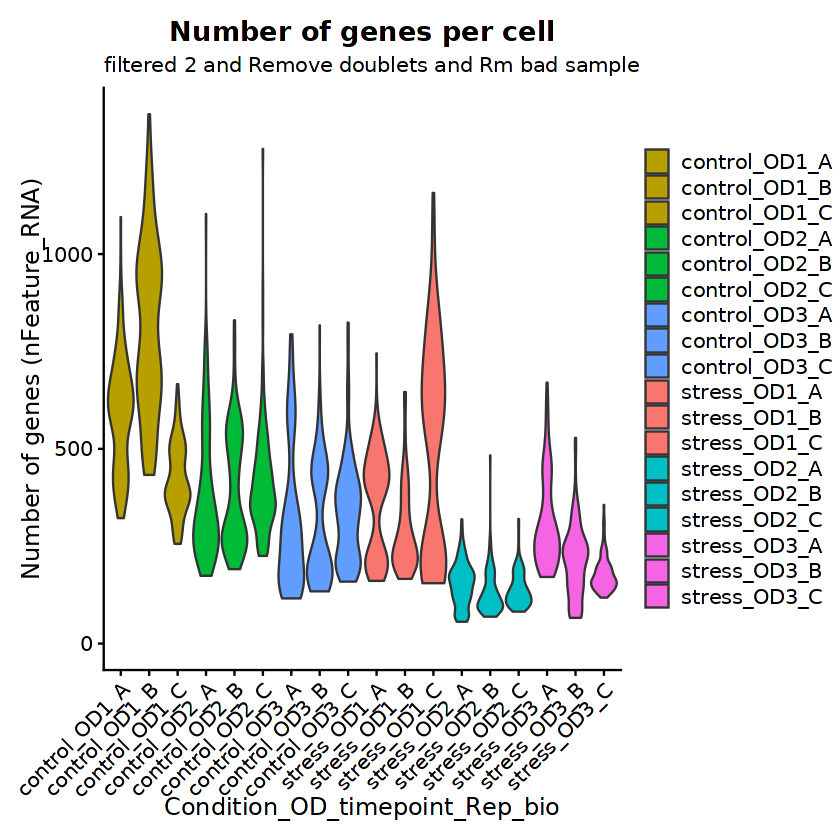

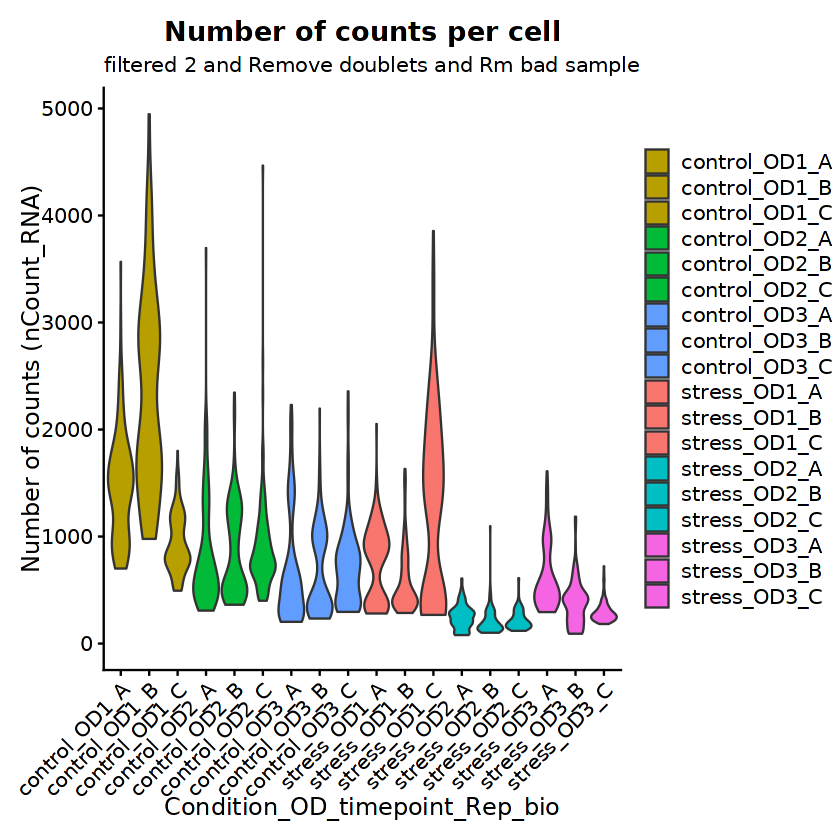

Picking joint bandwidth of 0.0657



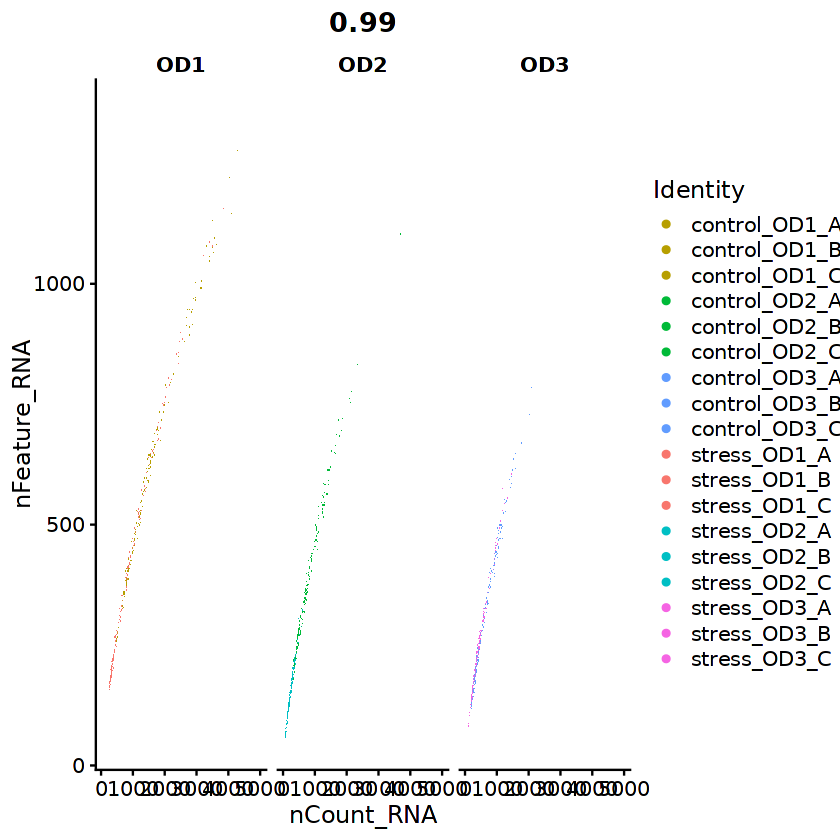

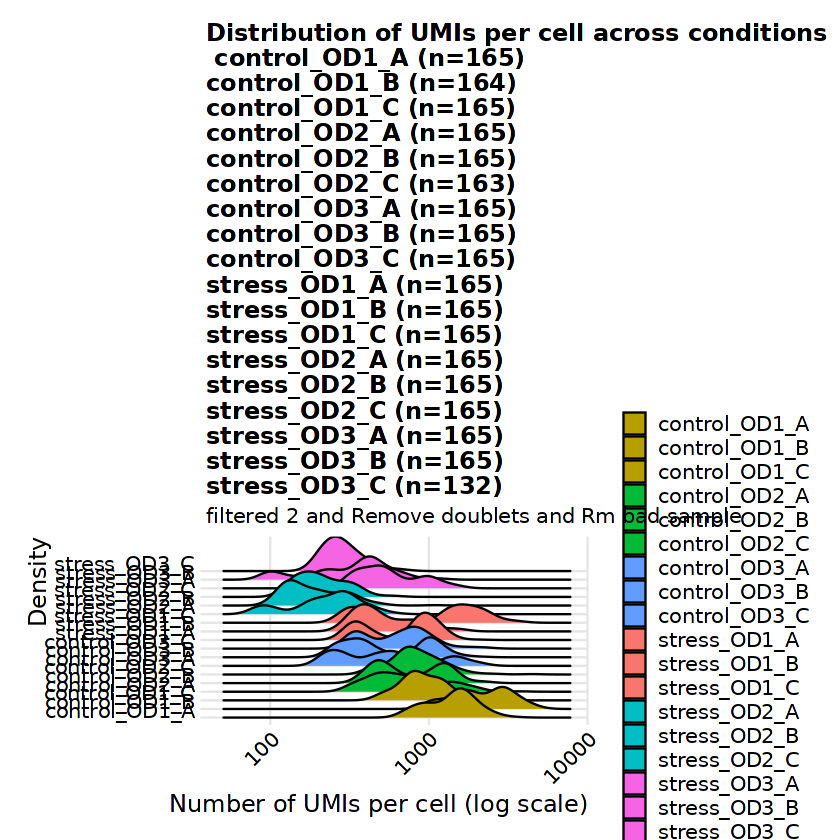

In [95]:
plots_without_point <- generate_qc_plots(
    seurat_obj = seurat_obj_Rm_doublets_Rmbad,
    subtitle = "filtered 2 and Remove doublets and Rm bad sample",
    group.by = "Condition_OD_timepoint_Rep_bio",
    split.by = "OD_timepoint",
    color.by = "Condition_OD_timepoint"  # palette auto générée
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4

hypothese  ARN mobile  (extracellulaire, ou lyse) qui expliquerait niveau globalement elever dans non stressé DO1 , car certaines cellules de cette DO on été éliminé mais avait des niveaux bien plus elvé que non strressé.

## Filtering of Genes in the Seurat Object

### Only keep mRNA (CDS)

In [96]:
# Filter to conserve only CDS genes in seq_type

cat("\nGene annotation information:\n")
cat("Number of features in Seurat object:", nrow(seurat_obj_Rm_doublets_Rmbad), "\n")


# use dplyr to summarize the feature metadata if available
if ("RNA" %in% names(seurat_obj_Rm_doublets_Rmbad@assays)) {
  feature_metadata <- seurat_obj_Rm_doublets_Rmbad[["RNA"]][[]]
  # Summarize each column using dplyr
  metadata_summary <- feature_metadata %>%
    summarise(across(everything(), ~ n_distinct(.)))
  cat("\nNumber of unique values in each feature annotation column:\n")
  print(metadata_summary)
  # Optionally, show unique values for specific columns if they exist
  if ("feature" %in% colnames(feature_metadata)) {
    cat("\nUnique values in feature column:\n")
    print(unique(feature_metadata$feature))
  }
}



Gene annotation information:
Number of features in Seurat object: 6248 

Number of unique values in each feature annotation column:
  seq_type feature class product_accession name symbol locus_tag symbol_old
1        2       5     6              6100 3171   1318      6248       1186
  locus_tag_old symbol_renamed final_gene_name
1          6248              2            6248

Unique values in feature column:
[1] "rRNA"  "tRNA"  "CDS"   "tmRNA" "ncRNA"


In [97]:
# View the feature type distribution for CDS-filtered object
feature_metadata <- seurat_obj_Rm_doublets_Rmbad[["RNA"]][[]]

feature_summary <- feature_metadata %>%
    count(feature) %>%
    mutate(percentage = round(n / sum(n) * 100, 2)) %>%
    arrange(desc(n))

View(feature_summary)

feature,n,percentage
<chr>,<int>,<dbl>
CDS,6162,98.62
tRNA,65,1.04
rRNA,16,0.26
ncRNA,4,0.06
tmRNA,1,0.02


### Filter CDS genes


In [98]:
seurat_obj_f_CDS <- filter_seurat_by_gene_type(seurat_obj_Rm_doublets_Rmbad, gene_types_to_keep = c("CDS"))

=== Loading Seurat object ===
Extracting gene metadata...

--- Gene type distribution BEFORE filtering ---
  feature    n percentage
1     CDS 6162      98.62
2    tRNA   65       1.04
3    rRNA   16       0.26
4   ncRNA    4       0.06
5   tmRNA    1       0.02

Filtering genes by types: CDS 
Number of genes to keep: 6162 

--- Gene type distribution AFTER filtering ---
  feature    n
1     CDS 6162

Creating filtered Seurat object...

--- Filtered Seurat object statistics ---
Number of cells: 2934 
Number of genes: 6162 

--- Metadata overview ---
Dimensions: 2934 19 
Columns: nCount_RNA, nFeature_RNA, barcode.rd1, barcode.rd2, barcode.rd3, Well_loc_rd1, Well_loc_rd2, Well_loc_rd3, Sample_ID, Culture_medium, Rep_bio, Rep_tech, OD_timepoint, OD_theoric, OD_measured, Condition, Condition_OD_timepoint, Rep, Condition_OD_timepoint_Rep_bio 
First 6 rows:
                           nCount_RNA nFeature_RNA barcode.rd1 barcode.rd2
GTACGCAA_AACCGAGA_AAACGATA        356          195    AAACGAT

### Nombre global de Gene CDS dans les metadonnées 

In [99]:
# View the feature type distribution for CDS-filtered object
feature_metadata <- seurat_obj_f_CDS[["RNA"]][[]]

feature_summary <- feature_metadata %>%
    count(feature) %>%
    mutate(percentage = round(n / sum(n) * 100, 2)) %>%
    arrange(desc(n))

View(feature_summary)

feature,n,percentage
<chr>,<int>,<dbl>
CDS,6162,100


6162 CDS dans les métadonnées 

In [100]:
# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)



Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5889,1,2277532,1022383,79,320,539,1038.75,4945.999,668.627,56,187,348.46,284.5,465.75,1359,215.909


Sur les 6162 CDS, 5889 sont detected au global sont dans les données 

5889 / 6162 = 0,96 % 


il serait possible d'optimiser ma fonction summary pour calculer ratio correct sur l'ensemble des genes annotés plutot que sur le nombre de gènes détectés dans les données au global.

ou pivot et merge 

In [101]:
 # Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS,
               #  export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)

Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5889,1.000,2277532,1022383,79,320.0,539.0,1038.75,4945.999,668.627,56,187.0,348.460,284.5,465.75,1359,215.909
M9F_A_1_OD1,33,4087,0.694,67632,24725,1649,1796.0,1929.0,2164.00,3567.000,391.893,642,673.0,749.242,732.0,769.00,1095,94.156
M9F_A_1_OD2,33,2498,0.424,17426,9234,435,457.0,479.0,554.00,828.000,108.448,230,253.0,279.818,260.0,300.00,420,47.586
M9F_A_1_OD3,33,2822,0.479,23282,11320,539,577.0,634.0,771.00,1474.000,189.220,266,293.0,343.030,326.0,375.00,577,67.219
M9F_A_2_OD1,33,3162,0.537,29970,13772,701,740.0,817.0,1001.00,1413.000,215.936,322,360.0,417.333,391.0,446.00,596,76.815
M9F_A_2_OD2,33,3805,0.646,52028,20735,1245,1346.0,1524.0,1702.00,2149.000,277.290,521,557.0,628.333,614.0,684.00,794,81.132
M9F_A_2_OD3,33,1603,0.272,8110,4760,203,215.0,225.0,258.00,441.000,49.440,116,131.0,144.242,136.0,154.00,217,23.049
M9F_A_3_OD1,33,3385,0.575,36867,16180,859,947.0,1039.0,1248.00,1710.000,237.819,408,440.0,490.303,463.0,523.00,673,75.073
M9F_A_3_OD2,33,2210,0.375,13160,7466,308,336.0,371.0,434.00,801.000,107.860,174,199.0,226.242,217.0,239.00,424,50.695


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


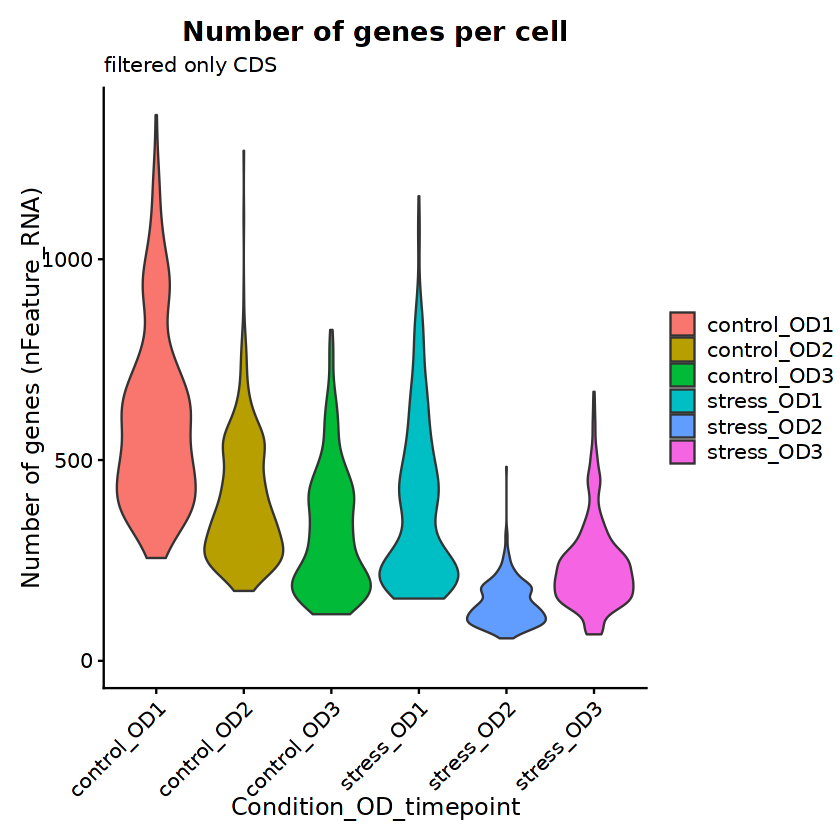

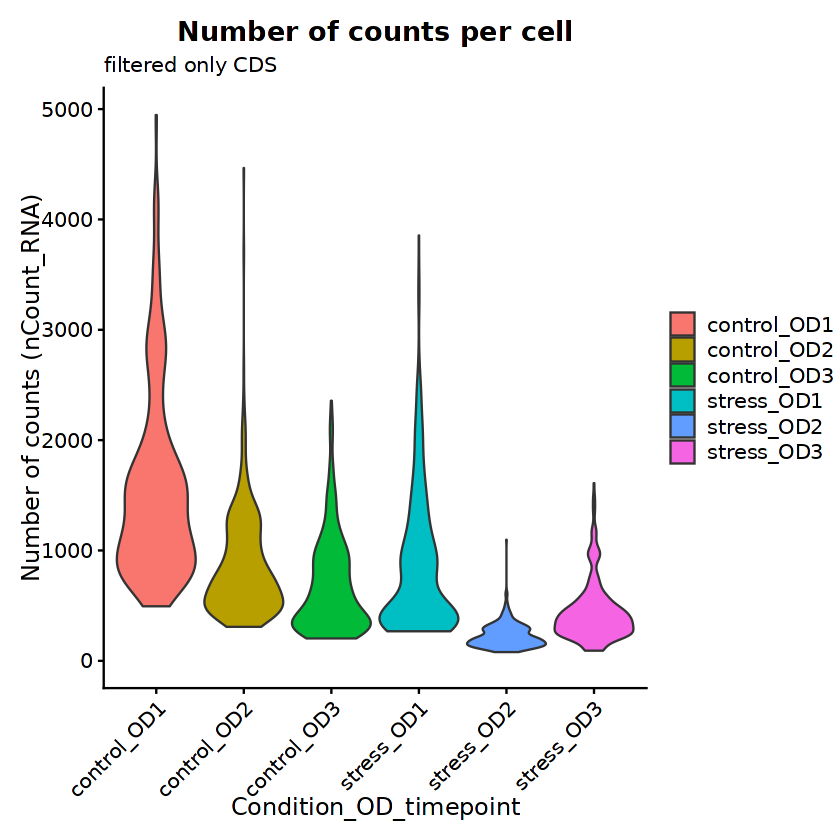

Picking joint bandwidth of 0.0598



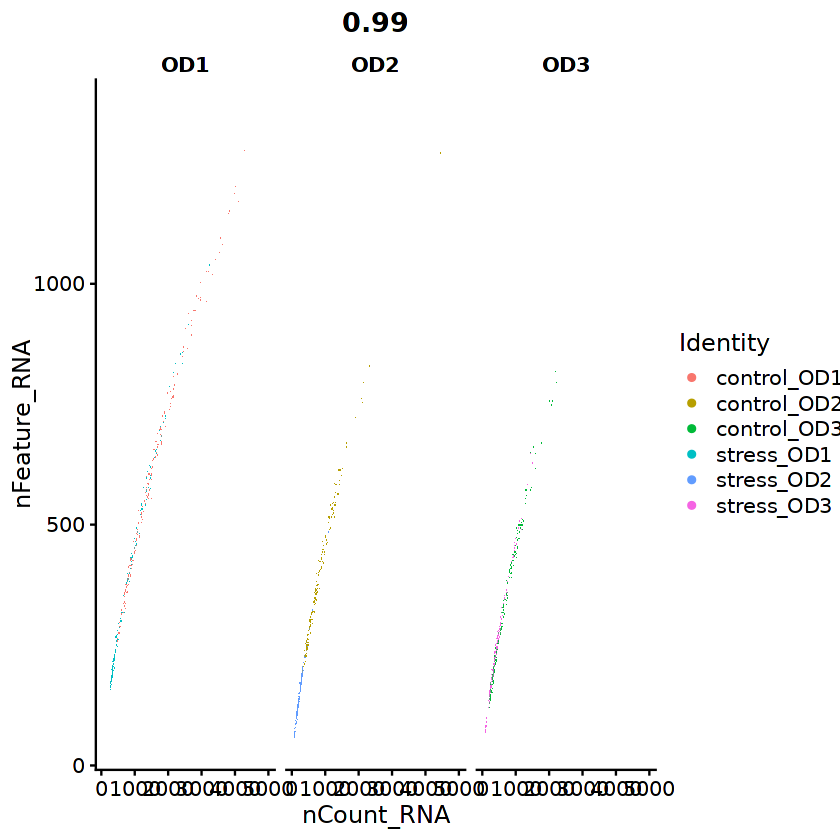

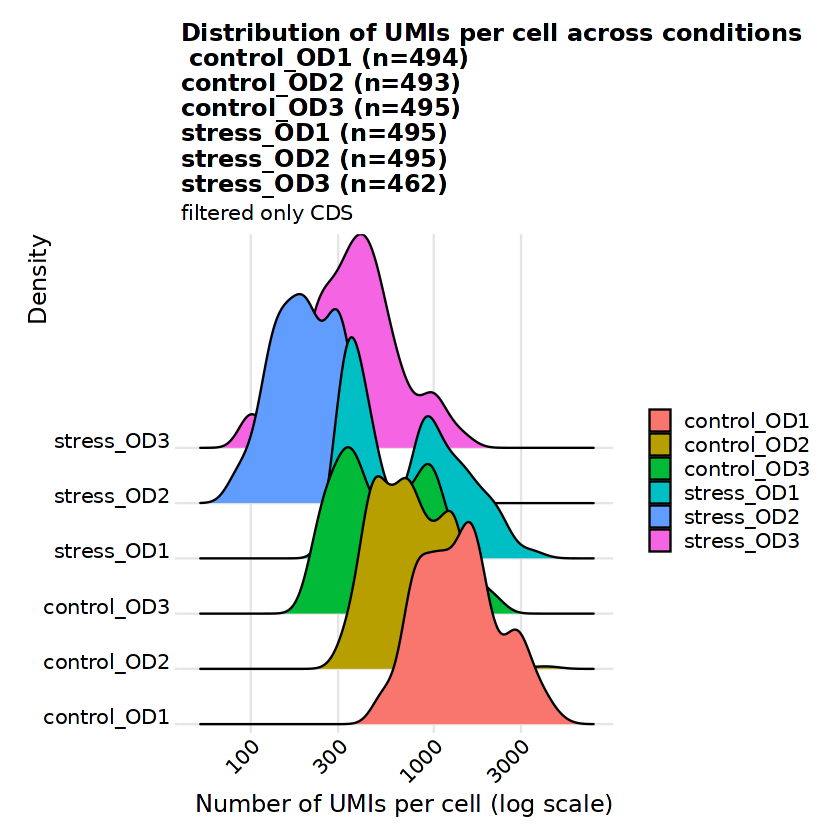

In [102]:
plots_without_point <- generate_qc_plots(
    seurat_obj = seurat_obj_f_CDS,
    subtitle = "filtered only CDS",
    group.by = "Condition_OD_timepoint",
    split.by = "OD_timepoint",
    show.points = FALSE
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4

In [103]:
# Display available columns
cat("\nAvailable columns in metadata of cells (or barcodes because there are not filtered for the moment)):\n")
colnames(seurat_obj@meta.data)
head(seurat_obj)


Available columns in metadata of cells (or barcodes because there are not filtered for the moment)):


[1] "nCount_RNA"                     "nFeature_RNA"                  
 [3] "barcode.rd1"                    "barcode.rd2"                   
 [5] "barcode.rd3"                    "Well_loc_rd1"                  
 [7] "Well_loc_rd2"                   "Well_loc_rd3"                  
 [9] "Sample_ID"                      "Culture_medium"                
[11] "Rep_bio"                        "Rep_tech"                      
[13] "OD_timepoint"                   "OD_theoric"                    
[15] "OD_measured"                    "Condition"                     
[17] "Condition_OD_timepoint"         "Rep"                           
[19] "Condition_OD_timepoint_Rep_bio"

,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
AAACATCG_AAACATCG_AAACGATA,49,44,AAACGATA,AAACATCG,AAACATCG,A2,A2,A2,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACAACCA_AAACATCG_AAACGATA,8,14,AAACGATA,AAACATCG,AACAACCA,A2,A2,B1,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACCGAGA_AAACATCG_AAACGATA,33,34,AAACGATA,AAACATCG,AACCGAGA,A2,A2,B2,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACGCTTA_AAACATCG_AAACGATA,119,89,AAACGATA,AAACATCG,AACGCTTA,A2,A2,B3,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACGTGAT_AAACATCG_AAACGATA,2,10,AAACGATA,AAACATCG,AACGTGAT,A2,A2,A1,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AACTCACC_AAACATCG_AAACGATA,1,5,AAACGATA,AAACATCG,AACTCACC,A2,A2,F9,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AAGACGGA_AAACATCG_AAACGATA,2,5,AAACGATA,AAACATCG,AAGACGGA,A2,A2,B4,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AAGAGATC_AAACATCG_AAACGATA,0,0,AAACGATA,AAACATCG,AAGAGATC,A2,A2,F10,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
AAGGACAC_AAACATCG_AAACGATA,29,29,AAACGATA,AAACATCG,AAGGACAC,A2,A2,F11,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


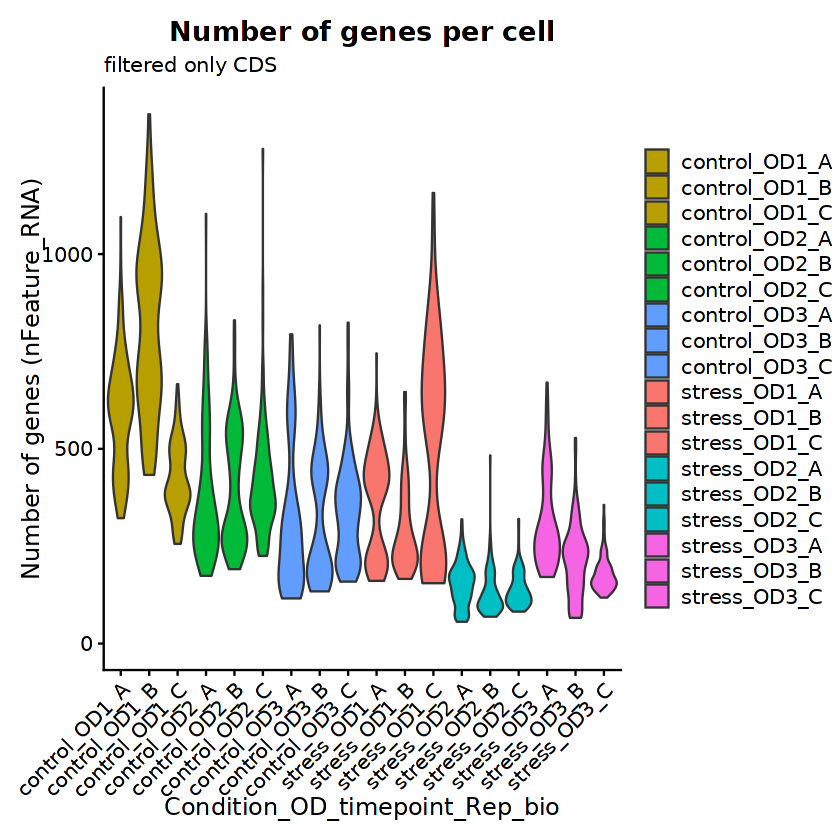

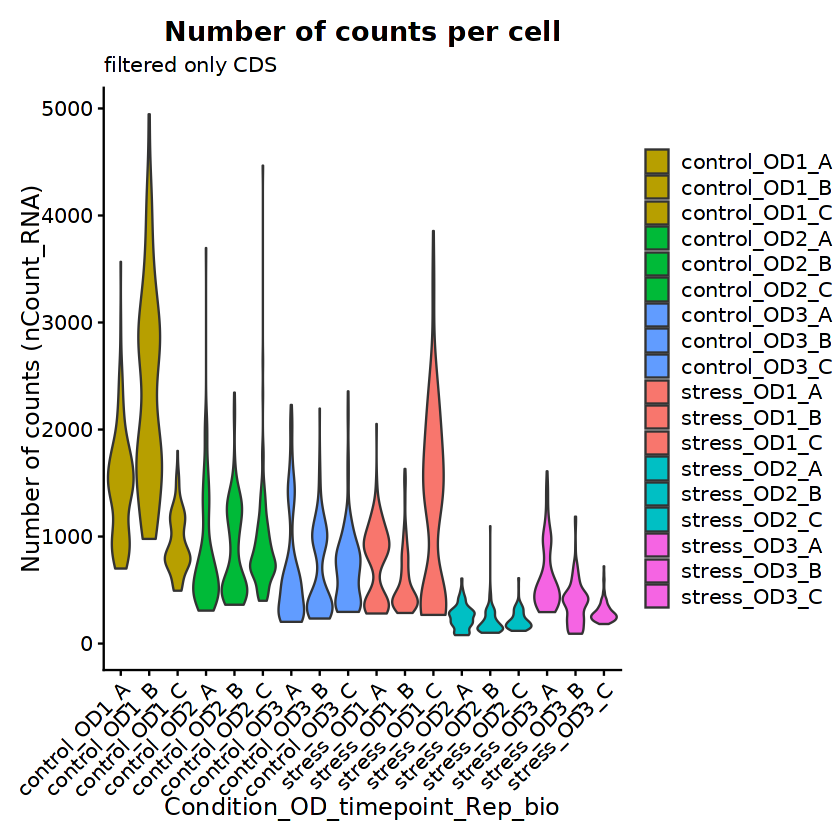

Picking joint bandwidth of 0.0657



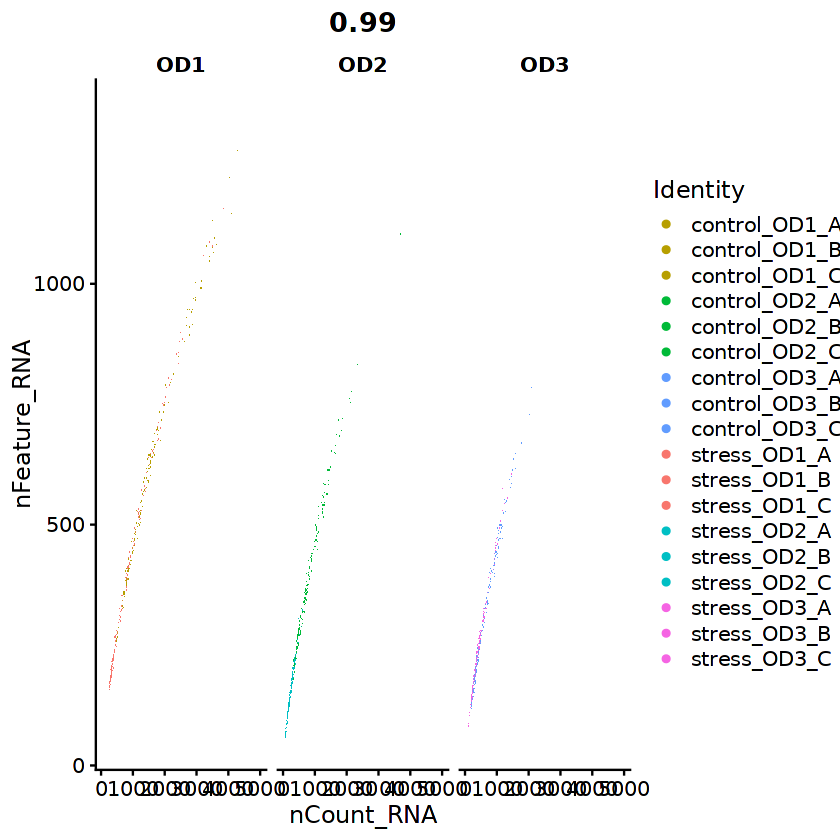

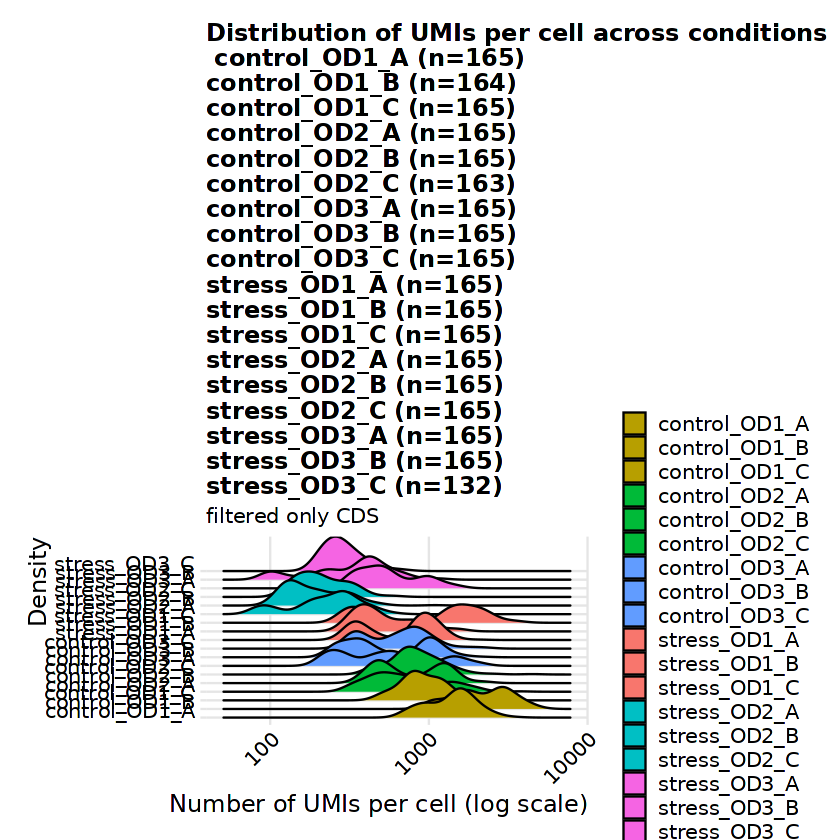

In [104]:
plots_without_point <- generate_qc_plots(
    seurat_obj = seurat_obj_f_CDS,
    subtitle = "filtered only CDS",
    group.by = "Condition_OD_timepoint_Rep_bio",
    split.by = "OD_timepoint",
    color.by = "Condition_OD_timepoint"  # palette auto générée
)

# Afficher les plots
plots_without_point$p1
plots_without_point$p2
plots_without_point$scatter_p3
plots_without_point$ridge_p4

## Filter on minimum gene expression throughout the dataset

#### Min in 3 cells

In [105]:
# test with 3 cells
min.cells <- 3
# Identify genes expressed in at least min.cells cells
counts <- GetAssayData(seurat_obj_f_CDS, layer = "counts")
genes_to_keep_3cell <- rowSums(counts > 0) >= min.cells

# Subset Seurat object
seurat_obj_f_CDS_3cells <- subset(seurat_obj_f_CDS, features = names(genes_to_keep_3cell[genes_to_keep_3cell]))

# Calculate statistics for 5 cells filter
cat("\n=== Statistics for seurat_obj_f_CDS_3cells (min 3 cells per gene) ===\n")
cat("\nnFeature_RNA statistics:\n")
print(summary(seurat_obj_f_CDS_3cells$nFeature_RNA))
cat("\nnCount_RNA statistics:\n")
print(summary(seurat_obj_f_CDS_3cells$nCount_RNA))
cat("\nNumber of cells:", ncol(seurat_obj_f_CDS_3cells), "\n")
cat("Number of genes:", nrow(seurat_obj_f_CDS_3cells), "\n")

removed_genes5cell <- nrow(seurat_obj_f_CDS) - nrow(seurat_obj_f_CDS_3cells)
cat("\nNumber of genes removed by filtering (min 3 cells):", removed_genes5cell, "\n")



=== Statistics for seurat_obj_f_CDS_3cells (min 3 cells per gene) ===

nFeature_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   56.0   187.0   284.5   348.5   465.8  1359.0 

nCount_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   79.0   320.0   539.0   776.3  1038.7  4946.0 

Number of cells: 2934 
Number of genes: 5694 

Number of genes removed by filtering (min 3 cells): 468 


In [106]:
# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS_3cells,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)

# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS_3cells,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)

Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5694,1,2277532,1022383,79,320,539,1038.75,4945.999,668.627,56,187,348.46,284.5,465.75,1359,215.909


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5694,1.000,2277532,1022383,79,320.0,539.0,1038.75,4945.999,668.627,56,187.0,348.460,284.5,465.75,1359,215.909
M9F_A_1_OD1,33,4081,0.717,67632,24725,1649,1796.0,1929.0,2164.00,3567.000,391.893,642,673.0,749.242,732.0,769.00,1095,94.156
M9F_A_1_OD2,33,2495,0.438,17426,9234,435,457.0,479.0,554.00,828.000,108.448,230,253.0,279.818,260.0,300.00,420,47.586
M9F_A_1_OD3,33,2818,0.495,23282,11320,539,577.0,634.0,771.00,1474.000,189.220,266,293.0,343.030,326.0,375.00,577,67.219
M9F_A_2_OD1,33,3155,0.554,29970,13772,701,740.0,817.0,1001.00,1413.000,215.936,322,360.0,417.333,391.0,446.00,596,76.815
M9F_A_2_OD2,33,3795,0.666,52028,20735,1245,1346.0,1524.0,1702.00,2149.000,277.290,521,557.0,628.333,614.0,684.00,794,81.132
M9F_A_2_OD3,33,1602,0.281,8110,4760,203,215.0,225.0,258.00,441.000,49.440,116,131.0,144.242,136.0,154.00,217,23.049
M9F_A_3_OD1,33,3377,0.593,36867,16180,859,947.0,1039.0,1248.00,1710.000,237.819,408,440.0,490.303,463.0,523.00,673,75.073
M9F_A_3_OD2,33,2210,0.388,13160,7466,308,336.0,371.0,434.00,801.000,107.860,174,199.0,226.242,217.0,239.00,424,50.695


#### Min in 5 cells

In [107]:
# test with 5 cells
min.cells <- 5
# Identify genes expressed in at least min.cells cells
counts <- GetAssayData(seurat_obj_f_CDS, layer = "counts")
genes_to_keep_5cell <- rowSums(counts > 0) >= min.cells

# Subset Seurat object
seurat_obj_f_CDS_5cells <- subset(seurat_obj_f_CDS, features = names(genes_to_keep_5cell[genes_to_keep_5cell]))

# Calculate statistics for 5 cells filter
cat("\n=== Statistics for seurat_obj_f_CDS_5cells (min 5 cells per gene) ===\n")
cat("\nnFeature_RNA statistics:\n")
print(summary(seurat_obj_f_CDS_5cells$nFeature_RNA))
cat("\nnCount_RNA statistics:\n")
print(summary(seurat_obj_f_CDS_5cells$nCount_RNA))
cat("\nNumber of cells:", ncol(seurat_obj_f_CDS_5cells), "\n")
cat("Number of genes:", nrow(seurat_obj_f_CDS_5cells), "\n")

removed_genes5cell <- nrow(seurat_obj_f_CDS) - nrow(seurat_obj_f_CDS_5cells)
cat("\nNumber of genes removed by filtering (min 5 cells):", removed_genes5cell, "\n")


=== Statistics for seurat_obj_f_CDS_5cells (min 5 cells per gene) ===

nFeature_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   56.0   187.0   284.5   348.5   465.8  1359.0 

nCount_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   79.0   320.0   539.0   776.3  1038.7  4946.0 

Number of cells: 2934 
Number of genes: 5491 

Number of genes removed by filtering (min 5 cells): 671 


In [108]:
# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS_5cells,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)

# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS_5cells,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)

Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5491,1,2277532,1022383,79,320,539,1038.75,4945.999,668.627,56,187,348.46,284.5,465.75,1359,215.909


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5491,1.000,2277532,1022383,79,320.0,539.0,1038.75,4945.999,668.627,56,187.0,348.460,284.5,465.75,1359,215.909
M9F_A_1_OD1,33,4060,0.739,67632,24725,1649,1796.0,1929.0,2164.00,3567.000,391.893,642,673.0,749.242,732.0,769.00,1095,94.156
M9F_A_1_OD2,33,2488,0.453,17426,9234,435,457.0,479.0,554.00,828.000,108.448,230,253.0,279.818,260.0,300.00,420,47.586
M9F_A_1_OD3,33,2809,0.512,23282,11320,539,577.0,634.0,771.00,1474.000,189.220,266,293.0,343.030,326.0,375.00,577,67.219
M9F_A_2_OD1,33,3142,0.572,29970,13772,701,740.0,817.0,1001.00,1413.000,215.936,322,360.0,417.333,391.0,446.00,596,76.815
M9F_A_2_OD2,33,3779,0.688,52028,20735,1245,1346.0,1524.0,1702.00,2149.000,277.290,521,557.0,628.333,614.0,684.00,794,81.132
M9F_A_2_OD3,33,1599,0.291,8110,4760,203,215.0,225.0,258.00,441.000,49.440,116,131.0,144.242,136.0,154.00,217,23.049
M9F_A_3_OD1,33,3367,0.613,36867,16180,859,947.0,1039.0,1248.00,1710.000,237.819,408,440.0,490.303,463.0,523.00,673,75.073
M9F_A_3_OD2,33,2205,0.402,13160,7466,308,336.0,371.0,434.00,801.000,107.860,174,199.0,226.242,217.0,239.00,424,50.695


In [109]:
# test with 10 cells
min.cells <- 10
# Identify genes expressed in at least min.cells cells
counts <- GetAssayData(seurat_obj_f_CDS, layer = "counts")
genes_to_keep_10cell <- rowSums(counts > 0) >= min.cells

# Subset Seurat object
seurat_obj_f_CDS_10cells <- subset(seurat_obj_f_CDS, features = names(genes_to_keep_10cell[genes_to_keep_10cell]))

# Calculate statistics for 10 cells filter
cat("\n=== Statistics for seurat_obj_f_CDS_10cells (min 10 cells per gene) ===\n")
cat("\nnFeature_RNA statistics:\n")
print(summary(seurat_obj_f_CDS_10cells$nFeature_RNA))
cat("\nnCount_RNA statistics:\n")
print(summary(seurat_obj_f_CDS_10cells$nCount_RNA))
cat("\nNumber of cells:", ncol(seurat_obj_f_CDS_10cells), "\n")
cat("Number of genes:", nrow(seurat_obj_f_CDS_10cells), "\n")

removed_genes10cell <- nrow(seurat_obj_f_CDS) - nrow(seurat_obj_f_CDS_10cells)
cat("\nNumber of genes removed by filtering (min 10 cells):", removed_genes10cell, "\n")


=== Statistics for seurat_obj_f_CDS_10cells (min 10 cells per gene) ===

nFeature_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   56.0   187.0   284.5   348.5   465.8  1359.0 

nCount_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   79.0   320.0   539.0   776.3  1038.7  4946.0 

Number of cells: 2934 
Number of genes: 5088 

Number of genes removed by filtering (min 10 cells): 1074 


In [110]:
# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS_10cells,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)

# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS_10cells,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)

Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5088,1,2277532,1022383,79,320,539,1038.75,4945.999,668.627,56,187,348.46,284.5,465.75,1359,215.909


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,5088,1.000,2277532,1022383,79,320.0,539.0,1038.75,4945.999,668.627,56,187.0,348.460,284.5,465.75,1359,215.909
M9F_A_1_OD1,33,3995,0.785,67632,24725,1649,1796.0,1929.0,2164.00,3567.000,391.893,642,673.0,749.242,732.0,769.00,1095,94.156
M9F_A_1_OD2,33,2465,0.484,17426,9234,435,457.0,479.0,554.00,828.000,108.448,230,253.0,279.818,260.0,300.00,420,47.586
M9F_A_1_OD3,33,2784,0.547,23282,11320,539,577.0,634.0,771.00,1474.000,189.220,266,293.0,343.030,326.0,375.00,577,67.219
M9F_A_2_OD1,33,3105,0.610,29970,13772,701,740.0,817.0,1001.00,1413.000,215.936,322,360.0,417.333,391.0,446.00,596,76.815
M9F_A_2_OD2,33,3716,0.730,52028,20735,1245,1346.0,1524.0,1702.00,2149.000,277.290,521,557.0,628.333,614.0,684.00,794,81.132
M9F_A_2_OD3,33,1589,0.312,8110,4760,203,215.0,225.0,258.00,441.000,49.440,116,131.0,144.242,136.0,154.00,217,23.049
M9F_A_3_OD1,33,3324,0.653,36867,16180,859,947.0,1039.0,1248.00,1710.000,237.819,408,440.0,490.303,463.0,523.00,673,75.073
M9F_A_3_OD2,33,2189,0.430,13160,7466,308,336.0,371.0,434.00,801.000,107.860,174,199.0,226.242,217.0,239.00,424,50.695


In [111]:
# test with 20 cells
min.cells <- 20
# Identify genes expressed in at least min.cells cells
counts <- GetAssayData(seurat_obj_f_CDS, layer = "counts")
genes_to_keep_20cell <- rowSums(counts > 0) >= min.cells

# Subset Seurat object
seurat_obj_f_CDS_20cells <- subset(seurat_obj_f_CDS, features = names(genes_to_keep_20cell[genes_to_keep_20cell]))

# Calculate statistics for 20 cells filter
cat("\n=== Statistics for seurat_obj_f_CDS_20cells (min 20 cells per gene) ===\n")
cat("\nnFeature_RNA statistics:\n")
print(summary(seurat_obj_f_CDS_20cells$nFeature_RNA))
cat("\nnCount_RNA statistics:\n")
print(summary(seurat_obj_f_CDS_10cells$nCount_RNA))
cat("\nNumber of cells:", ncol(seurat_obj_f_CDS_20cells), "\n")
cat("Number of genes:", nrow(seurat_obj_f_CDS_20cells), "\n")

removed_genes10cell <- nrow(seurat_obj_f_CDS) - nrow(seurat_obj_f_CDS_20cells)
cat("\nNumber of genes removed by filtering (min 20 cells):", removed_genes10cell, "\n")


=== Statistics for seurat_obj_f_CDS_20cells (min 20 cells per gene) ===

nFeature_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   56.0   187.0   284.5   348.5   465.8  1359.0 

nCount_RNA statistics:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   79.0   320.0   539.0   776.3  1038.7  4946.0 

Number of cells: 2934 
Number of genes: 4388 

Number of genes removed by filtering (min 20 cells): 1774 


In [112]:
# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS_20cells,
                 #export = "csv", 
                 #group_by ="Sample_ID",
                 auto_filename = TRUE)

# Export automatique en CSV avec nom auto généré
summarize_seurat(seurat_obj_f_CDS_20cells,
                 #export = "csv", 
                 group_by ="Sample_ID",
                 auto_filename = TRUE)

Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,4388,1,2277532,1022383,79,320,539,1038.75,4945.999,668.627,56,187,348.46,284.5,465.75,1359,215.909


Sample_ID,n_cells,n_genes_detected,gene_detection_ratio,sum_nCount_RNA,sum_nFeature_RNA,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Global,2934,4388,1.000,2277532,1022383,79,320.0,539.0,1038.75,4945.999,668.627,56,187.0,348.460,284.5,465.75,1359,215.909
M9F_A_1_OD1,33,3737,0.852,67632,24725,1649,1796.0,1929.0,2164.00,3567.000,391.893,642,673.0,749.242,732.0,769.00,1095,94.156
M9F_A_1_OD2,33,2397,0.546,17426,9234,435,457.0,479.0,554.00,828.000,108.448,230,253.0,279.818,260.0,300.00,420,47.586
M9F_A_1_OD3,33,2694,0.614,23282,11320,539,577.0,634.0,771.00,1474.000,189.220,266,293.0,343.030,326.0,375.00,577,67.219
M9F_A_2_OD1,33,2982,0.680,29970,13772,701,740.0,817.0,1001.00,1413.000,215.936,322,360.0,417.333,391.0,446.00,596,76.815
M9F_A_2_OD2,33,3513,0.801,52028,20735,1245,1346.0,1524.0,1702.00,2149.000,277.290,521,557.0,628.333,614.0,684.00,794,81.132
M9F_A_2_OD3,33,1556,0.355,8110,4760,203,215.0,225.0,258.00,441.000,49.440,116,131.0,144.242,136.0,154.00,217,23.049
M9F_A_3_OD1,33,3187,0.726,36867,16180,859,947.0,1039.0,1248.00,1710.000,237.819,408,440.0,490.303,463.0,523.00,673,75.073
M9F_A_3_OD2,33,2149,0.490,13160,7466,308,336.0,371.0,434.00,801.000,107.860,174,199.0,226.242,217.0,239.00,424,50.695


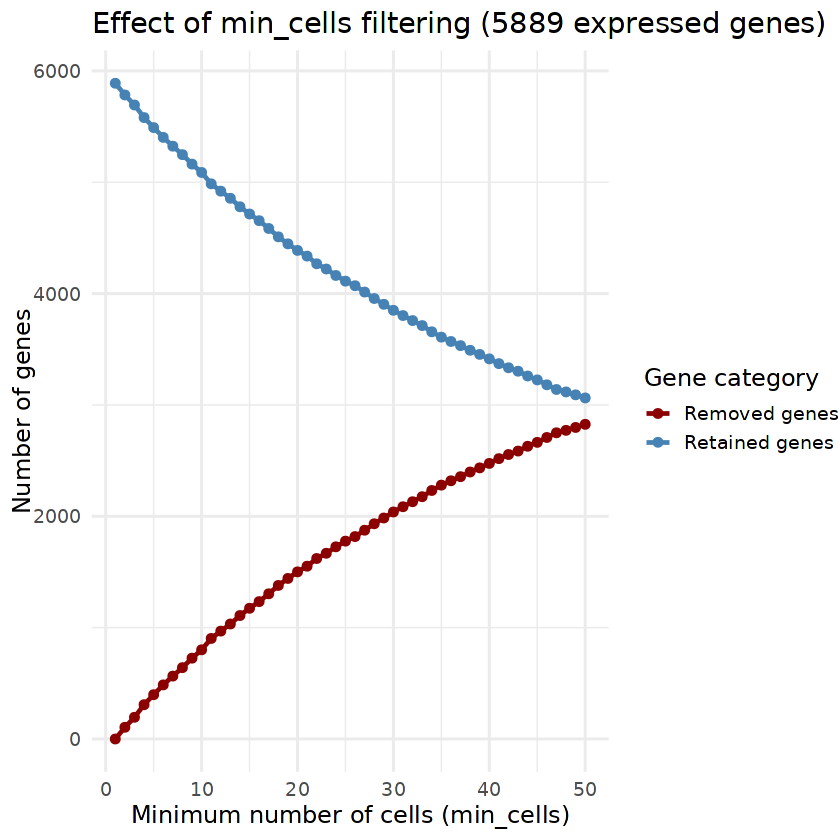

In [113]:
# Just display the plot
plot_gene_filtering_stats(seurat_obj_f_CDS, seq(1, 50, by = 1))

# # Display and save as PDF
# plot_gene_filtering_stats(
#   seurat_obj_f_CDS,
#   min_cells_vec = seq(1, 50, by = 1),
#   save_plot = FALSE,
#   filename = "filtering_plot_20cells",
#   format = "pdf"
# )

# # Save as PNG with higher resolution
# plot_gene_filtering_stats(
#   seurat_obj_f_CDS,
#   min_cells_vec = seq(1, 50, by = 1),
#   save_plot = FALSE,
#   filename = "filtering_plot_20cells",
#   format = "png",
#   dpi = 600
# )

# Save filtered Object : Seurat object 

## Save the RDS file 

In [114]:

dir.create("jupyter/correct/correct_V2/ScObjects", recursive = TRUE)
saveRDS(filtrer, "jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered.rds")
saveRDS(filtrer2, "jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered2.rds")
saveRDS(seurat_obj_Rm_doublets, "jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered_RmDoublets.rds")
saveRDS(seurat_obj_Rm_doublets_Rmbad, "jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered_RmDoublets_Rmbad.rds")
saveRDS(seurat_obj_f_CDS, "jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered_CDS.rds")
saveRDS(seurat_obj_f_CDS_3cells, "jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered_CDS_3cells.rds")
saveRDS(seurat_obj_f_CDS_5cells, "jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered_CDS_5cells.rds")
saveRDS(seurat_obj_f_CDS_10cells, "jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered_CDS_10cells.rds")
saveRDS(seurat_obj_f_CDS_20cells, "jupyter/correct/correct_V2/ScObjects/SeuratObject_Val_Filtered_CDS_20cells.rds")

Warning message in dir.create("jupyter/correct/correct_V2/ScObjects", recursive = TRUE):
"'jupyter/correct/correct_V2/ScObjects' already exists"


## Description avec Boxplot 

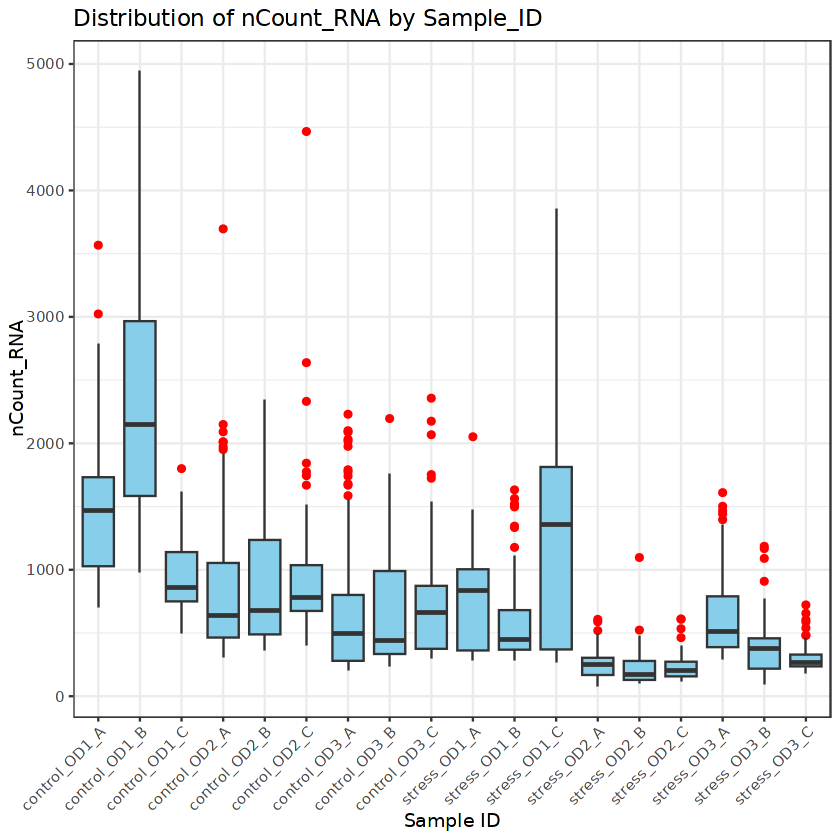

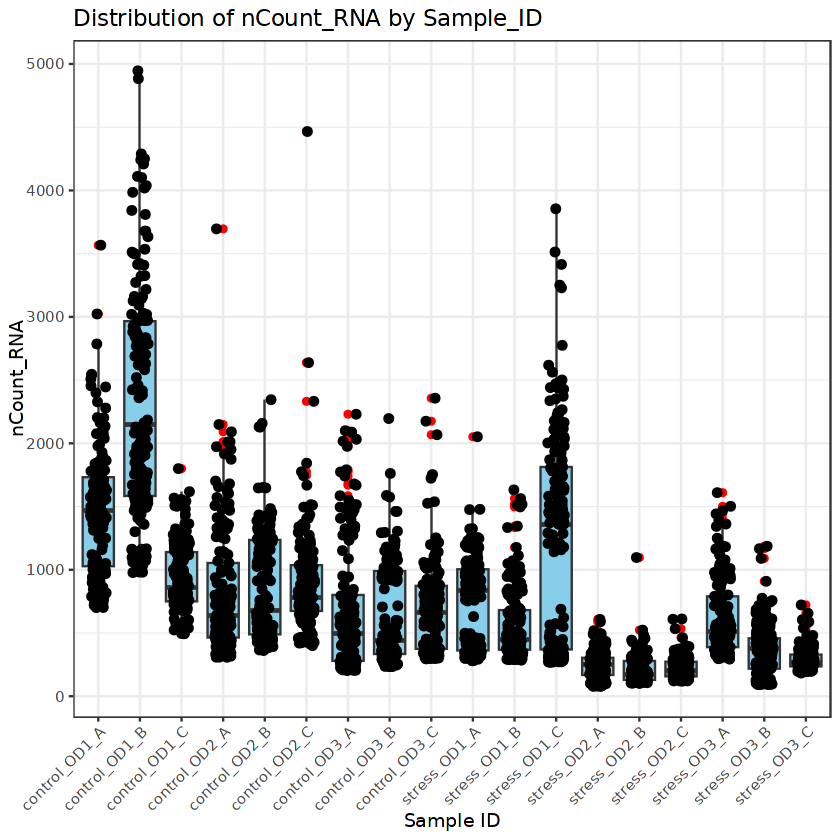

In [115]:
# Boxplot de nCount_RNA par Condition_OD_timepoint_Rep_bio

p1 <- seurat_obj_f_CDS_5cells@meta.data |>
  ggplot(aes(x = Condition_OD_timepoint_Rep_bio, y = nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  theme_bw() +
  labs(
    title = "Distribution of nCount_RNA by Sample_ID",
    x = "Sample ID",
    y = "nCount_RNA"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


p1

# if you want to add jitter points to the boxplot
p1 +
  geom_jitter(width = 0.2, size = 2, color = "black")


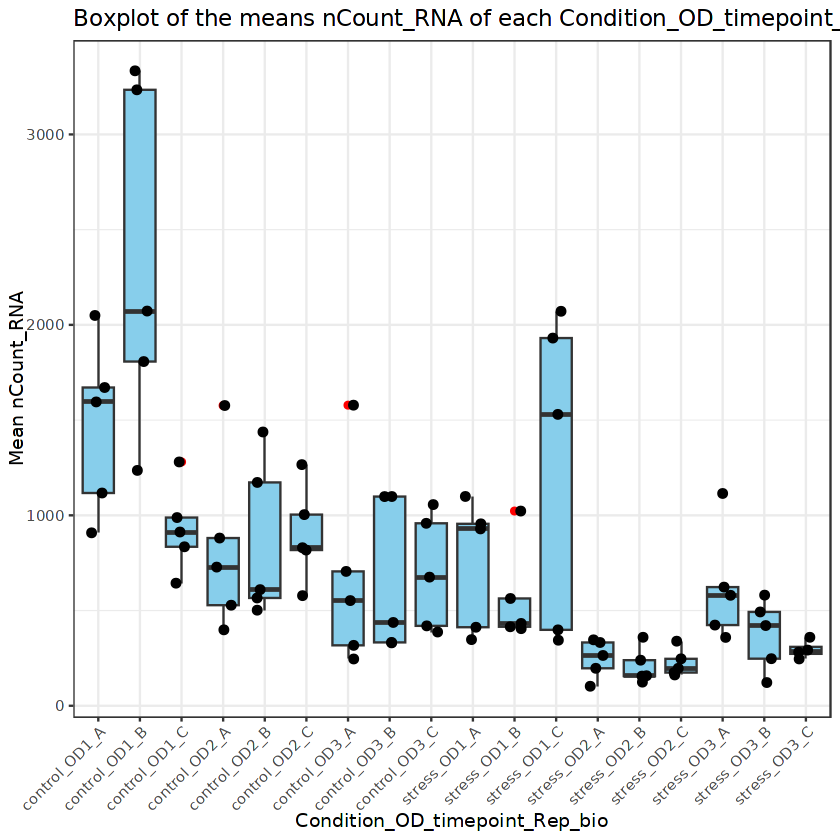

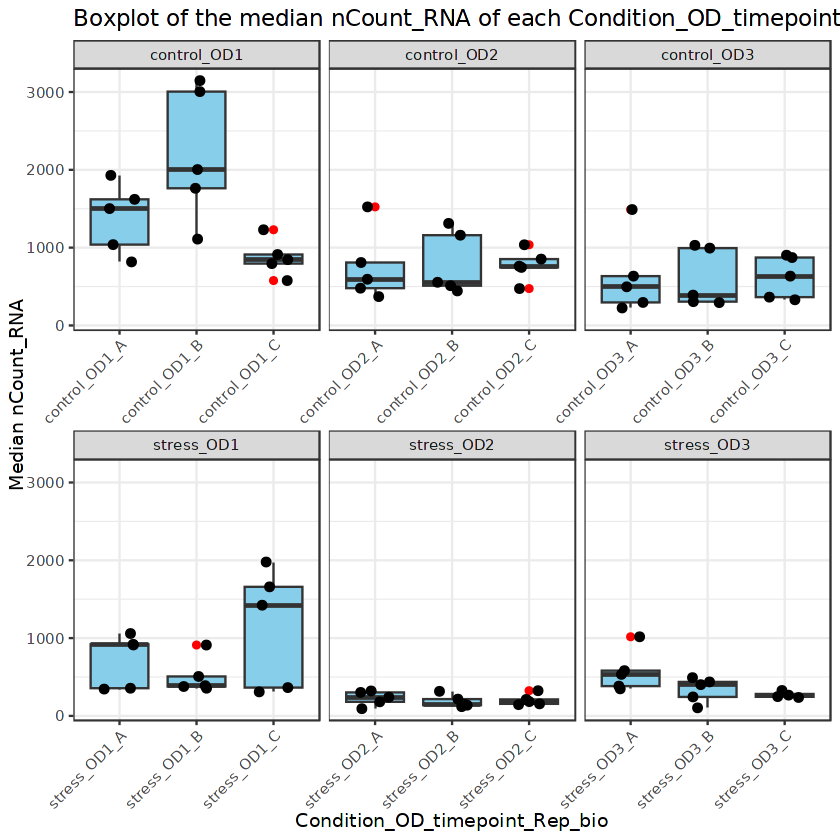

In [116]:
seurat_obj_f_CDS_5cells@meta.data %>%
  group_by(Condition_OD_timepoint_Rep_bio, , Sample_ID) %>%
  summarise(mean_nCount_RNA = mean(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint_Rep_bio, y = mean_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(width = 0.2, size = 2, color = "black") + # montre les points des Sample_ID
  theme_bw() +
  labs(
    title = "Boxplot of the means nCount_RNA of each Condition_OD_timepoint_Rep_bio (1 point = 1 repli tech)",
    x = "Condition_OD_timepoint_Rep_bio",
    y = "Mean nCount_RNA"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


seurat_obj_f_CDS_5cells@meta.data %>%
  group_by(Condition_OD_timepoint_Rep_bio, Condition_OD_timepoint, Sample_ID) %>%
  summarise(median_nCount_RNA = median(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint_Rep_bio, y = median_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(width = 0.2, size = 2, color = "black") + # montre les points des Sample_ID
  theme_bw() +
  labs(
    title = "Boxplot of the median nCount_RNA of each Condition_OD_timepoint_Rep_bio (1 point = 1 repli tech)",
    x = "Condition_OD_timepoint_Rep_bio",
    y = "Median nCount_RNA"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  facet_wrap(~Condition_OD_timepoint, scales = "free_x")


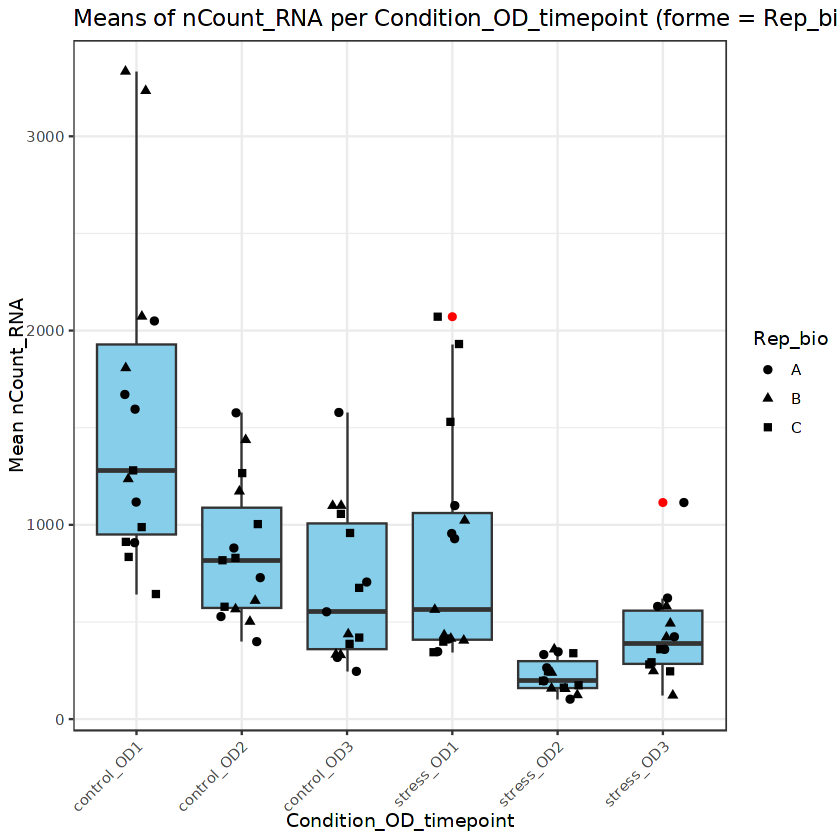

In [117]:
seurat_obj_f_CDS_10cells@meta.data %>%
  group_by(Condition_OD_timepoint, Sample_ID, Rep_bio) %>%
  summarise(mean_nCount_RNA = mean(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint, y = mean_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(aes(shape = Rep_bio), width = 0.2, size = 2, color = "black") +
  theme_bw() +
  labs(
    title = "Means of nCount_RNA per Condition_OD_timepoint (forme = Rep_bio)",
    x = "Condition_OD_timepoint",
    y = "Mean nCount_RNA",
    shape = "Rep_bio"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


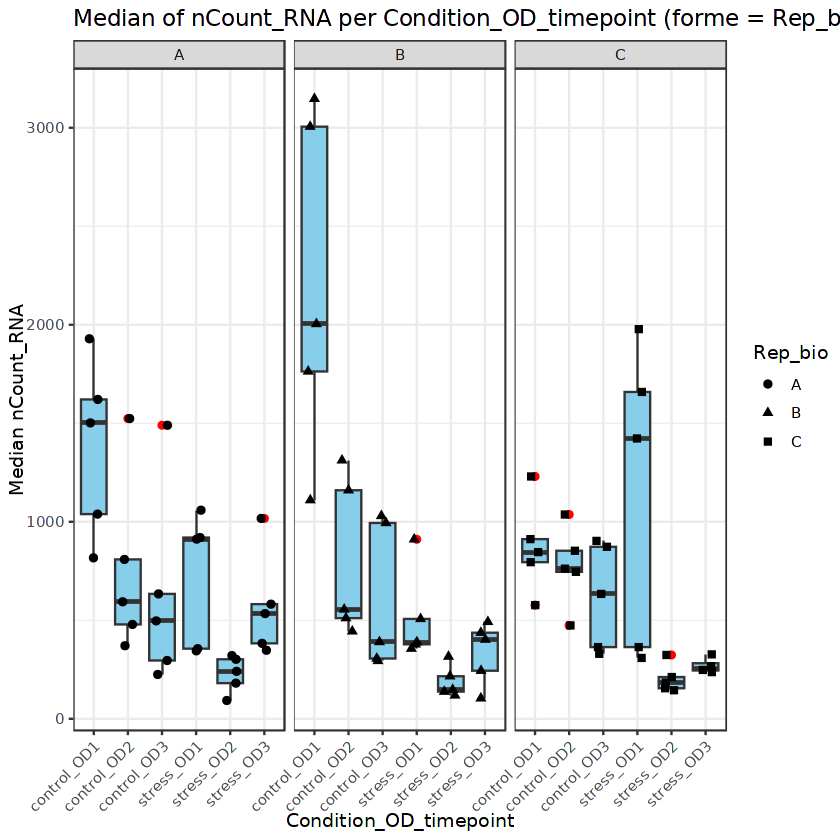

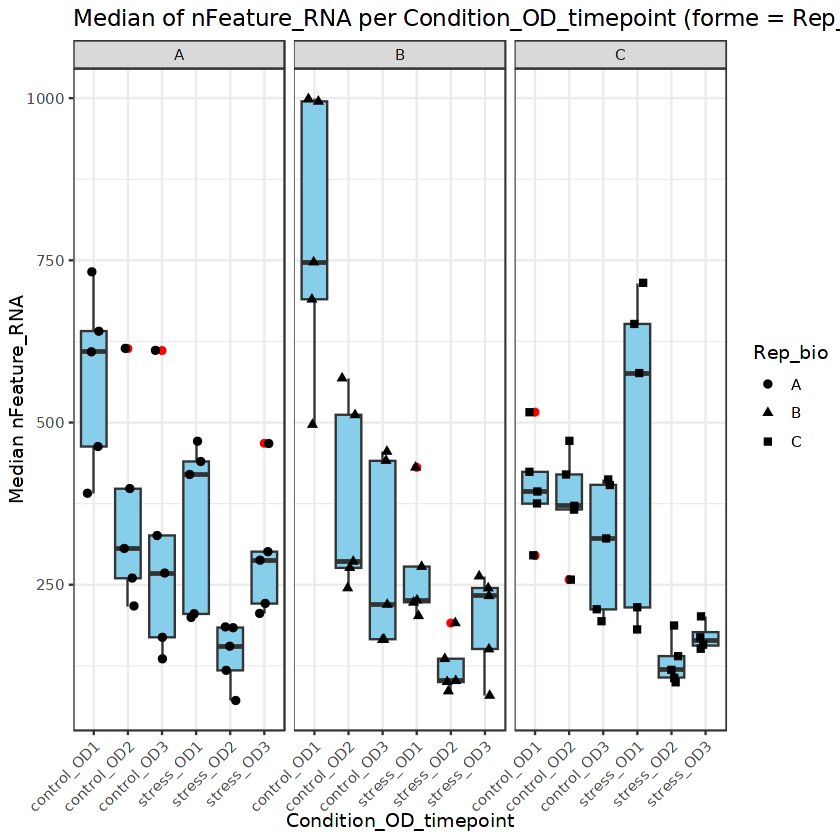

: 

In [ ]:
seurat_obj_f_CDS_5cells@meta.data %>%
  group_by(Condition_OD_timepoint, Sample_ID, Rep_bio) %>%
  summarise(median_nCount_RNA = median(nCount_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint, y = median_nCount_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(aes(shape = Rep_bio), width = 0.2, size = 2, color = "black") +
  theme_bw() +
  labs(
    title = "Median of nCount_RNA per Condition_OD_timepoint (forme = Rep_bio)",
    x = "Condition_OD_timepoint",
    y = "Median nCount_RNA",
    shape = "Rep_bio"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  facet_wrap(~Rep_bio, scales = "free_x")




seurat_obj_f_CDS_5cells@meta.data %>%
  group_by(Condition_OD_timepoint, Sample_ID, Rep_bio) %>%
  summarise(median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(x = Condition_OD_timepoint, y = median_nFeature_RNA)) +
  geom_boxplot(fill = "skyblue", outlier.color = "red") +
  geom_jitter(aes(shape = Rep_bio), width = 0.2, size = 2, color = "black") +
  theme_bw() +
  labs(
    title = "Median of nFeature_RNA per Condition_OD_timepoint (forme = Rep_bio)",
    x = "Condition_OD_timepoint",
    y = "Median nFeature_RNA",
    shape = "Rep_bio"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  facet_wrap(~Rep_bio, scales = "free_x")


# explanation about my analyse

-git , jupyter, docker env , conda , 
- trimm et starsolo sur cluster 
- metadata : serait bien de rajouter colums 
- convert to Anndata
single cell en local (3000 cellules seulement)



- fonctionalisation
  - graph qualité 
  - graph boxplot variation entre replicas
  - summarise
  - thresold
  
  - shiny app 
  - shiny in jupyter



- deux methodes choisi pour le filtrage :   
  - kuchina (60.000 cells) + rm doublets
  - Val thresold (3000 cells)
  - other knew-point... pas testé 


-Val : 
    - best features sur l'ensemble de matrices 
    - rm doublets 
    - best ncount / sur l'ensemble de matrices 
    - conserve only mRNA 
  
  => test post => voit un replica tech pas bon (pipetage maybe)
 
Question : DOL dans les 6 conditions : DO , Stress 

- considerer batch effet : rep tech, rep bio => creation variable rep 
rep bio peut ne pas etre consideré comme batch 


Integration globale :
alors batch est replica tech 


SCtransform, anchor
scvi sur python  




- voir solène comment choisi 3000 cells



# Other 

In [ ]:
# --- STATISTIQUES GLOBALES ---
meta_data <- seurat_obj_f_CDS@meta.data
counts_matrix <- GetAssayData(seurat_obj_f_CDS, layer = "counts")
ngene_total <- sum(rowSums(counts_matrix > 0) > 0)

global_stats <- tibble(
  Sample_ID = "Global",
  n_cells = ncol(counts_matrix),
  n_genes_detected = ngene_total,
  gene_detection_ratio = 1,
  sum_nCount_RNA = sum(meta_data$nCount_RNA, na.rm = TRUE),
  sum_nFeature_RNA = sum(meta_data$nFeature_RNA, na.rm = TRUE),
  min_nCount_RNA = min(meta_data$nCount_RNA, na.rm = TRUE),
  q1_nCount_RNA = quantile(meta_data$nCount_RNA, 0.25, na.rm = TRUE),
  median_nCount_RNA = median(meta_data$nCount_RNA, na.rm = TRUE),
  q3_nCount_RNA = quantile(meta_data$nCount_RNA, 0.75, na.rm = TRUE),
  max_nCount_RNA = max(meta_data$nCount_RNA, na.rm = TRUE),
  sd_nCount_RNA = sd(meta_data$nCount_RNA, na.rm = TRUE),
  min_nFeature_RNA = min(meta_data$nFeature_RNA, na.rm = TRUE),
  q1_nFeature_RNA = quantile(meta_data$nFeature_RNA, 0.25, na.rm = TRUE),
  mean_nFeature_RNA = mean(meta_data$nFeature_RNA, na.rm = TRUE),
  median_nFeature_RNA = median(meta_data$nFeature_RNA, na.rm = TRUE),
  q3_nFeature_RNA = quantile(meta_data$nFeature_RNA, 0.75, na.rm = TRUE),
  max_nFeature_RNA = max(meta_data$nFeature_RNA, na.rm = TRUE),
  sd_nFeature_RNA = sd(meta_data$nFeature_RNA, na.rm = TRUE)
)

# --- STATISTIQUES PAR GROUPE ---
meta_data$cell_id <- rownames(meta_data)

group_stats <- meta_data %>%
  group_by(Sample_ID) %>%
  group_split() %>%
  map_dfr(function(group_df) {
    cells <- group_df$cell_id
    sub_counts <- counts_matrix[, cells, drop = FALSE]
    n_genes_detected <- sum(rowSums(sub_counts > 0) > 0)
    
    tibble(
      Sample_ID = unique(group_df$Sample_ID),
      n_cells = nrow(group_df),
      n_genes_detected = n_genes_detected,
      gene_detection_ratio = n_genes_detected / ngene_total,
      sum_nCount_RNA = sum(group_df$nCount_RNA, na.rm = TRUE),
      sum_nFeature_RNA = sum(group_df$nFeature_RNA, na.rm = TRUE),
      min_nCount_RNA = min(group_df$nCount_RNA, na.rm = TRUE),
      q1_nCount_RNA = quantile(group_df$nCount_RNA, 0.25, na.rm = TRUE),
      median_nCount_RNA = median(group_df$nCount_RNA, na.rm = TRUE),
      q3_nCount_RNA = quantile(group_df$nCount_RNA, 0.75, na.rm = TRUE),
      max_nCount_RNA = max(group_df$nCount_RNA, na.rm = TRUE),
      sd_nCount_RNA = sd(group_df$nCount_RNA, na.rm = TRUE),
      min_nFeature_RNA = min(group_df$nFeature_RNA, na.rm = TRUE),
      q1_nFeature_RNA = quantile(group_df$nFeature_RNA, 0.25, na.rm = TRUE),
      mean_nFeature_RNA = mean(group_df$nFeature_RNA, na.rm = TRUE),
      median_nFeature_RNA = median(group_df$nFeature_RNA, na.rm = TRUE),
      q3_nFeature_RNA = quantile(group_df$nFeature_RNA, 0.75, na.rm = TRUE),
      max_nFeature_RNA = max(group_df$nFeature_RNA, na.rm = TRUE),
      sd_nFeature_RNA = sd(group_df$nFeature_RNA, na.rm = TRUE)
    )
  })

# Combiner si tu veux les deux ensemble :
combined_stats <- bind_rows(global_stats, group_stats)

combined_stats

In [ ]:
cat("Number and characteristics of cells in the filtered CDS Seurat object:", ncol(seurat_obj_f_CDS), "\n")

summary_stats_sample <- seurat_obj_f_CDS@meta.data |> 
group_by (Sample_ID) %>%
  summarise(
    n_cells = n(),
    sum_nCount_RNA = sum(nCount_RNA, na.rm = TRUE),               # <-- ajout ici
    min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
    q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
    median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
    q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
    max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
    sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
    min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
    q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
    mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
    median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
    q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
    max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
    sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE)
  )

summary_stats_sample

In [ ]:
cat("Number and caracteristics of cells in the original Seurat object:", ncol(seurat_obj), "\n")

summary_stats_sample <- seurat_obj@meta.data %>%
    summarise(
        n_cells = n(),
        sum_nCount_RNA = sum(nCount_RNA, na.rm = TRUE),
        min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE))

head(summary_stats_sample, 90)
# Save the summary statistics to a CSV file
# write.csv(summary_stats_sample, file = "summary_stats.csv", row.names = FALSE)

In [ ]:
generate_qc_plots <- function(
    seurat_obj,
    subtitle,
    group.by = "Condition_OD_timepoint",
    split.by = NULL,
    show.points = FALSE
) {
    # Vérification du paramètre obligatoire
    if (missing(subtitle) || is.null(subtitle) || subtitle == "") {
        stop("Le paramètre 'subtitle' est obligatoire.")
    }

    # Taille des points selon show.points
    pt.size.val <- ifelse(show.points, 1, 0)

    # p1 : Nombre de gènes par cellule
    p1 <- VlnPlot(seurat_obj,
        features = "nFeature_RNA",
        ncol = 1,
        pt.size = pt.size.val,
        group.by = group.by,
        raster = TRUE,
        layer = "counts"
    ) +
        labs(
            title = "Number of genes per cell",
            subtitle = subtitle,
            x = group.by,
            y = "Number of genes (nFeature_RNA)"
        ) +
        scale_y_continuous(limits = c(0, NA))

    # p2 : Nombre de counts par cellule
    p2 <- VlnPlot(seurat_obj,
        features = "nCount_RNA",
        ncol = 1,
        pt.size = pt.size.val,
        group.by = group.by,
        raster = TRUE,
        layer = "counts"
    ) +
        labs(
            title = "Number of counts per cell",
            subtitle = subtitle,
            x = group.by,
            y = "Number of counts (nCount_RNA)"
        ) +
        scale_y_continuous(limits = c(0, NA))

    # p3 : Scatter plot avec split facultatif
    p3 <- FeatureScatter(seurat_obj,
        feature1 = "nCount_RNA",
        feature2 = "nFeature_RNA",
        group.by = group.by,
        raster = TRUE,
        split.by = split.by
    )

    # p4 : RidgePlot avec annotation du nombre de cellules
    cell_counts_df <- seurat_obj@meta.data %>%
        group_by(across(all_of(group.by))) %>%
        summarise(n = n(), .groups = "drop")

    cell_counts_label <- paste0(cell_counts_df[[group.by]], " (n=", cell_counts_df$n, ")", collapse = "\n")

    p4 <- RidgePlot(seurat_obj,
        features = "nCount_RNA",
        group.by = group.by,
        log = TRUE
    ) +
        theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
        labs(
            title = paste("Distribution of UMIs per cell across conditions\n", cell_counts_label),
            subtitle = subtitle,
            x = "Number of UMIs per cell (log scale)",
            y = "Density"
        )

    # Combine p1 and p2
    combined_p1_p2 <- p1 / p2

    # Retour
    return(list(
        p1 = p1,
        p2 = p2,
        combined_p1_p2 = combined_p1_p2,
        scatter_p3 = p3,
        ridge_p4 = p4
    ))
}

In [177]:
library(Seurat)
library(ggplot2)
library(reshape2)
library(dplyr)

plot_gene_filtering_by_group <- function(seurat_obj,
                                         group_by,
                                         min_cells_vec,
                                         assay = "RNA",
                                         slot = "counts",
                                         save_plot = FALSE,
                                         filename = "gene_filtering_by_group",
                                         format = "pdf",  # or "png"
                                         width = 10,
                                         height = 6,
                                         dpi = 300) {

  # Extract metadata and counts
  meta_data <- seurat_obj@meta.data
  counts <- GetAssayData(seurat_obj, assay = assay, layer = slot)
  
  # Check group_by exists
  if (!(group_by %in% colnames(meta_data))) {
    stop(paste("Column", group_by, "not found in metadata."))
  }

  meta_data$cell_id <- colnames(seurat_obj)
  meta_data$group <- meta_data[[group_by]]

  # Prepare result dataframe
  group_levels <- unique(meta_data$group)
  result_df <- data.frame()

  for (group in group_levels) {
    # Subset cells and counts
    cells <- meta_data$cell_id[meta_data$group == group]
    sub_counts <- counts[, cells, drop = FALSE]

    # Keep only genes expressed in this group
    expressed_genes <- rowSums(sub_counts > 0) > 0
    expressed_counts <- sub_counts[expressed_genes, ]
    total_genes <- sum(expressed_genes)

    for (min_cells in min_cells_vec) {
      genes_kept <- sum(rowSums(expressed_counts > 0) >= min_cells)
      genes_removed <- total_genes - genes_kept

      result_df <- rbind(result_df, data.frame(
        Group = group,
        MinCells = min_cells,
        Type = "Retained genes",
        GeneCount = genes_kept,
        TotalGenes = total_genes
      ))

      result_df <- rbind(result_df, data.frame(
        Group = group,
        MinCells = min_cells,
        Type = "Removed genes",
        GeneCount = genes_removed,
        TotalGenes = total_genes
      ))
    }
  }

  # Plot
  p <- ggplot(result_df, aes(x = MinCells, y = GeneCount, color = Type)) +
    geom_line(size = 1) +
    geom_point(size = 2) +
    facet_wrap(~ Group, scales = "free_y") +
    labs(
      title = paste0("Effect of min_cells filtering by ", group_by),
      subtitle = paste("Each facet shows one group (based on", group_by, ")"),
      x = "Minimum number of cells",
      y = "Number of genes",
      color = "Gene category"
    ) +
    scale_color_manual(values = c("Removed genes" = "darkred", "Retained genes" = "steelblue")) +
    theme_minimal(base_size = 14)

  print(p)

  if (save_plot) {
    ggsave(paste0(filename, ".", format), plot = p, width = width, height = height, dpi = dpi)
  }

  return(invisible(p))
}

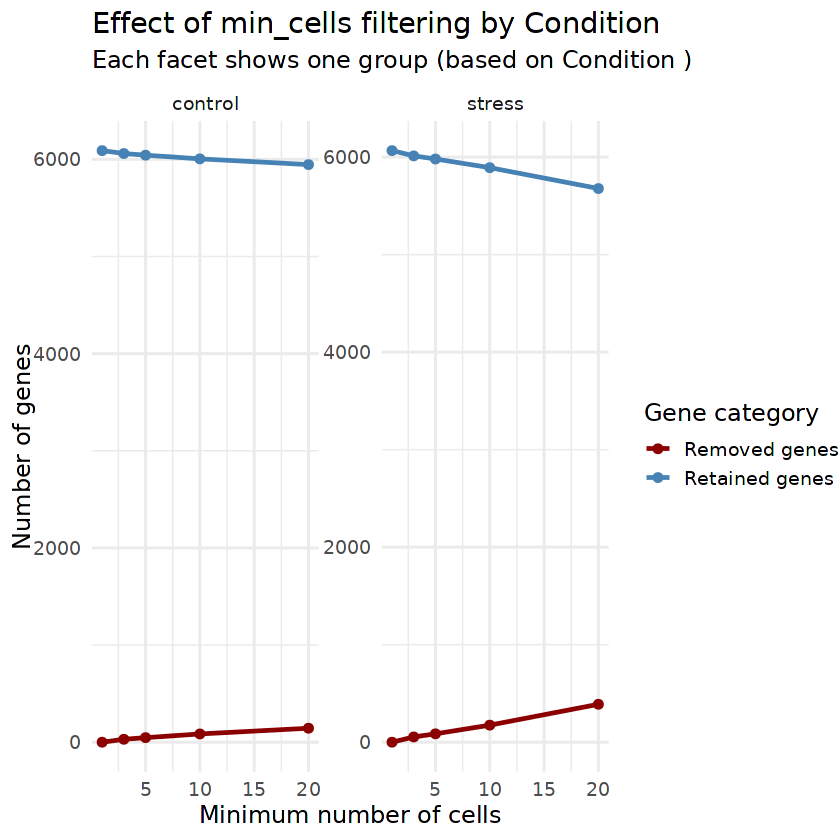

In [178]:
plot_gene_filtering_by_group(seurat_obj,
                             group_by = "Condition",
                             min_cells_vec = c(1, 3, 5, 10, 20),
                            # save_plot = TRUE,
                             filename = "gene_filtering_by_sample",
                             format = "png")

In [179]:
plot_gene_filtering_by_group <- function(seurat_obj,
                                         group_by,
                                         min_cells = 3,
                                         assay = "RNA",
                                         slot = "counts",
                                         filter_within_groups = TRUE,
                                         save_as = NULL,
                                         width = 8,
                                         height = 6,
                                         dpi = 300) {
  # Data
  counts <- GetAssayData(seurat_obj, assay = assay, slot = slot)
  metadata <- seurat_obj@meta.data
  metadata$cell_id <- colnames(seurat_obj)

  # Cell groups
  grouped_list <- metadata %>%
    group_by(.data[[group_by]]) %>%
    group_split()

  if (filter_within_groups) {
    # -- Local filtering per group --
    plot_data <- purrr::map_dfr(grouped_list, function(group_df) {
      group_id <- unique(group_df[[group_by]])
      cells <- group_df$cell_id
      sub_counts <- counts[, cells, drop = FALSE]

      n_genes_total <- sum(rowSums(sub_counts > 0) > 0)
      n_genes_filtered <- sum(rowSums(sub_counts > 0) >= min_cells)

      tibble(
        group = group_id,
        total_genes = n_genes_total,
        filtered_genes = n_genes_filtered,
        filter_type = "within_group"
      )
    })

  } else {
    # -- Global filtering first --
    genes_global_filtered <- rownames(counts)[rowSums(counts > 0) >= min_cells]

    plot_data <- purrr::map_dfr(grouped_list, function(group_df) {
      group_id <- unique(group_df[[group_by]])
      cells <- group_df$cell_id
      sub_counts <- counts[, cells, drop = FALSE]

      n_genes_total <- sum(rowSums(sub_counts > 0) > 0)
      n_genes_in_filtered_set <- sum(rowSums(sub_counts[genes_global_filtered, , drop = FALSE] > 0) > 0)

      tibble(
        group = group_id,
        total_genes = n_genes_total,
        filtered_genes = n_genes_in_filtered_set,
        filter_type = "global_filter"
      )
    })
  }

  # Plot
  p <- ggplot(plot_data, aes(x = group, y = filtered_genes)) +
    geom_bar(stat = "identity", fill = "#2C77B2") +
    labs(
      title = glue::glue("Number of genes passing filtering ({min_cells} cells) [{unique(plot_data$filter_type)}]"),
      x = group_by,
      y = "Number of genes"
    ) +
    theme_minimal(base_size = 14) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

  # Save plot
  if (!is.null(save_as)) {
    ggsave(save_as, plot = p, width = width, height = height, dpi = dpi)
  }

  return(p)
}

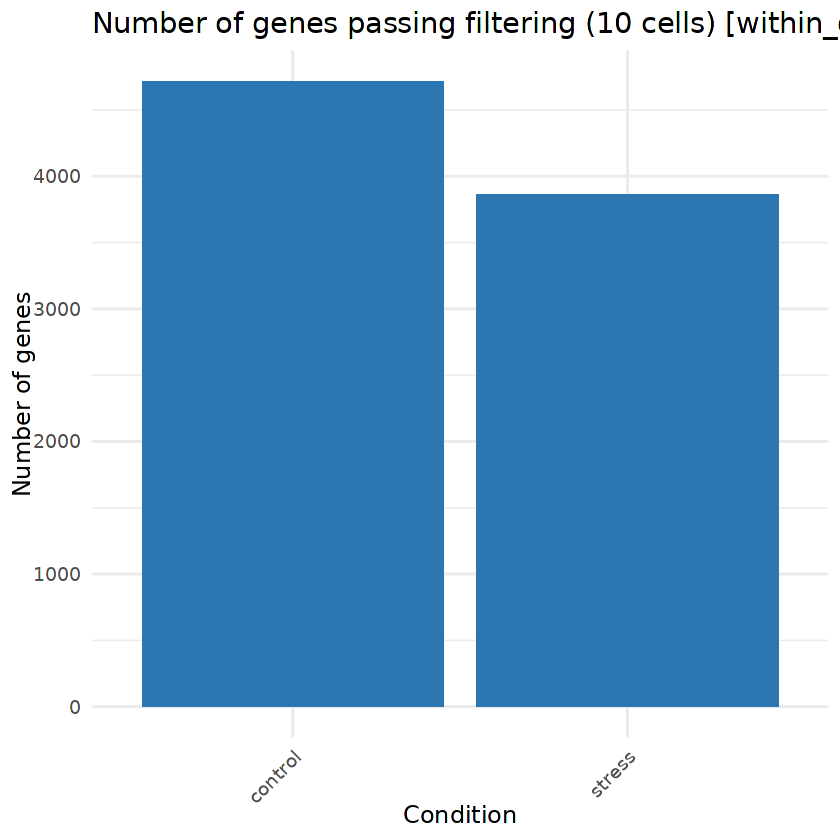

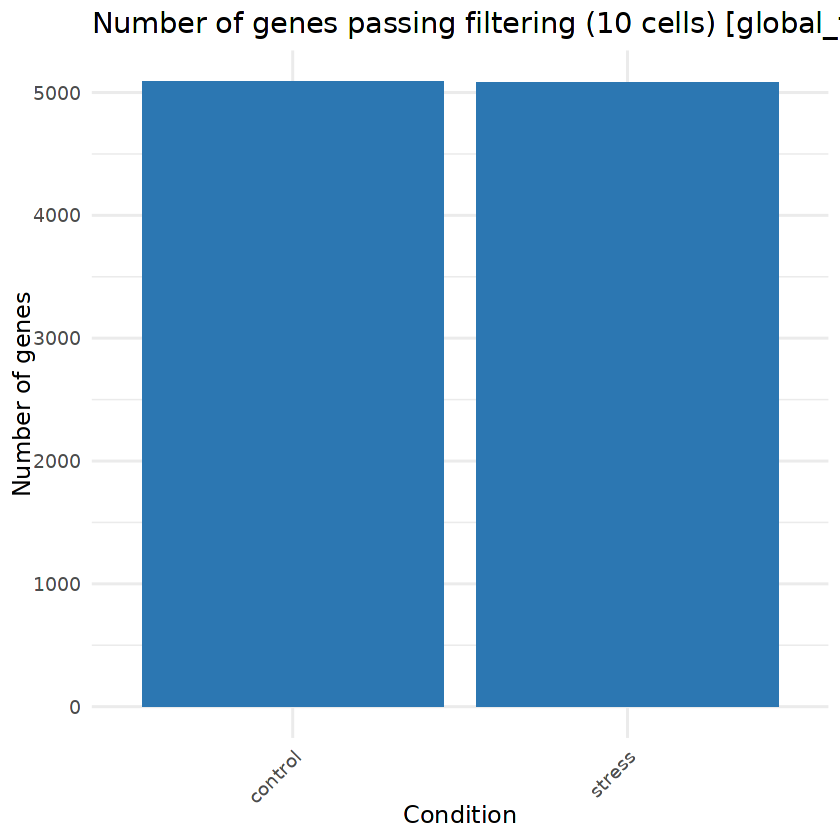

In [181]:
# Filtrage appliqué par groupe (comme actuellement)
plot_gene_filtering_by_group(seurat_obj_f_CDS, group_by = "Condition", min_cells = 10)

# Filtrage global appliqué une fois, puis visualisation par groupe
plot_gene_filtering_by_group(seurat_obj_f_CDS, group_by = "Condition", min_cells = 10, filter_within_groups = FALSE)

In [182]:
plot_gene_filtering_by_group <- function(seurat_obj,
                                         group_by,
                                         min_cells_vec,
                                         assay = "RNA",
                                         slot = "counts",
                                         filter_mode = c("within", "global"),
                                         save_plot = FALSE,
                                         filename = "gene_filtering_by_group",
                                         format = "pdf",
                                         width = 10,
                                         height = 6,
                                         dpi = 300) {

  filter_mode <- match.arg(filter_mode)

  # Extract metadata and counts
  meta_data <- seurat_obj@meta.data
  counts <- GetAssayData(seurat_obj, assay = assay, slot = slot)

  # Check group_by exists
  if (!(group_by %in% colnames(meta_data))) {
    stop(paste("Column", group_by, "not found in metadata."))
  }

  meta_data$cell_id <- colnames(seurat_obj)
  meta_data$group <- meta_data[[group_by]]
  group_levels <- unique(meta_data$group)

  result_df <- data.frame()

  if (filter_mode == "within") {
    # Filtrage min_cells dans chaque groupe indépendamment
    for (group in group_levels) {
      cells <- meta_data$cell_id[meta_data$group == group]
      sub_counts <- counts[, cells, drop = FALSE]

      expressed_genes <- rowSums(sub_counts > 0) > 0
      expressed_counts <- sub_counts[expressed_genes, , drop = FALSE]
      total_genes <- sum(expressed_genes)

      for (min_cells in min_cells_vec) {
        genes_kept <- sum(rowSums(expressed_counts > 0) >= min_cells)
        genes_removed <- total_genes - genes_kept

        result_df <- rbind(result_df, data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Retained genes",
          GeneCount = genes_kept,
          TotalGenes = total_genes
        ))

        result_df <- rbind(result_df, data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Removed genes",
          GeneCount = genes_removed,
          TotalGenes = total_genes
        ))
      }
    }
  } else if (filter_mode == "global") {
    # Filtrage min_cells global sur toutes les cellules
    for (min_cells in min_cells_vec) {
      genes_global_kept <- rowSums(counts > 0) >= min_cells
      genes_global <- rownames(counts)[genes_global_kept]

      for (group in group_levels) {
        cells <- meta_data$cell_id[meta_data$group == group]
        sub_counts <- counts[, cells, drop = FALSE]

        total_genes_in_group <- sum(rowSums(sub_counts > 0) > 0)
        genes_kept_in_group <- sum(rowSums(sub_counts[genes_global, , drop = FALSE] > 0) > 0)
        genes_removed_in_group <- total_genes_in_group - genes_kept_in_group

        result_df <- rbind(result_df, data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Retained genes",
          GeneCount = genes_kept_in_group,
          TotalGenes = total_genes_in_group
        ))

        result_df <- rbind(result_df, data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Removed genes",
          GeneCount = genes_removed_in_group,
          TotalGenes = total_genes_in_group
        ))
      }
    }
  }

  p <- ggplot(result_df, aes(x = MinCells, y = GeneCount, color = Type)) +
    geom_line(size = 1) +
    geom_point(size = 2) +
    facet_wrap(~ Group, scales = "free_y") +
    labs(
      title = paste0("Effect of min_cells filtering by ", group_by, " [", filter_mode, " mode]"),
      subtitle = paste("Each facet shows one group (based on", group_by, ")"),
      x = "Minimum number of cells",
      y = "Number of genes",
      color = "Gene category"
    ) +
    scale_color_manual(values = c("Removed genes" = "darkred", "Retained genes" = "steelblue")) +
    theme_minimal(base_size = 14)

  print(p)

  if (save_plot) {
    ggsave(paste0(filename, ".", format), plot = p, width = width, height = height, dpi = dpi)
  }

  return(invisible(p))
}

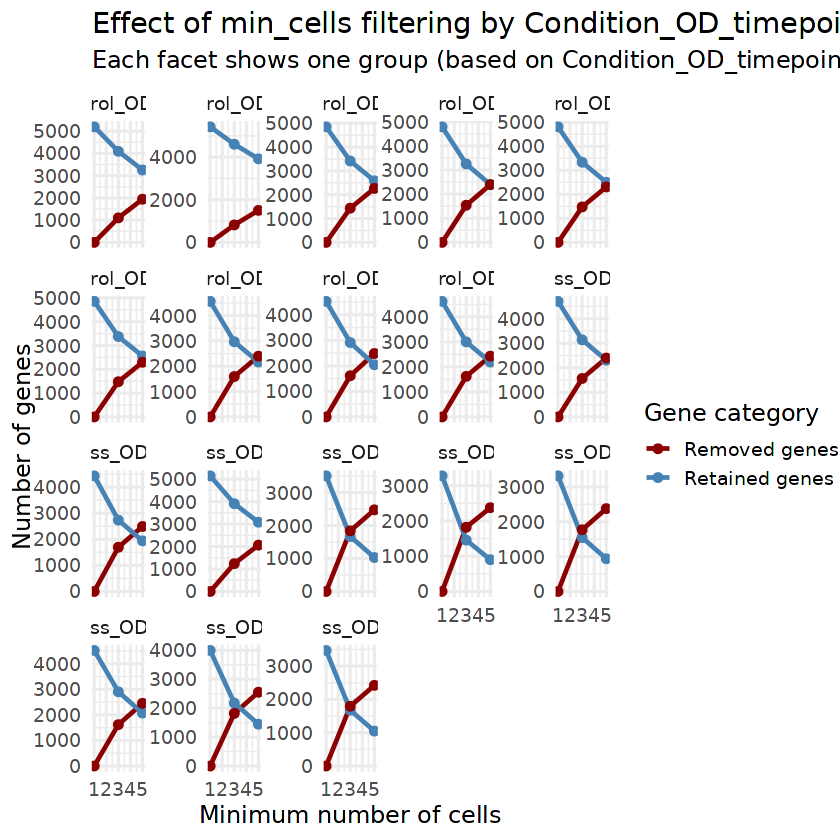

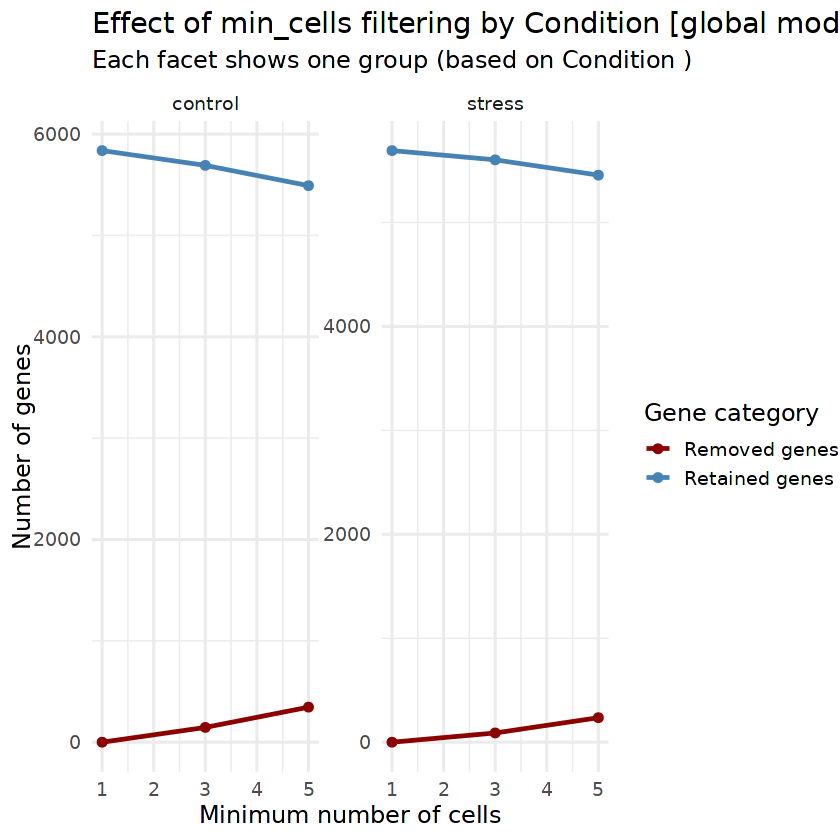

In [188]:
# Filtrage dans chaque groupe
plot_gene_filtering_by_group(seurat_obj_f_CDS, 
group_by = "Condition_OD_timepoint_Rep_bio", 
min_cells_vec = c(1,3,5), filter_mode = "within")

# Filtrage global, puis comparaison par groupe
plot_gene_filtering_by_group(seurat_obj_f_CDS, group_by = "Condition", min_cells_vec = c(1,3,5), filter_mode = "global")

In [189]:
library(Seurat)
library(ggplot2)
library(dplyr)
library(patchwork)

plot_gene_filtering_by_group <- function(seurat_obj,
                                         group_by = NULL,
                                         min_cells_vec,
                                         assay = "RNA",
                                         slot = "counts",
                                         filter_mode = c("within", "global"),
                                         save_plot = FALSE,
                                         filename = "gene_filtering_by_group",
                                         format = "pdf",
                                         width = 10,
                                         height = 6,
                                         dpi = 300,
                                         facets_per_plot = 6) {
  filter_mode <- match.arg(filter_mode)

  # Extract metadata and counts
  meta_data <- seurat_obj@meta.data
  counts <- GetAssayData(seurat_obj, assay = assay, slot = slot)

  meta_data$cell_id <- colnames(seurat_obj)

  if (!is.null(group_by)) {
    if (!(group_by %in% colnames(meta_data))) {
      stop(paste("Column", group_by, "not found in metadata."))
    }
    meta_data$group <- meta_data[[group_by]]
    group_levels <- unique(meta_data$group)
  } else {
    group_levels <- "All"
    meta_data$group <- "All"
  }

  result_list <- list()

  if (filter_mode == "within") {
    for (group in group_levels) {
      cells <- meta_data$cell_id[meta_data$group == group]
      sub_counts <- counts[, cells, drop = FALSE]

      expressed_genes <- rowSums(sub_counts > 0) > 0
      expressed_counts <- sub_counts[expressed_genes, , drop = FALSE]
      total_genes <- sum(expressed_genes)

      for (min_cells in min_cells_vec) {
        genes_kept <- sum(rowSums(expressed_counts > 0) >= min_cells)
        genes_removed <- total_genes - genes_kept

        result_list[[length(result_list)+1]] <- data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Retained genes",
          GeneCount = genes_kept,
          TotalGenes = total_genes
        )

        result_list[[length(result_list)+1]] <- data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Removed genes",
          GeneCount = genes_removed,
          TotalGenes = total_genes
        )
      }
    }
  } else if (filter_mode == "global") {
    for (min_cells in min_cells_vec) {
      genes_global_kept <- rowSums(counts > 0) >= min_cells
      genes_global <- rownames(counts)[genes_global_kept]

      for (group in group_levels) {
        cells <- meta_data$cell_id[meta_data$group == group]
        sub_counts <- counts[, cells, drop = FALSE]

        total_genes_in_group <- sum(rowSums(sub_counts > 0) > 0)
        genes_kept_in_group <- sum(rowSums(sub_counts[genes_global, , drop = FALSE] > 0) > 0)
        genes_removed_in_group <- total_genes_in_group - genes_kept_in_group

        result_list[[length(result_list)+1]] <- data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Retained genes",
          GeneCount = genes_kept_in_group,
          TotalGenes = total_genes_in_group
        )

        result_list[[length(result_list)+1]] <- data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Removed genes",
          GeneCount = genes_removed_in_group,
          TotalGenes = total_genes_in_group
        )
      }
    }
  }

  result_df <- bind_rows(result_list)

  # Si une seule "Group" → pas de facette
  if (length(unique(result_df$Group)) == 1) {
    p <- ggplot(result_df, aes(x = MinCells, y = GeneCount, color = Type)) +
      geom_line(size = 1) +
      geom_point(size = 2) +
      labs(
        title = paste0("Effect of min_cells filtering [", filter_mode, " mode]"),
        x = "Minimum number of cells",
        y = "Number of genes",
        color = "Gene category"
      ) +
      scale_color_manual(values = c("Removed genes" = "darkred", "Retained genes" = "steelblue")) +
      theme_minimal(base_size = 14)
    
    print(p)
    if (save_plot) {
      ggsave(paste0(filename, ".", format), plot = p, width = width, height = height, dpi = dpi)
    }
    return(invisible(p))
  }

  # Plusieurs groupes → facet, split si trop
  group_list <- split(unique(result_df$Group), ceiling(seq_along(unique(result_df$Group)) / facets_per_plot))
  plot_list <- list()

  for (i in seq_along(group_list)) {
    subset_df <- result_df %>% filter(Group %in% group_list[[i]])
    p <- ggplot(subset_df, aes(x = MinCells, y = GeneCount, color = Type)) +
      geom_line(size = 1) +
      geom_point(size = 2) +
      facet_wrap(~ Group, ncol = 2, scales = "fixed") +
      labs(
        title = paste0("Effect of min_cells filtering by group [", filter_mode, "] - part ", i),
        x = "Minimum number of cells",
        y = "Number of genes",
        color = "Gene category"
      ) +
      scale_color_manual(values = c("Removed genes" = "darkred", "Retained genes" = "steelblue")) +
      theme_minimal(base_size = 14)
    
    print(p)
    if (save_plot) {
      ggsave(paste0(filename, "_part", i, ".", format), plot = p, width = width, height = height, dpi = dpi)
    }

    plot_list[[i]] <- p
  }

  return(invisible(plot_list))
}

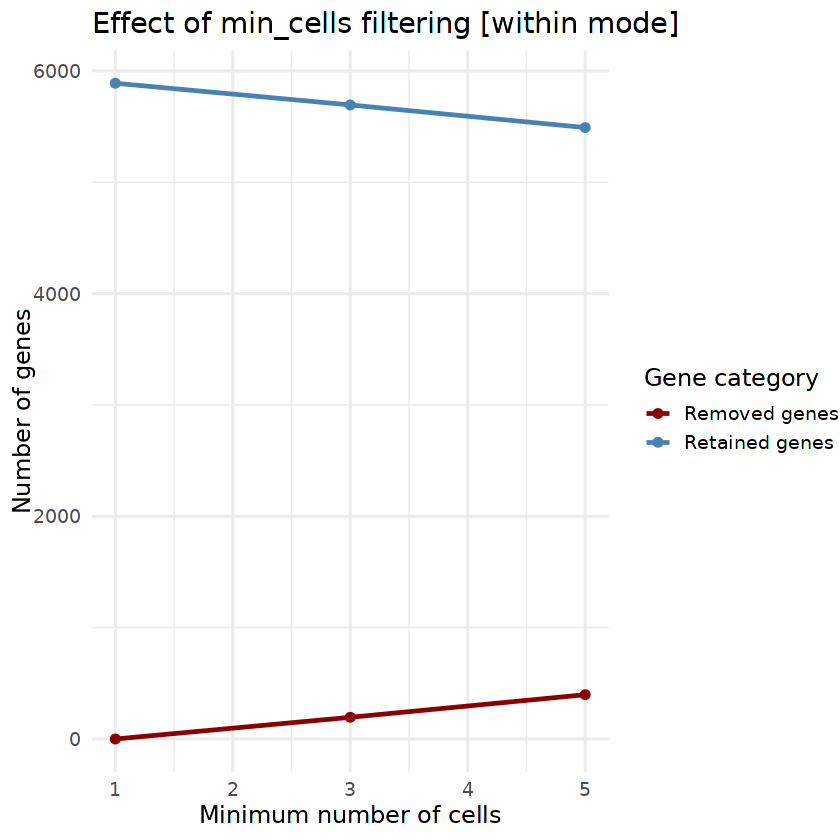

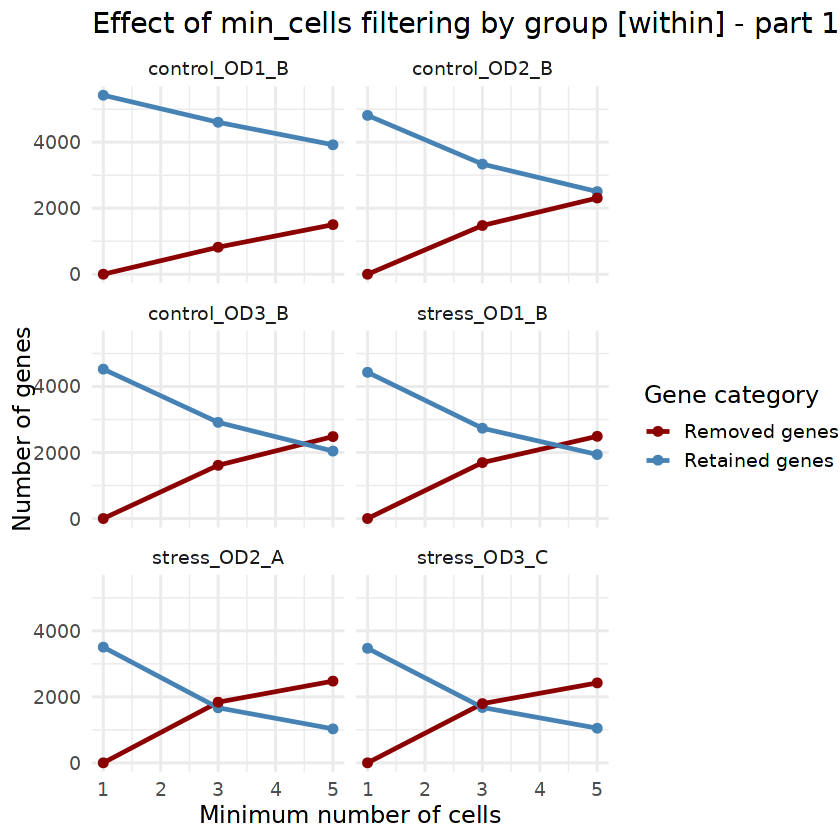

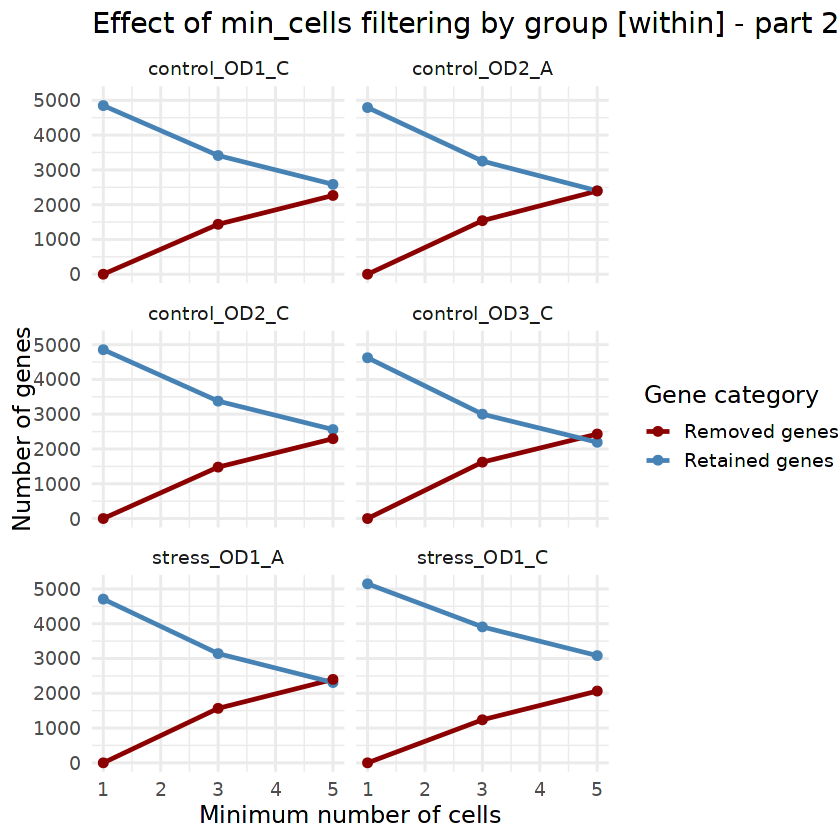

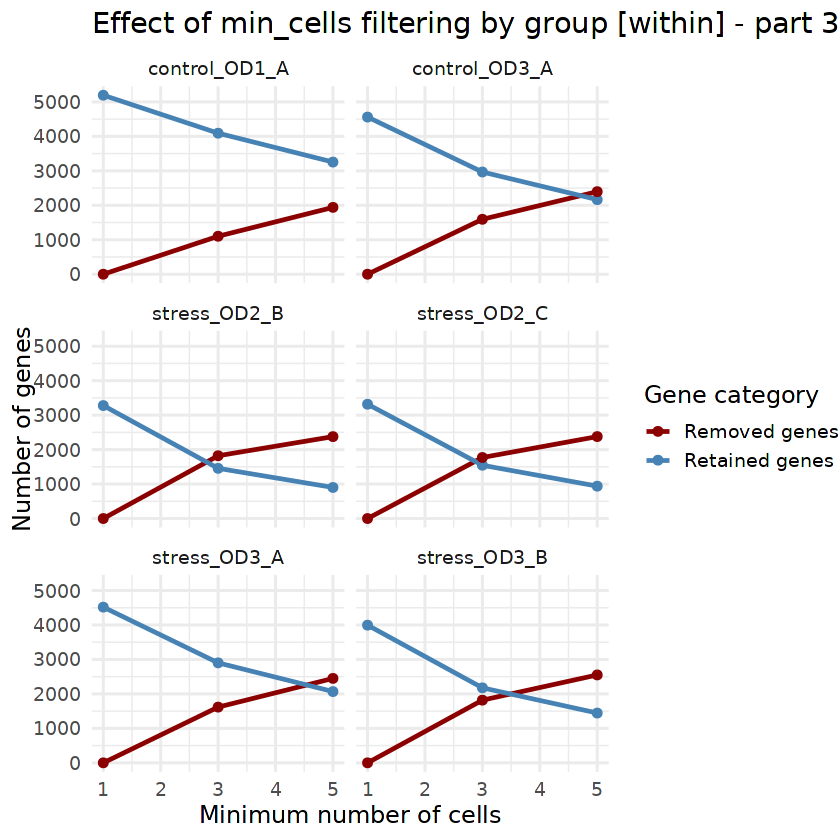

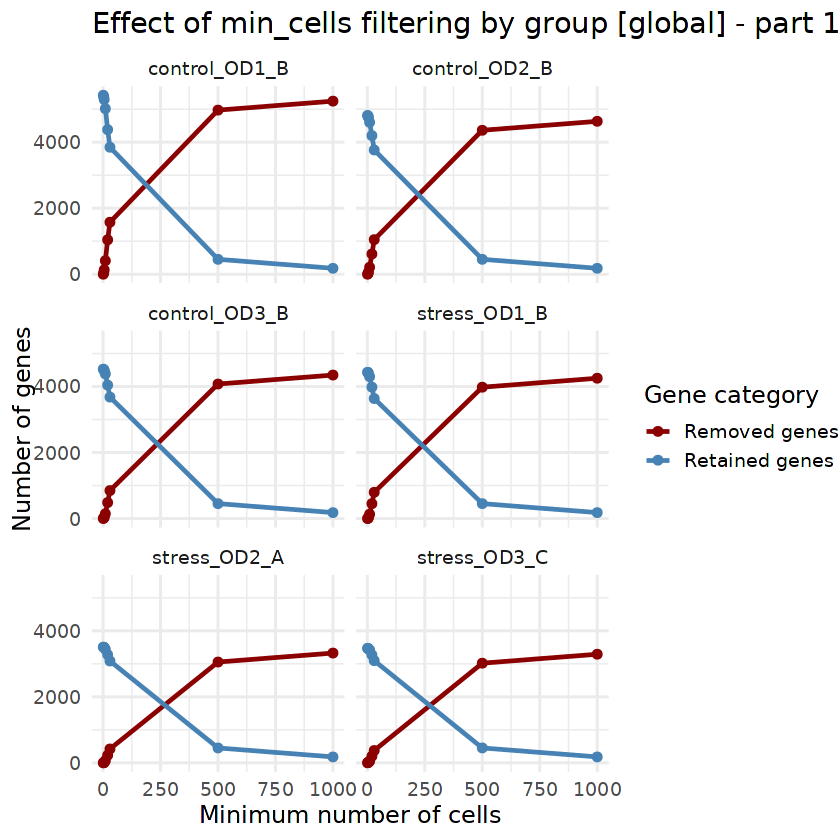

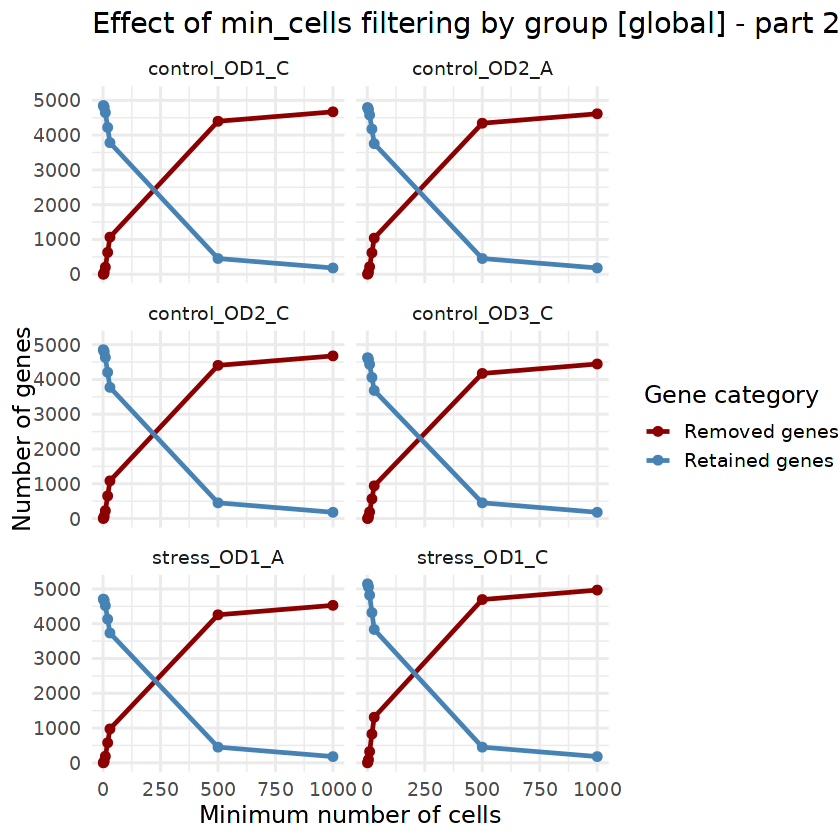

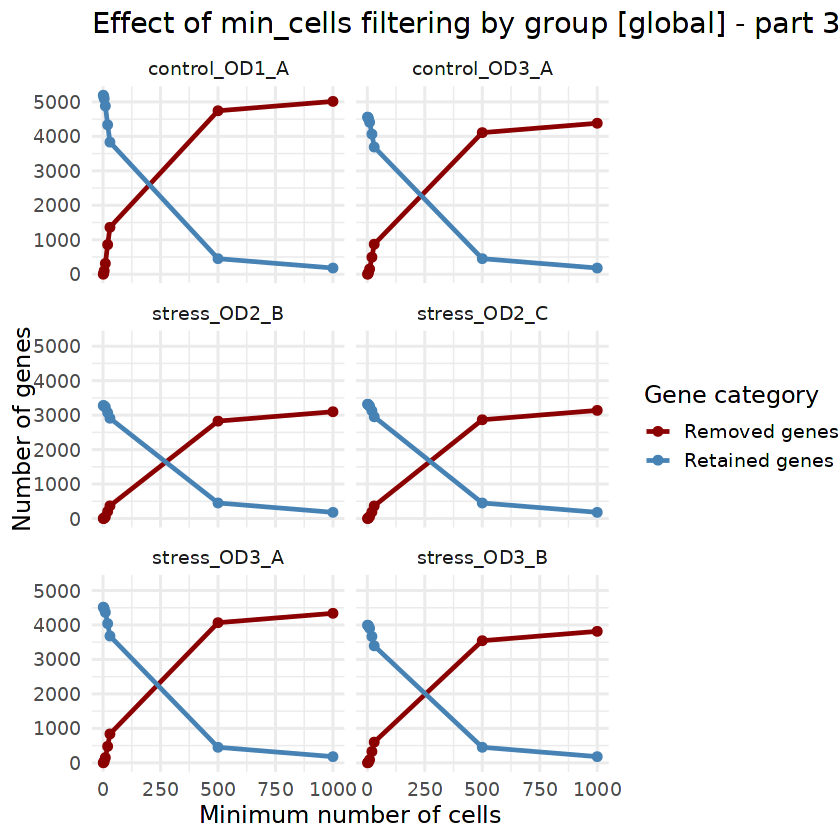

In [192]:
# Aucun groupement (toutes les cellules ensemble)
plot_gene_filtering_by_group(seurat_obj_f_CDS, min_cells_vec = c(1, 3, 5))

# Groupement avec filtre par groupe
plot_gene_filtering_by_group(seurat_obj_f_CDS, group_by = "Condition_OD_timepoint_Rep_bio", min_cells_vec = c(1, 3, 5), filter_mode = "within")

# Groupement avec filtre global
plot_gene_filtering_by_group(seurat_obj_f_CDS, group_by = "Condition_OD_timepoint_Rep_bio", min_cells_vec = c(1, 3, 5, 10, 20, 30, 500, 1000), filter_mode = "global")

In [193]:
plot_gene_filtering_by_group <- function(seurat_obj,
                                         group_by = NULL,
                                         min_cells_vec,
                                         assay = "RNA",
                                         slot = "counts",
                                         filter_mode = c("within", "global"),
                                         save_plot = FALSE,
                                         filename = "gene_filtering_by_group",
                                         format = "pdf",
                                         width = 10,
                                         height = 6,
                                         dpi = 300,
                                         facets_per_plot = 6,
                                         show_percent = TRUE,
                                         return_data = FALSE) {

  filter_mode <- match.arg(filter_mode)

  meta_data <- seurat_obj@meta.data
  counts <- GetAssayData(seurat_obj, assay = assay, slot = slot)
  meta_data$cell_id <- colnames(seurat_obj)

  if (!is.null(group_by)) {
    if (!(group_by %in% colnames(meta_data))) {
      stop(paste("Column", group_by, "not found in metadata."))
    }
    meta_data$group <- meta_data[[group_by]]
    group_levels <- unique(meta_data$group)
  } else {
    group_levels <- "All"
    meta_data$group <- "All"
  }

  result_list <- list()

  if (filter_mode == "within") {
    for (group in group_levels) {
      cells <- meta_data$cell_id[meta_data$group == group]
      sub_counts <- counts[, cells, drop = FALSE]

      expressed_genes <- rowSums(sub_counts > 0) > 0
      expressed_counts <- sub_counts[expressed_genes, , drop = FALSE]
      total_genes <- sum(expressed_genes)

      for (min_cells in min_cells_vec) {
        genes_kept <- sum(rowSums(expressed_counts > 0) >= min_cells)
        genes_removed <- total_genes - genes_kept

        result_list[[length(result_list)+1]] <- data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Retained genes",
          GeneCount = genes_kept,
          TotalGenes = total_genes,
          PercentRetained = round(100 * genes_kept / total_genes, 1)
        )

        result_list[[length(result_list)+1]] <- data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Removed genes",
          GeneCount = genes_removed,
          TotalGenes = total_genes,
          PercentRetained = round(100 * genes_kept / total_genes, 1)
        )
      }
    }
  } else if (filter_mode == "global") {
    for (min_cells in min_cells_vec) {
      genes_global_kept <- rowSums(counts > 0) >= min_cells
      genes_global <- rownames(counts)[genes_global_kept]

      for (group in group_levels) {
        cells <- meta_data$cell_id[meta_data$group == group]
        sub_counts <- counts[, cells, drop = FALSE]

        total_genes_in_group <- sum(rowSums(sub_counts > 0) > 0)
        genes_kept_in_group <- sum(rowSums(sub_counts[genes_global, , drop = FALSE] > 0) > 0)
        genes_removed_in_group <- total_genes_in_group - genes_kept_in_group

        result_list[[length(result_list)+1]] <- data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Retained genes",
          GeneCount = genes_kept_in_group,
          TotalGenes = total_genes_in_group,
          PercentRetained = round(100 * genes_kept_in_group / total_genes_in_group, 1)
        )

        result_list[[length(result_list)+1]] <- data.frame(
          Group = group,
          MinCells = min_cells,
          Type = "Removed genes",
          GeneCount = genes_removed_in_group,
          TotalGenes = total_genes_in_group,
          PercentRetained = round(100 * genes_kept_in_group / total_genes_in_group, 1)
        )
      }
    }
  }

  result_df <- bind_rows(result_list)

  # Plot ----
  make_plot <- function(data_subset, title_suffix = "") {
    p <- ggplot(data_subset, aes(x = MinCells, y = GeneCount, color = Type)) +
      geom_line(size = 1) +
      geom_point(size = 2) +
      labs(
        title = paste0("Effect of min_cells filtering ", title_suffix),
        x = "Minimum number of cells",
        y = "Number of genes",
        color = "Gene category"
      ) +
      scale_color_manual(values = c("Removed genes" = "darkred", "Retained genes" = "steelblue")) +
      theme_minimal(base_size = 14)

    if (show_percent) {
      percent_labels <- data_subset %>% 
        filter(Type == "Retained genes") %>% 
        mutate(label = paste0(PercentRetained, "%"))
      
      p <- p + 
        geom_text(data = percent_labels,
                  aes(label = label),
                  vjust = -0.8, size = 3.5, show.legend = FALSE)
    }
    return(p)
  }

  if (length(unique(result_df$Group)) == 1) {
    p <- make_plot(result_df, paste0("[", filter_mode, " mode]"))
    print(p)
    if (save_plot) {
      ggsave(paste0(filename, ".", format), plot = p, width = width, height = height, dpi = dpi)
    }
    if (return_data) {
      return(invisible(list(plot = p, data = result_df)))
    } else {
      return(invisible(p))
    }
  }

  group_list <- split(unique(result_df$Group), ceiling(seq_along(unique(result_df$Group)) / facets_per_plot))
  plot_list <- list()

  for (i in seq_along(group_list)) {
    subset_df <- result_df %>% filter(Group %in% group_list[[i]])
    p <- make_plot(subset_df, paste0("[", filter_mode, " mode] - part ", i)) +
      facet_wrap(~ Group, ncol = 2, scales = "fixed")

    print(p)
    if (save_plot) {
      ggsave(paste0(filename, "_part", i, ".", format), plot = p, width = width, height = height, dpi = dpi)
    }
    plot_list[[i]] <- p
  }

  if (return_data) {
    return(invisible(list(plots = plot_list, data = result_df)))
  } else {
    return(invisible(plot_list))
  }
}

In [194]:
# Sans groupement
out <- plot_gene_filtering_by_group(seurat_obj_f_CDS, min_cells_vec = c(1,3,5), return_data = TRUE)

# Avec groupement
out <- plot_gene_filtering_by_group(seurat_obj,
                                    group_by = "Condition",
                                    min_cells_vec = c(1,3,5),
                                    filter_mode = "within",
                                    return_data = TRUE)

# Accès aux données
head(out$data)

# Accès aux graphes (si plusieurs facets)
out$plots[[1]]

: 

In [ ]:
library(Seurat)

filter_seurat_genes_by_group <- function(seurat_obj,
                                         min_cells = 3,
                                         group_by = NULL,
                                         logic = c("within", "across"),
                                         assay = "RNA",
                                         slot = "counts",
                                         drop_empty_cells = TRUE,
                                         return_data = FALSE) {
  logic <- match.arg(logic)

  # Get counts
  counts <- GetAssayData(seurat_obj, assay = assay, slot = slot)

  # Sanity check
  if (!is.null(group_by) && !(group_by %in% colnames(seurat_obj@meta.data))) {
    stop(paste("Column", group_by, "not found in metadata."))
  }

  if (is.null(group_by) || logic == "across") {
    # Simple filtering across all cells
    keep_genes <- rowSums(counts > 0) >= min_cells
    message(sprintf("Retaining %d genes out of %d (%.1f%%)",
                    sum(keep_genes), length(keep_genes),
                    100 * sum(keep_genes) / length(keep_genes)))
  } else if (logic == "within") {
    # Filtering within each group
    meta_data <- seurat_obj@meta.data
    meta_data$group <- meta_data[[group_by]]
    group_levels <- unique(meta_data$group)

    keep_matrix <- matrix(FALSE, nrow = nrow(counts), ncol = length(group_levels))
    rownames(keep_matrix) <- rownames(counts)
    colnames(keep_matrix) <- group_levels

    for (group in group_levels) {
      cells <- rownames(meta_data[meta_data$group == group, ])
      if (length(cells) == 0) next
      group_counts <- counts[, cells, drop = FALSE]
      keep_matrix[, group] <- rowSums(group_counts > 0) >= min_cells
    }

    keep_genes <- rowSums(keep_matrix) > 0
    message(sprintf("Retaining %d genes out of %d across all groups (%.1f%%)",
                    sum(keep_genes), length(keep_genes),
                    100 * sum(keep_genes) / length(keep_genes)))
  }

  # Subset Seurat object by genes
  seurat_obj_filtered <- subset(seurat_obj, features = rownames(counts)[keep_genes])

  # Drop empty cells
  if (drop_empty_cells) {
    counts_filtered <- GetAssayData(seurat_obj_filtered, assay = assay, slot = slot)
    non_empty_cells <- colSums(counts_filtered > 0) > 0
    n_removed <- sum(!non_empty_cells)
    message(sprintf("Removed %d empty cell(s)", n_removed))

    seurat_obj_filtered <- subset(seurat_obj_filtered, cells = colnames(seurat_obj_filtered)[non_empty_cells])
  }

  # Optionally return filtered object + log info
  if (return_data) {
    return(list(
      seurat_obj = seurat_obj_filtered,
      genes_retained = sum(keep_genes),
      genes_total = length(keep_genes),
      cells_retained = ncol(seurat_obj_filtered),
      cells_total = ncol(seurat_obj)
    ))
  } else {
    return(seurat_obj_filtered)
  }
}

In [ ]:
# Filtrage across toutes les cellules
filtered_obj <- filter_seurat_genes_by_group(seurat_obj, min_cells = 5)

# Filtrage au sein de chaque groupe (ex: condition), et drop cellules silencieuses
filtered_obj <- filter_seurat_genes_by_group(seurat_obj, min_cells = 5, group_by = "condition", logic = "within")

# Avec retour d'information
res <- filter_seurat_genes_by_group(seurat_obj, min_cells = 5, group_by = "condition", logic = "within", return_data = TRUE)
str(res)